# Table of Contents

**Does Financial News Sentiment Improve Gold Return Prediction During Market Stress?**  
*Machine Learning for Portfolio Management and Trading*

This notebook presents the complete research workflow, from data collection to out-of-sample forecasting, trading backtests, and the final scientific conclusion. Click a phase to jump to it.

### [Phase 1 — Data Collection and Feasibility Audit](#phase-1)
*Sections 1–12* — News headlines, gold futures, VIX, GPR, data coverage and sample selection.

### [Phase 2 — Financial Features and Forecasting Target](#phase-2)
*Sections 13–25* — Future returns, financial indicators, chronological alignment and leakage checks.

### [Phase 3 — News Sentiment and NLP Feature Engineering](#phase-3)
*Sections 26–42* — Annotated sentiment, FinBERT, TF-IDF and daily NLP indicators.

### [Phase 4 — Out-of-Sample Gold Return Prediction](#phase-4)
*Sections 43–55* — Benchmarks, Elastic Net, XGBoost and the incremental predictive value of news.

### [Phase 5 — Robustness, Market Stress and Trading Backtests](#phase-5)
*Sections 56–67* — VIX regimes, bootstrap, trading strategies, transaction costs and risk metrics.

### [Phase 6 — Final Research Synthesis and Reproducibility](#phase-6)
*Sections 68–78* — Main findings, hypotheses, limitations, references and final checks.

---

**Evaluation periods:** Training (2011–2015) · Validation (2016) · Final test (2017–2018).

---


# Phase 1 — Data Collection and Feasibility Audit
### Does news sentiment improve the prediction of gold returns during market stress?

**Goal.** This notebook collects the initial news and market datasets, checks their quality, and assesses whether they can support a credible out-of-sample forecasting exercise. **No machine-learning model is trained in this phase.**

**Research question.** Does financial and geopolitical news sentiment contain incremental information about future gold returns beyond conventional market variables, especially during stress periods?

**Important limitation.** Headline dates do not specify exact publication times. We must not assume a headline dated *t* was available at the trading close on *t*. The final forecasting stage will adopt a conservative timing convention and report this limitation.

**Dataset references.** [Gold news corpus](https://huggingface.co/datasets/SaguaroCapital/sentiment-analysis-in-commodity-market-gold) · [Gold futures](https://finance.yahoo.com/quote/GC=F/history/) · [VIX](https://fred.stlouisfed.org/series/VIXCLS) · [GPR](https://www.matteoiacoviello.com/gpr.htm).

## 1. Setup
We use standard Python libraries for table manipulation and visualization, `datasets` to fetch the Hugging Face corpus, and `yfinance` for gold futures prices. `xlrd` is needed because the daily GPR file is distributed in the older `.xls` Excel format.

Run the installation cell **once** if packages are missing. Afterwards, restart the kernel if necessary. The code is deliberately simple; it requires an internet connection on the first run.

In [ ]:
import sys
print(sys.executable)

In [ ]:
import sys, subprocess, importlib, importlib.util

if sys.version_info < (3, 9):
    raise RuntimeError("Python 3.9 ou plus récent requis.")

# nom de l'import -> nom du paquet pip
NEEDED = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "seaborn": "seaborn", "requests": "requests", "openpyxl": "openpyxl",
    "xlrd": "xlrd", "scipy": "scipy", "sklearn": "scikit-learn",
    "yfinance": "yfinance", "datasets": "datasets",
    "transformers": "transformers", "torch": "torch",
}

missing = [pip for imp, pip in NEEDED.items() if importlib.util.find_spec(imp) is None]

if missing:
    print("Installation de :", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)
    importlib.invalidate_caches()
    print("✅ Installation terminée.")
else:
    print("✅ Tous les paquets sont déjà présents.")

In [1]:
# 2) Imports (on arrive ici seulement si tout est déjà aux bonnes versions)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import yfinance as yf
from datasets import load_dataset

print("numpy", np.__version__, "| pandas", pd.__version__)

sns.set_theme(style="whitegrid")
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
START_DATE = "2000-01-01"
END_DATE = "2026-10-31"  # borne de fin exclusive pour yfinance
print("Data folder:", DATA_DIR.resolve())

/Users/mac/anaconda3/envs/jupyter_clean/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


numpy 1.26.4 | pandas 2.2.3
Data folder: /Users/mac/projet_ml_trading/data


In [2]:
import importlib.metadata as md
for p in ["pandas", "numpy", "matplotlib", "seaborn", "datasets", "yfinance", "openpyxl", "xlrd", "requests", "pyarrow" , "curl_cffi"]:
    print(f"{p:12s} {md.version(p)}")

pandas       2.2.3
numpy        1.26.4
matplotlib   3.9.4
seaborn      0.13.2
datasets     2.19.2
yfinance     1.7.0
openpyxl     3.1.5
xlrd         2.0.2
requests     2.34.2
pyarrow      14.0.2
curl_cffi    0.16.3


## 2. Download and inspect gold news
The source corpus contains 10,570 manually annotated headlines over approximately 2000–2021. Its original `train` and `test` partitions are designed for **text classification**, not time-series forecasting. We combine them and later perform our own chronological splits.

The dataset provides `Dates`, `News`, `URL`, `Price Sentiment`, `Past Information`, and `Future Information`, among other fields. We preserve all original labels for auditing. [Source: dataset card](https://huggingface.co/datasets/SaguaroCapital/sentiment-analysis-in-commodity-market-gold).

In [3]:
# ============================================================
# Chargement du dataset : sentiment analysis, news du marché de l'or
# ============================================================
import logging

import pandas as pd
from datasets import load_dataset

logging.getLogger("huggingface_hub.utils._http").setLevel(logging.ERROR)

DATASET_NAME = "SaguaroCapital/sentiment-analysis-in-commodity-market-gold"

dataset = load_dataset(DATASET_NAME)
news = pd.concat(
    [dataset[split].to_pandas().assign(split=split) for split in dataset.keys()],
    ignore_index=True,
)

print("Splits  :", list(dataset.keys()))
print("Rows    :", len(news))
print("Columns :", list(news.columns))
display(news.head(5))

Splits  : ['train', 'test']
Rows    : 10570
Columns : ['Dates', 'URL', 'News', 'Price Direction Up', 'Price Direction Constant', 'Price Direction Down', 'Asset Comparision', 'Past Information', 'Future Information', 'Price Sentiment', 'split']


,Dates,URL,News,Price Direction Up,Price Direction Constant,Price Direction Down,Asset Comparision,Past Information,Future Information,Price Sentiment,split
0,25-12-2007,https://economictimes.indiatimes.com/articlesh...,gold prices recover on buying support,1,0,0,0,1,0,positive,train
1,30-11-2016,http://www.marketwatch.com/story/february-gold...,"February gold falls $7.20, or 0.7%, at $1,183....",0,0,1,0,1,0,negative,train
2,06-03-2012,https://www.moneycontrol.com/news/business/mar...,gold prices trading mixed in india,0,0,0,0,1,0,none,train
3,16-04-2018,https://www.metalsdaily.com/link/278588/gold-b...,gold broke out and then broke down,0,0,1,0,1,0,negative,train
4,12-10-2012,http://www.marketwatch.com/story/credit-suisse...,"credit suisse lifts '13 gold view 7% to $1,840...",0,0,0,0,0,1,none,train


### 2.1 Parse dates and clean obvious duplicates
Dates follow the **day-month-year** format. We remove rows without a valid date or non-empty headline. Identical headlines from the same date are treated as duplicates; this is a pragmatic cleaning rule, not a claim that all syndication is irrelevant. We keep a copy of the raw data.

In [4]:
news_raw = news.copy()
news["date"] = pd.to_datetime(news["Dates"], format="%d-%m-%Y", errors="coerce")
news["headline"] = news["News"].fillna("").astype(str).str.strip()

print("Invalid dates:", news["date"].isna().sum())
print("Empty headlines:", news["headline"].eq("").sum())
print("Duplicate (date, headline) pairs:", news.duplicated(["date", "headline"]).sum())

news = news.dropna(subset=["date"])
news = news[news["headline"].ne("")]
news = news.drop_duplicates(subset=["date", "headline"])
news = news.sort_values("date").reset_index(drop=True)
print("Rows retained:", len(news))
print("Date range:", news["date"].min().date(), "to", news["date"].max().date())

Invalid dates: 165
Empty headlines: 0
Duplicate (date, headline) pairs: 1
Rows retained: 10404
Date range: 2000-02-15 to 2019-02-01


### 2.2 Inspect the labels
These labels describe **what the headline says**, not the future realized return of gold. `Past Information` and `Future Information` reflect the tense or orientation of the article; they are **not** proof that an article was available before the market moved. We check their distributions before choosing NLP features.


Price Sentiment
Price Sentiment
positive    4331
negative    3759
none        1940
neutral      374

Past Information
Past Information
1    10091
0      313

Future Information
Future Information
0    10090
1      314


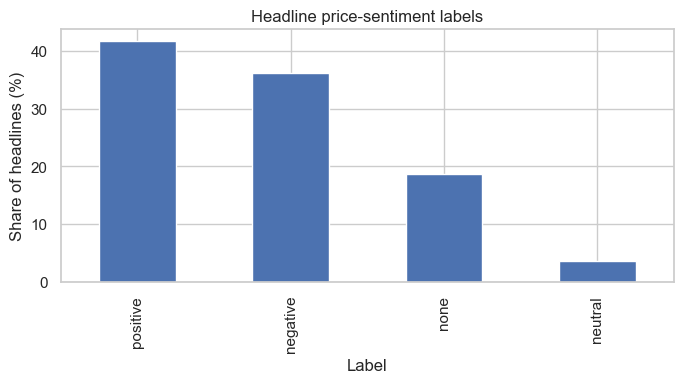

In [5]:
for column in ["Price Sentiment", "Past Information", "Future Information"]:
    print(f"\n{column}")
    print(news[column].value_counts(dropna=False).to_string())

label_share = news["Price Sentiment"].value_counts(normalize=True).mul(100)
ax = label_share.plot(kind="bar", figsize=(7, 4), title="Headline price-sentiment labels")
ax.set_ylabel("Share of headlines (%)")
ax.set_xlabel("Label")
plt.tight_layout()
plt.show()

## 3. News coverage and sparsity
For daily forecasting, **the number of headlines per day matters at least as much as the total number of headlines**. A corpus may contain 10,000 articles but provide little information on most trading days. We examine observations by year, active news days, and the share of weekdays with any headline. Weekdays are a rough denominator; the precise trading-calendar comparison comes later.

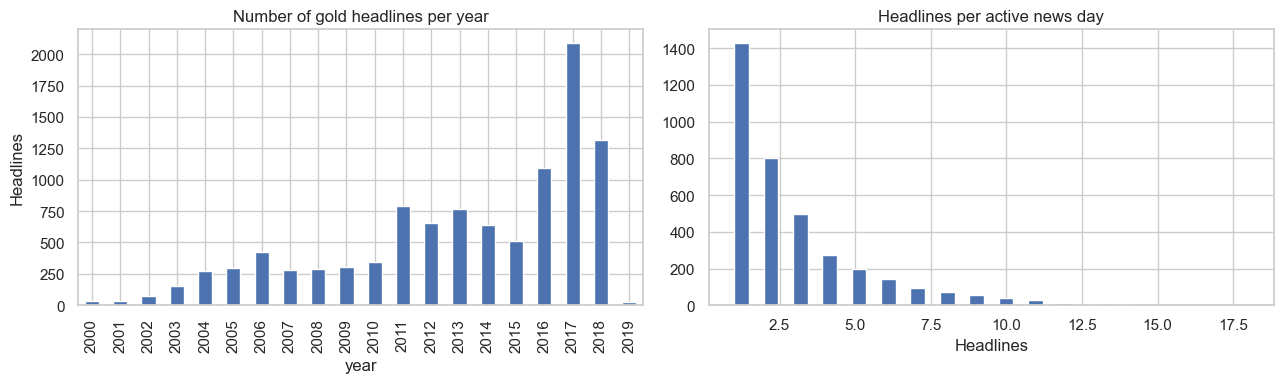

Unique active news dates: 3672
Weekdays with news: 3361 / 4949
Weekday coverage: 67.9%
Median articles per active day: 2.0


In [6]:
news["year"] = news["date"].dt.year
news_per_year = news.groupby("year").size()
news_per_day = news.groupby("date").size().rename("news_count")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
news_per_year.plot(kind="bar", ax=axes[0], title="Number of gold headlines per year")
axes[0].set_ylabel("Headlines")
news_per_day.hist(bins=35, ax=axes[1])
axes[1].set_title("Headlines per active news day")
axes[1].set_xlabel("Headlines")
plt.tight_layout()
plt.show()

weekdays = pd.date_range(news["date"].min(), news["date"].max(), freq="B")
active_weekdays = news_per_day.index.intersection(weekdays)
print("Unique active news dates:", len(news_per_day))
print("Weekdays with news:", len(active_weekdays), "/", len(weekdays))
print("Weekday coverage: {:.1%}".format(len(active_weekdays) / len(weekdays)))
print("Median articles per active day:", news_per_day.median())

## 4. Download daily gold futures data
We use the Yahoo Finance continuous gold-futures ticker `GC=F`. The series is a **data-vendor continuous futures history**: the treatment of contract rolls and prices requires checking before any tradable PnL calculation. We retain raw closes and do not create a backtest in this phase.

In [7]:
gold_raw = yf.download(
    "GC=F", start=START_DATE, end=END_DATE,
    auto_adjust=False, progress=False
)
if gold_raw.empty:
    raise RuntimeError("No gold prices downloaded. Check the connection or ticker.")

# Some versions of yfinance return MultiIndex columns even for one ticker.
if isinstance(gold_raw.columns, pd.MultiIndex):
    gold_raw.columns = gold_raw.columns.get_level_values(0)

gold = gold_raw[["Close"]].rename(columns={"Close": "gold_close"}).copy()
gold.index = pd.to_datetime(gold.index).tz_localize(None).normalize()
gold.index.name = "date"
gold = gold[~gold.index.duplicated()].sort_index()
print("Gold observations:", len(gold))
print("Range:", gold.index.min().date(), "to", gold.index.max().date())
display(gold.head())

curl_cffi not available; falling back to requests without browser TLS impersonation. Yahoo Finance may rate-limit or block this client. Install curl_cffi (>=0.15) for the supported configuration.


Gold observations: 6568
Range: 2000-08-30 to 2026-10-30


Price,gold_close
date,
2000-08-30,273.899994
2000-08-31,278.299988
2000-09-01,277.000000
2000-09-05,275.799988
2000-09-06,274.200012


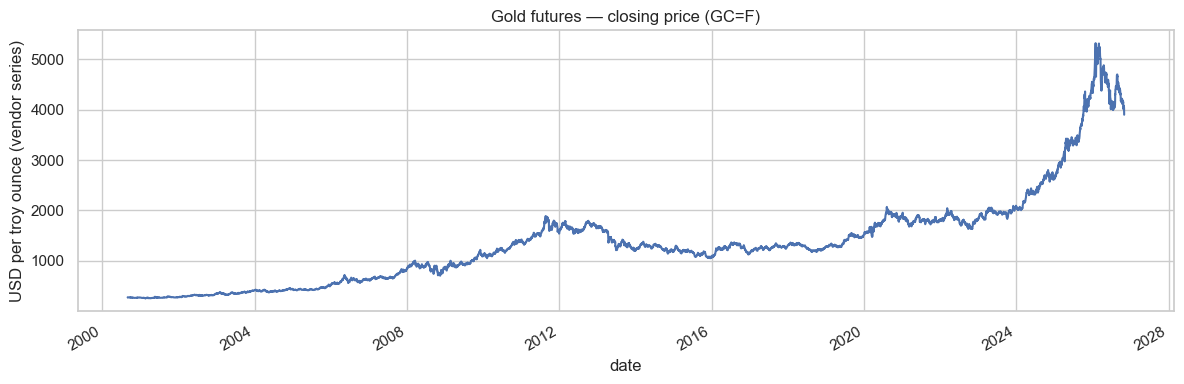

In [8]:
ax = gold["gold_close"].plot(figsize=(12, 4), title="Gold futures — closing price (GC=F)")
ax.set_ylabel("USD per troy ounce (vendor series)")
plt.tight_layout()
plt.show()

## 5. Download daily VIX data from FRED
The VIX is a market-implied measure of expected near-term U.S. equity volatility. We use it as a **financial-stress proxy**, not as an all-purpose measure of geopolitical risk. FRED `VIXCLS` is a daily closing series; publication and trading-close alignment will be explicitly handled before modeling.

In [9]:
import io
import requests

fred_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=VIXCLS"
response = requests.get(fred_url, timeout=30)
response.raise_for_status()

vix = pd.read_csv(io.StringIO(response.text))
vix.columns = ["date", "vix"]
vix["date"] = pd.to_datetime(vix["date"], errors="coerce")
vix["vix"] = pd.to_numeric(vix["vix"], errors="coerce")
vix = vix.dropna(subset=["date"]).set_index("date").sort_index()
print("VIX non-missing observations:", vix["vix"].notna().sum())
print("Range:", vix.index.min().date(), "to", vix.index.max().date())
display(vix.tail())

VIX non-missing observations: 9315
Range: 1990-01-02 to 2026-11-11


,vix
date,
2026-11-05,28.18
2026-11-06,25.64
2026-11-09,19.92
2026-11-10,19.46
2026-11-11,17.49


## 6. Download daily geopolitical risk (GPR)
Caldara and Iacoviello provide a daily **Recent GPR** series in Excel `.xls` format. This file is distinct from their monthly GPR dataset. As the data may be revised and updated weekly, it should not automatically be treated as a perfectly point-in-time historical predictor. For now we use it **descriptively**, recording its source and limitations. [GPR website](https://www.matteoiacoviello.com/gpr.htm).

In [10]:
from io import BytesIO

gpr_url = "https://www.matteoiacoviello.com/gpr_files/data_gpr_daily_recent.xls"
response = requests.get(gpr_url, timeout=40)
response.raise_for_status()

gpr_raw = pd.read_excel(BytesIO(response.content), engine="xlrd")
print("GPR columns:", gpr_raw.columns.tolist())
display(gpr_raw.head())

GPR columns: ['DAY', 'N10D', 'GPRD', 'GPRD_ACT', 'GPRD_THREAT', 'date', 'GPRD_MA30', 'GPRD_MA7', 'event', 'var_name', 'var_label']


,DAY,N10D,GPRD,GPRD_ACT,GPRD_THREAT,date,GPRD_MA30,GPRD_MA7,event,var_name,var_label
0,19850101,216,230.039429,275.197601,153.027985,1985-01-01,230.039429,230.039429,NaN,DAY,DAY
1,19850102,315,115.676971,146.772064,87.444572,1985-01-02,172.858200,172.858200,NaN,N10D,"Number of articles (10 recent newspapers, 1985-)"
2,19850103,374,97.428459,158.937653,29.459934,1985-01-03,147.714951,147.714951,NaN,GPRD,Daily GPR (Index: 1985:2019=100)
3,19850104,421,157.366638,156.882248,157.026352,1985-01-04,150.127869,150.127869,NaN,GPRD_ACT,Daily GPR Acts (Index: 1985:2019=100)
4,19850105,285,81.361313,92.698143,77.319405,1985-01-05,136.374557,136.374557,NaN,GPRD_THREAT,Daily GPR Threats (Index: 1985:2019=100)


**Column inspection checkpoint.** The provider can change its file structure. The next cell tries common names, but if the column names are different, inspect the printed table above and set the two fields manually. This is intentional: guessing which risk series we downloaded would undermine reproducibility.

In [11]:
# Choose the daily date and headline GPR index columns.
cols = {str(col).strip().lower(): col for col in gpr_raw.columns}

def find_col(candidates):
    for candidate in candidates:
        if candidate.lower() in cols:
            return cols[candidate.lower()]
    return None

date_col = find_col(["date", "day", "dates"])
value_col = find_col(["GPRD", "GPR", "gpr_daily"])

if date_col is None or value_col is None:
    raise ValueError(
        "Please inspect GPR columns above and manually set date_col/value_col. "
        f"Columns: {gpr_raw.columns.tolist()}"
    )

gpr = gpr_raw[[date_col, value_col]].copy()
gpr.columns = ["date", "gpr"]
gpr["date"] = pd.to_datetime(gpr["date"], errors="coerce")
gpr["gpr"] = pd.to_numeric(gpr["gpr"], errors="coerce")
gpr = gpr.dropna(subset=["date"]).set_index("date").sort_index()
print("GPR observations:", gpr["gpr"].notna().sum())
display(gpr.tail())

GPR observations: 15281


,gpr
date,
2026-10-29,299.244568
2026-10-30,153.182312
2026-10-31,180.685516
2026-11-01,86.264778
2026-11-02,113.945816


## 7. Compare the available histories
We first report first/last observed date and non-missing counts for every source. These figures are diagnostics, not final modeling sample sizes.

In [12]:
def series_summary(name, series):
    clean = series.dropna()
    return {
        "dataset": name,
        "first_date": clean.index.min().date() if len(clean) else None,
        "last_date": clean.index.max().date() if len(clean) else None,
        "observations": len(clean)
    }

coverage = pd.DataFrame([
    series_summary("Gold futures", gold["gold_close"]),
    series_summary("VIX", vix["vix"]),
    series_summary("Daily GPR", gpr["gpr"]),
    series_summary("News-active days", news_per_day)
])
display(coverage)

,dataset,first_date,last_date,observations
0,Gold futures,2000-08-30,2026-10-30,6568
1,VIX,1990-01-02,2026-11-11,9315
2,Daily GPR,1985-01-01,2026-11-02,15281
3,News-active days,2000-02-15,2019-02-01,3672


## 8. Align datasets on the gold trading calendar
The goal is to quantify how many **gold trading days** have related news and valid stress data. We do **not** fill missing market information across arbitrary dates at this stage. A zero headline count means no headline *in this corpus* for that trading date, not necessarily no market news.

In [13]:
audit = gold.join(vix, how="left").join(gpr, how="left")
audit = audit.join(news_per_day, how="left")
audit["has_news"] = audit["news_count"].notna()
audit["news_count"] = audit["news_count"].fillna(0).astype(int)
audit["year"] = audit.index.year

print("Gold trading days:", len(audit))
print("Trading days with news:", int(audit["has_news"].sum()))
print("News-day coverage: {:.1%}".format(audit["has_news"].mean()))
print("Trading days with news + VIX + GPR:", int(
    (audit["has_news"] & audit["vix"].notna() & audit["gpr"].notna()).sum()
))

yearly = audit.groupby("year").agg(
    gold_days=("gold_close", "size"),
    days_with_news=("has_news", "sum"),
    total_headlines=("news_count", "sum"),
    vix_days=("vix", "count"),
    gpr_days=("gpr", "count")
)
yearly["news_coverage_pct"] = 100 * yearly["days_with_news"] / yearly["gold_days"]
display(yearly)

Gold trading days: 6568
Trading days with news: 3278
News-day coverage: 49.9%
Trading days with news + VIX + GPR: 3276


,gold_days,days_with_news,total_headlines,vix_days,gpr_days,news_coverage_pct
year,,,,,,
2000,84,14,14,84,84,16.666667
2001,247,34,35,246,247,13.765182
2002,250,64,71,250,250,25.600000
2003,250,114,150,250,250,45.600000
2004,249,158,271,249,249,63.453815
2005,248,151,287,248,248,60.887097
2006,250,193,413,249,250,77.200000
2007,252,176,271,251,252,69.841270
2008,253,168,278,253,253,66.403162


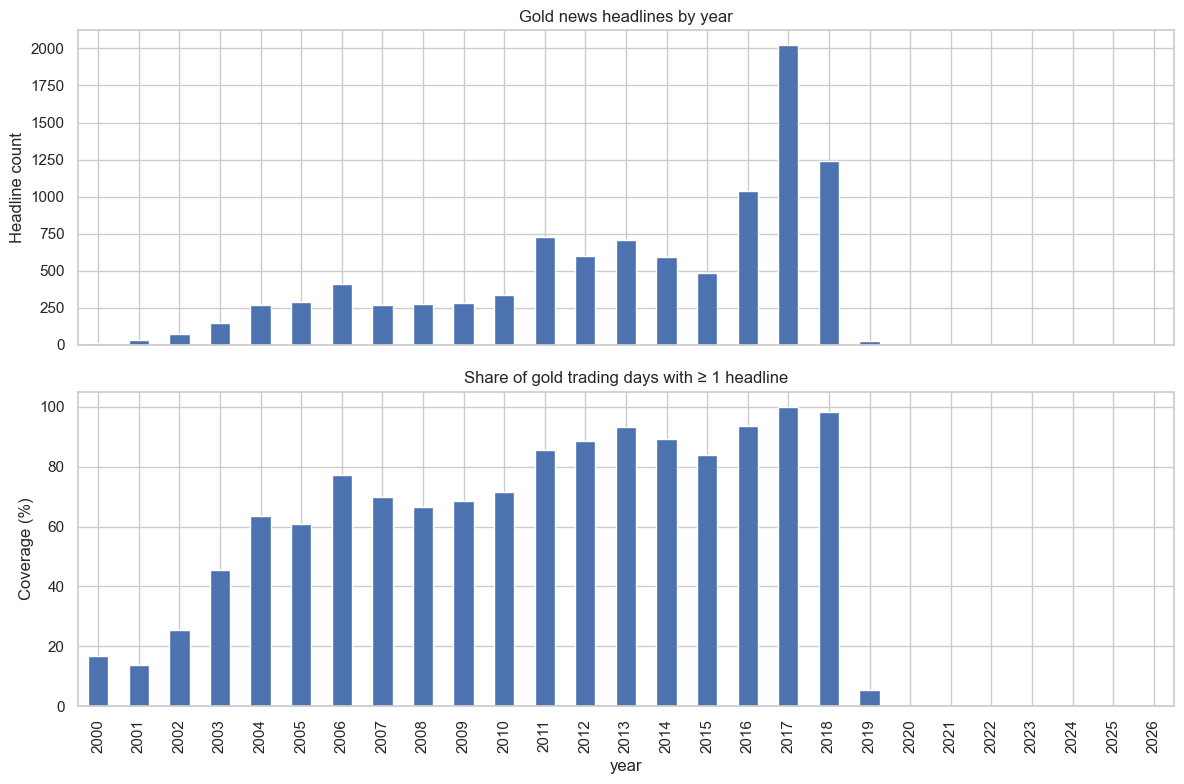

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
yearly["total_headlines"].plot(kind="bar", ax=axes[0], title="Gold news headlines by year")
axes[0].set_ylabel("Headline count")
yearly["news_coverage_pct"].plot(kind="bar", ax=axes[1], title="Share of gold trading days with ≥ 1 headline")
axes[1].set_ylabel("Coverage (%)")
plt.tight_layout()
plt.show()

## 9. Inspect prospective vs retrospective news
The dataset documentation reports that only a small minority of headlines mention future information. We measure their actual frequency and active trading-day coverage in the retained clean sample. A prospective label alone does **not** establish that an article came before the future return being forecast.

In [15]:
news["is_future"] = pd.to_numeric(news["Future Information"], errors="coerce").eq(1)
news["is_past"] = pd.to_numeric(news["Past Information"], errors="coerce").eq(1)

future_news = news.loc[news["is_future"]]
print("Prospective headlines:", len(future_news))
print("Prospective share: {:.1%}".format(news["is_future"].mean()))
print("Dates with prospective headlines:", future_news["date"].nunique())

future_count = future_news.groupby("date").size()
audit["has_future_news"] = audit.index.isin(future_count.index)
print("Gold trading days with prospective news:", int(audit["has_future_news"].sum()))

display(news[["date", "headline", "Price Sentiment", "Past Information", "Future Information"]].sample(
    min(10, len(news)), random_state=42
))

Prospective headlines: 314
Prospective share: 3.0%
Dates with prospective headlines: 289
Gold trading days with prospective news: 273


,date,headline,Price Sentiment,Past Information,Future Information
6784,2016-11-16,"gold wipes off losses, trading marginally high...",negative,1,0
9368,2018-03-27,gold futures mark first decline in 5 sessions,negative,1,0
5239,2014-10-14,Gold prices ease in Asia as dollar mostly stea...,none,1,0
4860,2014-04-16,"Gold prices ease in Asia on profit taking, Ukr...",none,1,0
2932,2011-10-10,gold buyers return to shop ahead of diwali as ...,none,1,0
9494,2018-04-27,blockchain & the gold standard for a conflict-...,none,1,0
7861,2017-06-29,"August gold falls $4.20, or 0.3%, at $1,245/oz.",negative,1,0
3881,2012-11-21,"gold settles higher, recoups part of tuesday loss",positive,1,0
2340,2010-07-27,"gold adds to loss after consumer gauge, oil lower",negative,1,0
1702,2008-07-01,gold glitters on stockists' buying,positive,1,0


## 10. Feasibility assessment and data limitations
Before choosing a forecasting horizon, we should answer:

1. How many distinct gold trading days contain news?
2. How does coverage vary across years and during stress?
3. How many dates contain genuinely prospective headlines?
4. Are the market and news sources sufficiently aligned?
5. Is the corpus large and regular enough for **daily**, or would **weekly** aggregation be more defensible?

**Timing limitations:** headlines have dates but no verified publication times; the current GPR download may contain revisions; GPR updates have their own release schedule; and gold continuous-futures closing values are not automatically executable futures returns. These limitations must be resolved or conservatively addressed before a backtest.

In [16]:
# Weekly coverage (weeks ending Friday) is useful if daily news are sparse.
weekly = audit.resample("W-FRI").agg(
    gold_days=("gold_close", "count"),
    headline_count=("news_count", "sum"),
    news_days=("has_news", "sum")
)
weekly = weekly[weekly["gold_days"] > 0]

print("Weeks with gold prices:", len(weekly))
print("Weeks with >= 1 headline:", int((weekly["headline_count"] > 0).sum()))
print("Weekly coverage: {:.1%}".format((weekly["headline_count"] > 0).mean()))
print("Median headlines per active week:", weekly.loc[weekly["headline_count"] > 0, "headline_count"].median())

display(weekly.describe().round(2))

Weeks with gold prices: 1366
Weeks with >= 1 headline: 906
Weekly coverage: 66.3%
Median headlines per active week: 8.0


,gold_days,headline_count,news_days
count,1366.00,1366.00,1366.00
mean,4.81,7.21,2.40
std,0.42,9.97,2.01
min,2.00,0.00,0.00
25%,5.00,0.00,0.00
50%,5.00,4.00,3.00
75%,5.00,10.00,4.00
max,5.00,63.00,5.00


## 10.1 Select the main research period (2011–2018)

The complete dataset remains available for exploratory analysis. We select **2011–2018** as the main candidate period because news coverage is much denser than in earlier years, and 2019 contains only a partial news sample. This is a **preliminary sampling decision**, not a claim that every trading session has a usable, point-in-time news signal.

We also retain **2008–2018** as a possible robustness period, including the global financial crisis. Both choices will be reassessed after the predictive alignment in Phase 2.

In [17]:
# Keep the original full-history dataframes unchanged.
MAIN_START = "2011-01-01"
MAIN_END = "2018-12-31"

news_main = news.loc[news["date"].between(MAIN_START, MAIN_END)].copy()
audit_main = audit.loc[MAIN_START:MAIN_END].copy()
yearly_main = yearly.loc[2011:2018].copy()

print("Main period:", MAIN_START, "to", MAIN_END)
print("Gold sessions:", len(audit_main))
print("News headlines:", len(news_main))
print("Days with news:", int(audit_main["has_news"].sum()))
print("Daily news coverage: {:.1%}".format(audit_main["has_news"].mean()))
display(yearly_main)

Main period: 2011-01-01 to 2018-12-31
Gold sessions: 2009
News headlines: 7869
Days with news: 1839
Daily news coverage: 91.5%


,gold_days,days_with_news,total_headlines,vix_days,gpr_days,news_coverage_pct
year,,,,,,
2011,252,216,730,252,252,85.714286
2012,250,221,597,250,250,88.400000
2013,252,235,706,252,252,93.253968
2014,252,225,595,252,252,89.285714
2015,252,211,483,252,252,83.730159
2016,250,234,1040,250,250,93.600000
2017,251,251,2021,251,251,100.000000
2018,250,246,1241,250,250,98.400000


## 10.2 Check data availability within the selected sample

A trading day is not necessarily usable for modeling: VIX or GPR may be missing on some gold trading sessions. The following checks measure raw availability only. In Phase 2, financial variables must be aligned with **when they became observable**, and features must be lagged appropriately. In particular, the historical GPR series should not automatically be treated as a real-time, point-in-time data release.

In [18]:
# Availability diagnostics (not yet a leakage-free predictive dataset).
audit_main["has_vix"] = audit_main["vix"].notna()
audit_main["has_gpr"] = audit_main["gpr"].notna()
audit_main["complete_raw_sources"] = (
    audit_main["has_news"] & audit_main["has_vix"] & audit_main["has_gpr"]
)

summary_main = pd.DataFrame({
    "metric": ["Gold trading sessions", "Days with news", "Days with VIX",
               "Days with GPR", "Days with all three sources",
               "Days with prospective headlines"],
    "count": [len(audit_main), int(audit_main["has_news"].sum()),
              int(audit_main["has_vix"].sum()),
              int(audit_main["has_gpr"].sum()),
              int(audit_main["complete_raw_sources"].sum()),
              int(audit_main["has_future_news"].sum())]
})
summary_main["share_of_gold_sessions"] = (
    summary_main["count"] / len(audit_main)
)
display(summary_main)

,metric,count,share_of_gold_sessions
0,Gold trading sessions,2009,1.000000
1,Days with news,1839,0.915381
2,Days with VIX,2009,1.000000
3,Days with GPR,2009,1.000000
4,Days with all three sources,1839,0.915381
5,Days with prospective headlines,257,0.127924


## 10.3 Inspect weekends and non-trading-day news

The original daily audit is indexed by gold trading sessions, so articles dated on Saturdays, Sundays, or gold market holidays do not appear directly on those dates. We quantify them here rather than discarding them. In Phase 2, these articles can be assigned to the **next eligible decision time**, using a conservative publication-time convention. We do not shift them here because daily dates do not specify the exact publication hour.

In [19]:
# Headlines dated outside the gold trading calendar.
trading_dates = pd.DatetimeIndex(audit.index).normalize()
news_main["is_trading_day"] = news_main["date"].isin(trading_dates)
news_main["is_weekend"] = news_main["date"].dt.dayofweek >= 5

print("News on weekends:", int(news_main["is_weekend"].sum()))
print("News outside gold trading dates:", int((~news_main["is_trading_day"]).sum()))
print("Share outside gold trading dates: {:.1%}".format(
    (~news_main["is_trading_day"]).mean()
))

# Check whether retrospective/prospective labels vary by year.
news_main["year"] = news_main["date"].dt.year
label_report = news_main.groupby("year").agg(
    headlines=("headline", "size"),
    prospective=("is_future", "sum"),
    retrospective=("is_past", "sum")
)
label_report["prospective_share"] = (
    label_report["prospective"] / label_report["headlines"]
)
display(label_report)

News on weekends: 317
News outside gold trading dates: 456
Share outside gold trading dates: 5.8%


,headlines,prospective,retrospective,prospective_share
year,,,,
2011,789,35,754,0.044360
2012,656,31,625,0.047256
2013,767,22,745,0.028683
2014,641,20,621,0.031201
2015,515,16,499,0.031068
2016,1094,31,1063,0.028336
2017,2093,60,2034,0.028667
2018,1314,80,1234,0.060883


## 10.4 Compare weekly coverage on the selected period

Weekly aggregation can reduce sparse news coverage. The primary candidate remains **next-session forecasting**, while weekly forecasts will be considered as a robustness experiment if daily feature availability is insufficient. This is a coverage comparison, **not** yet a predictive weekly dataset.

Weeks with gold trading: 418
Weeks with at least one headline: 417
Weekly coverage: 99.8%


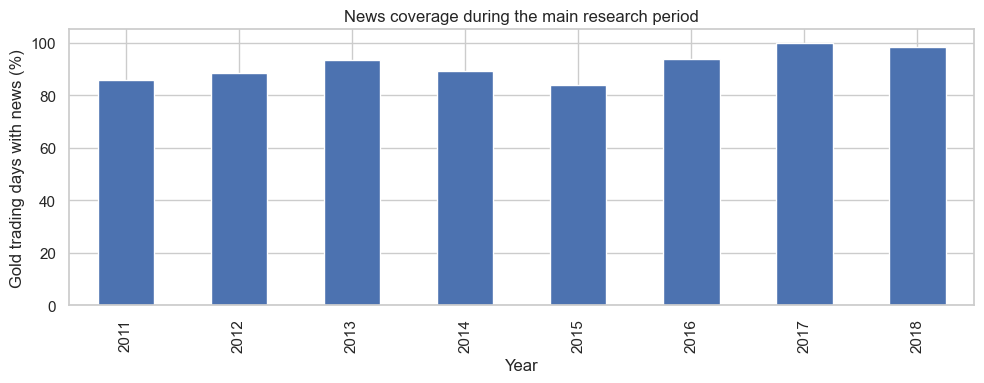

In [20]:
weekly_main = audit_main.resample("W-FRI").agg(
    gold_days=("gold_close", "count"),
    headline_count=("news_count", "sum"),
    news_days=("has_news", "sum")
)
weekly_main = weekly_main.loc[weekly_main["gold_days"] > 0]
print("Weeks with gold trading:", len(weekly_main))
print("Weeks with at least one headline:", int((weekly_main["headline_count"] > 0).sum()))
print("Weekly coverage: {:.1%}".format((weekly_main["headline_count"] > 0).mean()))

fig, ax = plt.subplots(figsize=(10, 4))
yearly_main["news_coverage_pct"].plot.bar(ax=ax)
ax.set_title("News coverage during the main research period")
ax.set_xlabel("Year")
ax.set_ylabel("Gold trading days with news (%)")
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()

## 11. Save the cleaned data and audit reports
The saved files make later phases faster and easier to reproduce. We export the cleaned news, raw-aligned financial audit, and coverage reports. These files contain no fitted models and do not imply that look-ahead bias has yet been resolved.

In [21]:
news.to_csv(DATA_DIR / "gold_news_clean.csv", index=False)
gold.to_csv(DATA_DIR / "gold_futures.csv")
vix.to_csv(DATA_DIR / "vix.csv")
gpr.to_csv(DATA_DIR / "gpr_daily.csv")
audit.to_csv(DATA_DIR / "audit_daily.csv")
yearly.to_csv(DATA_DIR / "coverage_by_year.csv")
weekly.to_csv(DATA_DIR / "coverage_weekly.csv")
coverage.to_csv(DATA_DIR / "source_availability.csv", index=False)
print("Saved files:")
for file in sorted(DATA_DIR.glob("*.csv")):
    print("-", file)

Saved files:
- data/audit_daily.csv
- data/audit_daily_2011_2018.csv
- data/availability_2011_2018.csv
- data/coverage_2011_2018.csv
- data/coverage_by_year.csv
- data/coverage_weekly.csv
- data/coverage_weekly_2011_2018.csv
- data/gold_futures.csv
- data/gold_news_2011_2018.csv
- data/gold_news_clean.csv
- data/gpr_daily.csv
- data/phase2_full_prepared.csv
- data/phase2_main_2011_2018.csv
- data/phase2_missingness.csv
- data/phase2_news_date_mapping.csv
- data/phase2_robustness_2008_2018.csv
- data/phase2_split_report.csv
- data/phase3_finbert_headlines.csv
- data/phase3_main_2011_2018.csv
- data/phase3_nlp_coverage.csv
- data/phase3_tfidf_row_mapping.csv
- data/phase4_nlp_rmse_gains.csv
- data/phase4_preliminary_vix_regimes.csv
- data/phase4_selected_parameters.csv
- data/phase4_test_metrics.csv
- data/phase4_test_predictions.csv
- data/phase4_validation_metrics.csv
- data/phase5_annual_forecast_errors.csv
- data/phase5_cost_sensitivity.csv
- data/phase5_cumulative_wealth.csv
- data/

In [22]:
# Save candidate main-period datasets for Phase 2.
# We keep missing data as missing; do not fill with future observations.
news_main.to_csv(DATA_DIR / "gold_news_2011_2018.csv", index=False)
audit_main.to_csv(DATA_DIR / "audit_daily_2011_2018.csv")
yearly_main.to_csv(DATA_DIR / "coverage_2011_2018.csv")
weekly_main.to_csv(DATA_DIR / "coverage_weekly_2011_2018.csv")
summary_main.to_csv(DATA_DIR / "availability_2011_2018.csv", index=False)
print("Main-period datasets exported to:", DATA_DIR.resolve())

Main-period datasets exported to: /Users/mac/projet_ml_trading/data


## 12. Phase 1 Conclusions and Research Design Decisions

### 12.1 Data availability and quality

The original news dataset contains **10,570 gold-related headlines**. After removing **165 records with invalid dates** and **one duplicated date–headline pair**, the cleaned dataset contains **10,404 headlines** covering **3,672 distinct dates**, from **February 15, 2000 to February 1, 2019**.

The financial data have a longer history: gold futures (`GC=F`) provide **6,568 trading-day observations** between **August 30, 2000 and October 30, 2026**; the VIX has **9,306 valid observations**; and the daily geopolitical risk index (GPR) contains **15,274 observations**. The three market-related datasets therefore offer sufficient historical coverage, although the shorter news history determines the effective sample for the sentiment-based analysis.

### 12.2 News coverage and sample selection

Across the complete gold-price sample, **3,278 trading days** contain at least one news headline, representing **49.9%** of gold trading days. This figure is misleading if interpreted as the coverage of the relevant news period, since no headlines are available after early 2019. Similarly, **906 of 1,366 weeks (66.3%)** contain at least one headline over the entire financial sample, with a median of **8 headlines per active week**.

News coverage improves substantially over time. The proportion of gold trading days covered by news reaches approximately **85.7% in 2011**, **93.3% in 2013**, **93.6% in 2016**, **100% in 2017**, and **98.4% in 2018**. Earlier years are less consistently covered.

Based on these findings, **2011–2018 is our preferred candidate period for the main predictive analysis**, while **2008–2018 is a useful alternative for investigating the 2008 financial crisis**. This choice remains provisional until the final point-in-time alignment and the actual number of usable supervised-learning observations have been checked. The year 2019 should not be included as a full year because the news corpus ends on February 1, 2019.

### 12.3 Sentiment labels and interpretation

Of the cleaned headlines, **10,091 (approximately 97.0%)** are labeled as *Past Information*, while only **314 (approximately 3.0%)** are labeled as *Future Information*. Prospective headlines occur on **289 distinct dates**, including **273 gold trading days**.

This is a major limitation for an experiment based exclusively on prospective headlines. However, retrospective news may still provide useful predictors of subsequent returns through continuation, reversal, or delayed market reactions. It is therefore reasonable to retain all headlines in the main analysis and use the prospective-versus-retrospective distinction in a **secondary ablation or robustness test**, rather than restricting the baseline dataset to 314 headlines.

Importantly, these annotations describe the **content of the headlines**, not the actual time at which the information became available to investors.

### 12.4 Forecasting horizon and information timing

We propose **next-trading-day gold returns as the primary forecasting target**, with **weekly returns as a robustness exercise**. The high headline coverage in 2011–2018 supports investigating a daily frequency, while weekly aggregation may reduce the sensitivity of sentiment indicators to days without articles.

Because the corpus provides dates but not reliable publication timestamps, we cannot assume that headlines dated on day *t* were available before the gold closing price on that day. In Phase 2, news signals will therefore be **lagged conservatively**, and the forecast-decision time, target-return interval, and trade-entry convention will be stated explicitly. Market variables such as the daily VIX will be aligned according to their own availability. Missing news will not automatically be interpreted as neutral sentiment.

### 12.5 Remaining limitations

1. **Historical scope:** news coverage ends in early 2019, so the current corpus cannot support an NLP backtest covering 2020–2026.
2. **Publication-time uncertainty:** missing intraday timestamps require conservative lags to prevent look-ahead bias.
3. **Revised geopolitical data:** the downloaded historical GPR series may contain later revisions; its use as a real-time predictor requires caution.
4. **Continuous futures prices:** the `GC=F` series requires checks for contract rolls before interpreting a trading backtest as implementable.
5. **News availability:** some dates have no articles in the corpus; this does not prove that no relevant news was published that day.
6. **Stress-period inference:** the effective number of high-stress observations must be checked before making claims about regime-specific predictive performance.

### 12.6 Decision and next steps

**Phase 1 is sufficiently complete to proceed to Phase 2, with the limitations above explicitly documented.** The next stage will define a leakage-free gold-return target, construct financial features (returns, momentum, volatility, VIX, dollar and interest-rate variables), select the final common sample, and specify the chronology of news and market-data availability. No predictive model should be evaluated before these decisions are fixed.


### Main references
- Sinha, A. & Khandait, T. (2021), *Impact of News on the Commodity Market: Dataset and Results*. https://arxiv.org/abs/2009.04202
- Baur, D. & Lucey, B. (2010), *Is Gold a Hedge or a Safe Haven?* https://doi.org/10.1111/j.1540-6288.2010.00244.x
- Caldara, D. & Iacoviello, M. (2022), *Measuring Geopolitical Risk*. https://www.matteoiacoviello.com/gpr.htm
- FRED, CBOE Volatility Index: VIX (VIXCLS). https://fred.stlouisfed.org/series/VIXCLS
- Yahoo Finance, Gold Futures (`GC=F`). https://finance.yahoo.com/quote/GC=F/history/

---
# Phase 2 — Financial Features, Forecasting Target and Leakage-Free Alignment

**Research objective.** Build a clean predictive dataset for next-session gold returns using financial information and a calendar-aligned news-availability indicator. **No NLP or machine-learning model is trained in this phase.**

**Main sample:** 2011–2018. **Robustness sample:** 2008–2018, subject to adequate observations.

**Timing convention.** A feature row dated trading session $t$ uses financial observations and news available no later than the **previous gold trading session**. The outcome is the return from gold close $t$ to gold close $t+1$. This conservative one-session lag protects against unknown intraday publication times and different market closing hours. It is a modeling convention, not an actual fill-price guarantee for a trading strategy.

We use log returns for prediction and will use simple returns when calculating economic PnL in a later phase.

## 13. Inspect Phase 1 inputs

We reuse the in-memory tables from Phase 1 (`gold`, `vix`, `gpr`, `news`) and do **not** download the same files again. Run the notebook from the top. We check that the expected columns exist before building features.

In [23]:
# Verify that Phase 1 has been executed successfully.
required = [(gold, "gold_close"), (vix, "vix"), (gpr, "gpr"), (news, "date")]
for table, column in required:
    if column not in table.columns:
        raise ValueError(f"Missing '{column}'. Please execute Phase 1 first.")

print("Gold price observations:", gold["gold_close"].notna().sum())
print("News headlines:", len(news))
print("Main sample:", MAIN_START, "to", MAIN_END)
print("Gold dates are unique:", gold.index.is_unique)

Gold price observations: 6568
News headlines: 10404
Main sample: 2011-01-01 to 2018-12-31
Gold dates are unique: True


## 14. Define the forecasting target

For gold closing price $P_t$, the **next-session log return** is

$$y_t = \log(P_{t+1}/P_t).$$

The prediction is made using information dated before $t$, so observations from the future cannot enter the feature vector. We also compute the corresponding simple return $R_{t+1}=P_{t+1}/P_t-1$ for use in a later trading simulation. **Neither target is used as a predictor.**

Do not split prices into training/test periods before calculating returns; use the full contiguous price history to form lagged features, then select the research sample.

In [24]:
# Start from the vendor's closing-price series.
prices = gold[["gold_close"]].copy().sort_index()
prices["gold_close"] = pd.to_numeric(prices["gold_close"], errors="coerce")
prices.loc[prices["gold_close"] <= 0, "gold_close"] = np.nan

# We explicitly use the previous/next available gold row (not the next calendar day).
prices["gold_log_return"] = np.log(prices["gold_close"] / prices["gold_close"].shift(1))
prices["target_next_log_return"] = np.log(prices["gold_close"].shift(-1) / prices["gold_close"])
prices["target_next_simple_return"] = prices["gold_close"].shift(-1) / prices["gold_close"] - 1

print(prices[["gold_log_return", "target_next_log_return"]].describe().round(5))
display(prices.tail(4))

Price  gold_log_return  target_next_log_return
count       6567.00000              6567.00000
mean           0.00040                 0.00040
std            0.01132                 0.01132
min           -0.11406                -0.11406
25%           -0.00489                -0.00489
50%            0.00049                 0.00049
75%            0.00633                 0.00633
max            0.08643                 0.08643


Price,gold_close,gold_log_return,target_next_log_return,target_next_simple_return
date,,,,
2026-10-27,4074.600098,0.008924,-0.005661,-0.005645
2026-10-28,4051.600098,-0.005661,-0.004998,-0.004986
2026-10-29,4031.399902,-0.004998,-0.033419,-0.032867
2026-10-30,3898.899902,-0.033419,NaN,NaN


## 15. Create basic financial features

Gold returns can depend on short-term trend, recent reversal, and changing uncertainty. We construct parsimonious features using historical gold returns:

- **1-session return:** $r_t$.
- **5- and 20-session momentum:** $\sum_{j=0}^{k-1}r_{t-j}$.
- **20-session realized volatility:** $\sqrt{252}\operatorname{std}(r_{t-19},\ldots,r_t)$.

We also include the level and one-day change in the VIX, and the daily geopolitical-risk index (GPR), but use the latter **only for exploratory analysis** until its point-in-time availability is verified. Because the GPR history is revised, a retrospective GPR value is not automatically a valid real-time predictor.

In [25]:
# Compute descriptive financial features using each series' original date.
features_raw = prices[["gold_log_return"]].copy()
features_raw["gold_momentum_5"] = prices["gold_log_return"].rolling(5).sum()
features_raw["gold_momentum_20"] = prices["gold_log_return"].rolling(20).sum()
features_raw["gold_volatility_20"] = prices["gold_log_return"].rolling(20).std() * np.sqrt(252)

# Align external observations by date, without forward-filling future information.
features_raw = features_raw.join(vix[["vix"]], how="left")
features_raw["vix_change"] = features_raw["vix"].diff()
features_raw = features_raw.join(gpr[["gpr"]], how="left")

# A conservative one-gold-session delay is applied to EVERY financial feature.
financial_features = features_raw.shift(1).add_prefix("lag1_")
print("Available feature columns:")
print(financial_features.columns.tolist())
display(financial_features.loc[MAIN_START:MAIN_END].head())

Available feature columns:
['lag1_gold_log_return', 'lag1_gold_momentum_5', 'lag1_gold_momentum_20', 'lag1_gold_volatility_20', 'lag1_vix', 'lag1_vix_change', 'lag1_gpr']


,lag1_gold_log_return,lag1_gold_momentum_5,lag1_gold_momentum_20,lag1_gold_volatility_20,lag1_vix,lag1_vix_change,lag1_gpr
date,,,,,,,
2011-01-03,0.010967,0.029348,0.023207,0.143422,17.75,0.23,45.377640
2011-01-04,0.001055,0.028665,0.012164,0.137486,17.61,-0.14,74.201515
2011-01-05,-0.031490,-0.019184,-0.026346,0.176179,17.38,-0.23,119.252434
2011-01-06,-0.003707,-0.028496,-0.025094,0.175892,17.02,-0.36,44.563690
2011-01-07,-0.001457,-0.024632,-0.008061,0.163726,17.40,0.38,74.082985


### Why do we lag every feature?

Gold futures, U.S. equity volatility and macroeconomic series have different update times. Using their same-day closing values in a simultaneous close-to-close trading signal could accidentally assume information unavailable at the decision time. **The one-session lag is deliberately conservative** and simplifies the timing protocol. A future study could use precise timestamps to reduce this delay.

**Missing values.** We do not use `bfill()` (backward fill) or any global imputation. Missing VIX observations remain missing. In Phase 3, we can compare complete-case models with training-only imputers.

## 16. Optional macroeconomic controls: real yields and nominal yields

Gold is sensitive to interest rates and the opportunity cost of holding a non-interest-bearing asset. The Federal Reserve Bank of St. Louis (FRED) provides **DGS10** (10-year nominal Treasury yield) and **DFII10** (10-year inflation-indexed Treasury yield, a real-yield proxy).

These controls are optional: if FRED cannot be reached, the notebook continues using the core data. The downloaded series are historical observations, not necessarily full vintage, point-in-time release histories. We use a one-gold-session lag, and do **not** fill release gaps with future values.

In [26]:
# Download optional interest-rate controls without stopping the whole notebook.
from io import StringIO

extra_features = pd.DataFrame(index=prices.index)
for fred_id, new_name in [("DGS10", "nominal_yield_10y"), ("DFII10", "real_yield_10y")]:
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={fred_id}"
    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        table = pd.read_csv(StringIO(response.text))
        date_column = table.columns[0]  # FRED may call this DATE or observation_date
        dates = pd.to_datetime(table[date_column], errors="coerce")
        series = pd.to_numeric(table[fred_id], errors="coerce")
        series.index = dates
        extra_features[new_name] = series.reindex(prices.index)
        print(f"{fred_id}: {extra_features[new_name].notna().sum()} observations")
    except Exception as exc:
        print(f"Could not download {fred_id}: {exc}")
        extra_features[new_name] = np.nan

# A one-session lag; units are percentage points (not decimal returns).
extra_features = extra_features.shift(1).add_prefix("lag1_")
financial_features = financial_features.join(extra_features)
display(financial_features.loc[MAIN_START:MAIN_END].tail(3))

DGS10: 6518 observations
DFII10: 5942 observations


,lag1_gold_log_return,lag1_gold_momentum_5,lag1_gold_momentum_20,lag1_gold_volatility_20,lag1_vix,lag1_vix_change,lag1_gpr,lag1_nominal_yield_10y,lag1_real_yield_10y
date,,,,,,,,,
2018-12-27,0.001340,0.015883,0.039372,0.093070,30.41,-5.66,63.096531,2.81,1.04
2018-12-28,0.006362,0.019926,0.053137,0.087335,29.96,-0.45,30.224155,2.77,1.03
2018-12-31,0.002033,0.012817,0.046784,0.084679,28.34,-1.62,102.007759,2.72,0.99


## 17. Optional dollar-market control

The U.S. dollar often co-moves with gold. If available, Yahoo Finance ticker `DX-Y.NYB` is a dollar-index proxy. Since access and history may vary, the code treats it as optional and records how much coverage is actually obtained. We compute the dollar's log return and lag it one gold session, exactly as for the other market variables.

In [27]:
# Download a dollar-index proxy (optional; dataset availability varies).
financial_features["lag1_usd_return"] = np.nan
try:
    usd_raw = yf.download("DX-Y.NYB", start=START_DATE, end=END_DATE,
                          auto_adjust=False, progress=False)
    if not usd_raw.empty:
        if isinstance(usd_raw.columns, pd.MultiIndex):
            usd_raw.columns = usd_raw.columns.get_level_values(0)
        usd_close = usd_raw["Close"].copy()
        usd_close.index = pd.to_datetime(usd_close.index).tz_localize(None).normalize()
        usd_close = usd_close[~usd_close.index.duplicated(keep="last")]
        usd_return = np.log(usd_close / usd_close.shift(1))
        financial_features["lag1_usd_return"] = usd_return.reindex(prices.index).shift(1)
    print("Dollar-return coverage:", financial_features["lag1_usd_return"].notna().sum())
except Exception as exc:
    print("Dollar index unavailable; this optional feature will not be used:", exc)

Dollar-return coverage: 6563


## 18. Align news to the gold trading calendar

The headlines contain a **calendar date but no verified publication time**. For this reason, we cannot assume they were available before the gold close on that same date.

We first associate each article date with the **next gold trading date on or after publication**. This preserves news posted on weekends and holidays. We then shift the aggregated news count **one additional gold trading session**. A Monday headline, for example, will only be available as an indicator in the Tuesday row under this conservative protocol.

This phase creates **news availability indicators only**, not sentiment scores. FinBERT and TF-IDF are Phase 3 tasks.

In [28]:
# Map a news publication DATE to the next gold trading date.
trading_dates = prices.index.sort_values()
news_timing = news[["date", "headline"]].copy()
news_timing["date"] = pd.to_datetime(news_timing["date"]).dt.normalize()

# searchsorted finds the position of the next trading date (or the same date).
positions = trading_dates.searchsorted(news_timing["date"], side="left")
valid = positions < len(trading_dates)
news_timing = news_timing.loc[valid].copy()
news_timing["assigned_trading_day"] = trading_dates[positions[valid]].to_numpy()

# Aggregate mapped news, then delay its availability by one trading session.
news_counts = news_timing.groupby("assigned_trading_day").size()
news_counts = news_counts.reindex(trading_dates, fill_value=0)
news_features = pd.DataFrame(index=trading_dates)
news_features["known_news_count"] = news_counts.shift(1).fillna(0).astype(int)
news_features["known_has_news"] = news_features["known_news_count"] > 0

print("News outside the calendar retained:", len(news_timing))
print("Total articles assigned:", int(news_counts.sum()))
display(news_features.loc["2018-01-01":"2018-01-12"])

News outside the calendar retained: 10404
Total articles assigned: 10404


,known_news_count,known_has_news
date,,
2018-01-02,1,True
2018-01-03,9,True
2018-01-04,1,True
2018-01-05,3,True
2018-01-08,7,True
2018-01-09,3,True
2018-01-10,2,True
2018-01-11,5,True
2018-01-12,6,True


## 19. Assemble the forecasting table

Each row $t$ contains:

- `target_next_log_return`: the gold return from session $t$ to session $t+1$.
- `lag1_*`: financial observations known by the previous gold session under our timing convention.
- `known_news_count` and `known_has_news`: counts of earlier headlines, after weekend alignment and a one-session delay.

We preserve missing values at this stage instead of discarding them all. This keeps the differences between the core and extended feature sets transparent.

In [29]:
# Assemble data without inserting the future return among explanatory variables.
model_data = prices[["gold_close", "target_next_log_return", "target_next_simple_return"]].copy()
model_data = model_data.join(financial_features).join(news_features)
model_data.index.name = "date"

# Keep research samples separate from the complete history.
model_main = model_data.loc[MAIN_START:MAIN_END].copy()
model_robustness = model_data.loc["2008-01-01":"2018-12-31"].copy()

print("Main sample rows:", len(model_main))
print("Robustness sample rows:", len(model_robustness))
display(model_main.head(5))

Main sample rows: 2009
Robustness sample rows: 2766


,gold_close,target_next_log_return,target_next_simple_return,lag1_gold_log_return,lag1_gold_momentum_5,lag1_gold_momentum_20,lag1_gold_volatility_20,lag1_vix,lag1_vix_change,lag1_gpr,lag1_nominal_yield_10y,lag1_real_yield_10y,lag1_usd_return,known_news_count,known_has_news
date,,,,,,,,,,,,,,,
2011-01-03,1422.599976,-0.031490,-0.031000,0.010967,0.029348,0.023207,0.143422,17.75,0.23,45.377640,3.30,1.00,-0.006181,2,True
2011-01-04,1378.500000,-0.003707,-0.003700,0.001055,0.028665,0.012164,0.137486,17.61,-0.14,74.201515,3.36,1.05,0.001265,0,False
2011-01-05,1373.400024,-0.001457,-0.001456,-0.031490,-0.019184,-0.026346,0.176179,17.38,-0.23,119.252434,3.36,1.01,0.003910,1,True
2011-01-06,1371.400024,-0.002117,-0.002115,-0.003707,-0.028496,-0.025094,0.175892,17.02,-0.36,44.563690,3.50,1.08,0.010269,0,False
2011-01-07,1368.500000,0.003793,0.003800,-0.001457,-0.024632,-0.008061,0.163726,17.40,0.38,74.082985,3.44,1.03,0.006582,2,True


## 20. Check missingness and usable sample size

A large nominal sample does not guarantee a large *usable* sample. We distinguish a **core financial model** (gold returns/momentum/volatility and VIX) from an **extended model** (optional yields and dollar). We deliberately omit revised historical GPR from the core predictive feature set; it remains available for exploratory stress analysis.

For a fair comparison in Phase 4, the financial-only and financial+NLP models must be evaluated on **identical test dates**. Do not allow NLP to change the evaluation universe.

In [30]:
# Explicit baseline feature groups.
CORE_FEATURES = [
    "lag1_gold_log_return", "lag1_gold_momentum_5",
    "lag1_gold_momentum_20", "lag1_gold_volatility_20",
    "lag1_vix", "lag1_vix_change"
]
OPTIONAL_FEATURES = ["lag1_nominal_yield_10y", "lag1_real_yield_10y", "lag1_usd_return"]
TARGET = "target_next_log_return"

# Only retain optional features with reasonable coverage (>80%) in main sample.
active_optional = [c for c in OPTIONAL_FEATURES if model_main[c].notna().mean() >= 0.80]
EXTENDED_FEATURES = CORE_FEATURES + active_optional

usable_core = model_main.dropna(subset=CORE_FEATURES + [TARGET])
usable_extended = model_main.dropna(subset=EXTENDED_FEATURES + [TARGET])

coverage_report = pd.DataFrame({
    "non_missing": model_main.notna().sum(),
    "missing_pct": (model_main.isna().mean() * 100).round(2)
}).sort_values("missing_pct", ascending=False)

print("Usable core rows:", len(usable_core), "out of", len(model_main))
print("Usable extended rows:", len(usable_extended))
print("Selected optional features:", active_optional)
display(coverage_report)

Usable core rows: 2009 out of 2009
Usable extended rows: 1996
Selected optional features: ['lag1_nominal_yield_10y', 'lag1_real_yield_10y', 'lag1_usd_return']


,non_missing,missing_pct
lag1_nominal_yield_10y,1996,0.65
lag1_real_yield_10y,1996,0.65
gold_close,2009,0.00
target_next_log_return,2009,0.00
target_next_simple_return,2009,0.00
lag1_gold_log_return,2009,0.00
lag1_gold_momentum_5,2009,0.00
lag1_gold_momentum_20,2009,0.00
lag1_gold_volatility_20,2009,0.00
lag1_vix,2009,0.00


## 21. Exploratory analysis: distributions, volatility and associations

Before ML, we inspect whether the target is noisy, heavy-tailed or dominated by unusual sessions. Correlations measure **linear association, not causality or reliable predictability**. We display exploratory relationships for understanding the data, not for claiming a discovered trading signal.

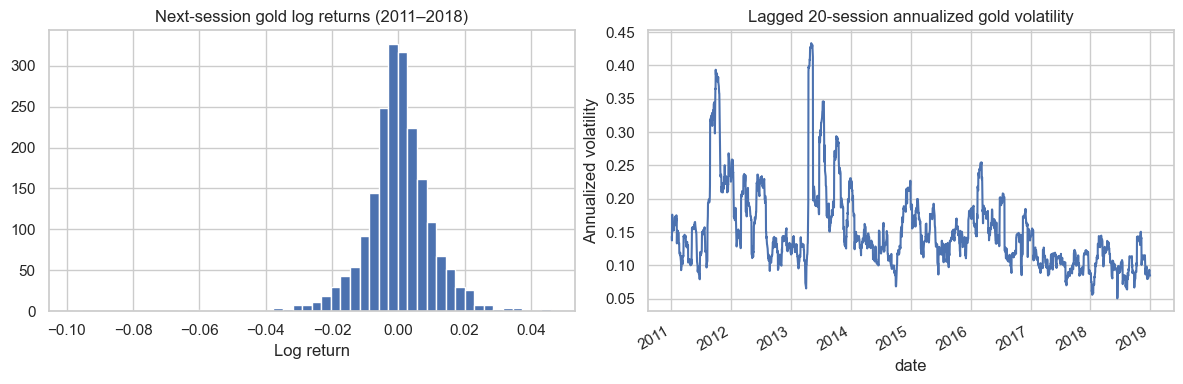

Exploratory correlations with next-session gold returns:


,correlation
lag1_gold_momentum_20,-0.0156
lag1_gold_log_return,0.0010
lag1_gold_volatility_20,0.0076
lag1_gold_momentum_5,0.0126
lag1_vix_change,0.0230
lag1_vix,0.0240


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
model_main[TARGET].dropna().hist(bins=50, ax=axes[0])
axes[0].set_title("Next-session gold log returns (2011–2018)")
axes[0].set_xlabel("Log return")
model_main["lag1_gold_volatility_20"].plot(ax=axes[1])
axes[1].set_title("Lagged 20-session annualized gold volatility")
axes[1].set_ylabel("Annualized volatility")
plt.tight_layout()
plt.show()

# Descriptive correlations with the future target; not out-of-sample results.
correlations = model_main[CORE_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET)
print("Exploratory correlations with next-session gold returns:")
display(correlations.sort_values().to_frame("correlation").round(4))

## 22. Leakage checks

We explicitly verify that the next-session outcome is correctly shifted, that all predictive financial features have a `lag1_` prefix, and that news counts are shifted. This is a basic automated sanity check, **not a complete proof of point-in-time integrity**. Real-world backtesting still requires careful checking of execution prices and the publication timestamps of each source.

In [32]:
# Check the target is equal to the NEXT gold close-to-close log return.
expected_target = prices["gold_log_return"].shift(-1).loc[model_main.index]
assert np.allclose(model_main[TARGET], expected_target, equal_nan=True)

# Check that gold's most recent input uses the PREVIOUS available gold session.
expected_lagged_return = prices["gold_log_return"].shift(1).loc[model_main.index]
assert np.allclose(model_main["lag1_gold_log_return"], expected_lagged_return,
                   equal_nan=True)

assert all(name.startswith("lag1_") for name in EXTENDED_FEATURES)
assert model_main.index.is_monotonic_increasing
assert model_main.index.is_unique
assert model_main.loc["2018-12-31":, TARGET].notna().any()
print("Basic time-order and target-alignment checks passed.")

Basic time-order and target-alignment checks passed.


## 23. Define a fixed chronological evaluation plan

We do not train models yet, but we specify the future evaluation protocol **before looking at any model performance**:

- **2011–2015:** candidate training period.
- **2016:** validation / hyperparameter selection period.
- **2017–2018:** final out-of-sample period (untouched for tuning).

This is a simple initial design; later walk-forward retraining may use expanding training windows, but every prediction must only use earlier observations. All model comparisons will use the same target dates, with preprocessing (scaling, TF-IDF, imputation) fitted on training data only.

In [33]:
# Calendar labels for the later ML phase; this is NOT a random split.
model_main["sample_split"] = "unassigned"
model_main.loc["2011":"2015", "sample_split"] = "train"
model_main.loc["2016", "sample_split"] = "validation"
model_main.loc["2017":"2018", "sample_split"] = "test"

split_report = model_main.groupby("sample_split").agg(
    sessions=(TARGET, "size"),
    targets_available=(TARGET, "count"),
    news_days=("known_has_news", "sum")
)
display(split_report)

# Confirm that the core model has examples in every part of the timeline.
for split in ["train", "validation", "test"]:
    count = len(model_main.loc[model_main["sample_split"] == split].dropna(
        subset=CORE_FEATURES + [TARGET]))
    print(f"{split}: {count} complete core-feature rows")

,sessions,targets_available,news_days
sample_split,,,
test,501,501,498
train,1258,1258,1123
validation,250,250,236


train: 1258 complete core-feature rows
validation: 250 complete core-feature rows
test: 501 complete core-feature rows


## 24. Save the Phase 2 output

We export the full prepared dataset, the main period, the wider robustness period and the missing-data report. The files contain a **future-return target**; keep it separate from input features when training any estimator. We also save the delayed news counts as a transparent availability baseline for the next NLP stage.

In [34]:
# Save and clearly name all outputs.
model_data.to_csv(DATA_DIR / "phase2_full_prepared.csv")
model_main.to_csv(DATA_DIR / "phase2_main_2011_2018.csv")
model_robustness.to_csv(DATA_DIR / "phase2_robustness_2008_2018.csv")
coverage_report.to_csv(DATA_DIR / "phase2_missingness.csv")
news_timing.to_csv(DATA_DIR / "phase2_news_date_mapping.csv", index=False)
split_report.to_csv(DATA_DIR / "phase2_split_report.csv")

print("Phase 2 files saved to", DATA_DIR.resolve())

Phase 2 files saved to /Users/mac/projet_ml_trading/data


## 25. Phase 2 Conclusions and Research Design Decisions

### 25.1 Dataset construction and forecasting objective

We constructed a daily forecasting dataset for gold futures using historical gold prices, return-based indicators, market stress variables, and optional macro-financial controls. Our prediction target is the **next-session log return**, defined as

$$y_t = \log\left(\frac{P_{t+1}}{P_t}\right).$$

Financial predictors were lagged by one gold trading session. This conservative convention reduces the risk of using market observations that were not available at the intended decision time. Consequently, our features are deliberately older than the information that might be available at the current close. We will maintain the same timing convention for all competing models.

### 25.2 Sample size and completeness

The main sample runs from **January 2011 to December 2018** and contains **2,009 gold trading sessions**. The core financial feature set (lagged gold return, five- and twenty-session momentum, twenty-session realized volatility, VIX level, and VIX change) provides **2,009 complete observations (100%)**.

The extended feature set adds the **10-year nominal Treasury yield, 10-year real Treasury yield, and U.S. dollar-index return**. It provides **1,996 complete observations out of 2,009 (99.35%)**, with only **13 observations missing**. Thus, missing financial data should not be a major obstacle to the forecasting exercise. The core and extended specifications will nevertheless be compared on identical test dates whenever their performance is contrasted.

Our wider **2008–2018** sample contains **2,766 gold trading sessions** and is retained for robustness analysis. In particular, it permits an investigation of the 2008 financial-crisis period, although headline coverage is less complete in the earlier years.

### 25.3 News availability and temporal alignment

News headlines contain publication dates but not verified intraday publication times. We therefore map each headline to the same or next available gold trading session and delay its availability by one additional trading session. This also retains headlines published during weekends or market holidays. In the main sample, **1,123 of 1,258 training sessions**, **236 of 250 validation sessions**, and **498 of 501 test sessions** have a positive delayed news count.

These counts describe the **availability of news**, not the existence of a useful sentiment signal. The news corpus is predominantly labeled as retrospective, which creates a risk that headlines describe price movements already realized. During Phase 3, we will extract textual signals while preserving this alignment rule and will investigate whether removing retrospective headlines changes the findings.

### 25.4 Preliminary financial relationships

Exploratory linear correlations between the core financial predictors and next-session gold returns are small. For example, the correlations are approximately **0.0240 for the lagged VIX level**, **0.0230 for lagged VIX changes**, and **−0.0156 for lagged twenty-session gold momentum**. These descriptive statistics do not establish that the predictors lack nonlinear predictive content, nor do they measure out-of-sample forecasting accuracy.

They instead reinforce the motivation for testing whether news-derived information provides **incremental predictive value** beyond conventional financial variables. That hypothesis remains untested at the end of Phase 2.

### 25.5 Chronological evaluation design

To prevent look-ahead bias, we have defined the following chronological sample split before fitting any machine-learning models:

| Subsample | Period | Gold trading sessions |
|---|---|---:|
| Training | 2011–2015 | 1,258 |
| Validation | 2016 | 250 |
| Final out-of-sample test | 2017–2018 | 501 |

The training period will be used to fit preprocessing transformations and forecasting models; the validation period will be used for hyperparameter selection; and the test period will be reserved for final evaluation. More advanced expanding-window evaluation may be added later. All financial-only and financial-plus-NLP comparisons must use the **same target observations and execution assumptions**.

### 25.6 Limitations

Several issues must be considered before drawing financial conclusions. First, the Yahoo Finance continuous gold-futures history may be affected by contract-roll conventions. Second, daily headlines do not provide enough timing information to reconstruct exact intraday availability; our one-session delay is a conservative approximation rather than proof of point-in-time integrity. Third, some historical macroeconomic series may contain revised observations. In particular, the historical **GPR index is retained for descriptive stress analysis, not as a core predictive feature**, unless its publication and revision timing can be established. Finally, correlations calculated on the full sample are exploratory and must not be interpreted as forecast performance.

### 25.7 Decision for Phase 3

**Phase 2 is complete and the project can proceed to NLP feature engineering.** The main dataset is sufficiently large and complete for parsimonious predictive models. Phase 3 will compare (i) the corpus's existing headline sentiment labels, (ii) FinBERT probabilities and aggregate sentiment scores, and (iii) TF-IDF representations. The text-derived variables will be aligned with the same conservative information timing used here.

The next research milestone is to determine whether these textual signals improve **out-of-sample prediction** relative to the financial-only benchmarks. No predictive improvement or trading profitability has yet been demonstrated.

### Phase 2 references

- FRED: [VIXCLS](https://fred.stlouisfed.org/series/VIXCLS), [DGS10](https://fred.stlouisfed.org/series/DGS10), [DFII10](https://fred.stlouisfed.org/series/DFII10).
- Yahoo Finance: [GC=F gold futures](https://finance.yahoo.com/quote/GC=F/history/).
- Caldara & Iacoviello: [Geopolitical Risk Index](https://www.matteoiacoviello.com/gpr.htm).
- Champonnois (2026), *Machine-learning for Portfolio Management and Trading*, especially chapters on backtesting, return data quality, and out-of-sample predictability.

---
# Phase 3 — News Sentiment and NLP Feature Engineering

**Research objective.** Transform historical gold-related headlines into numerical, **point-in-time** indicators that can later be tested for incremental predictive power over the financial variables constructed in Phase 2.

We compare three complementary text representations:

1. **Human annotations:** gold-price sentiment labels provided with the dataset.
2. **FinBERT:** probability-based general financial tone measured by a pre-trained transformer.
3. **TF-IDF:** text content rather than sentiment, using a vocabulary fitted only on training-period news.

**Important distinction:** a *positive financial tone* is not necessarily *bullish for gold*. We do not assume that FinBERT sentiment and manually annotated gold-price sentiment measure the same concept.

We retain the Phase 2 trading calendar, forecast target and split: **train 2011–2015, validation 2016, test 2017–2018**. No predictive model will be trained on gold returns in Phase 3.

## 26. Check inputs and fix the timing convention

We reuse `news`, `news_timing`, `model_main`, `model_data`, `prices`, `TARGET` and `DATA_DIR` from the previous phases. **Run the notebook from the beginning** before running these cells.

Headlines have calendar dates but no verified publication times. Therefore:

- A headline dated on a gold trading day is assigned to that day; a headline on a non-trading day is assigned to the next trading day.
- The aggregate is **shifted forward by one additional trading session** before it enters the model.
- The predictive row dated $t$ uses only the shifted aggregate and predicts the next-session return $r_{t+1}$.

This convention is deliberately conservative. It mitigates unavailable intraday timestamps, but cannot prove the original publication timestamps were accurate.

In [35]:
# Make sure earlier phases were executed.
needed = ["date", "headline", "Price Sentiment", "Future Information", "Past Information"]
assert all(column in news.columns for column in needed), "Phase 1 news data are missing."
assert {"date", "headline", "assigned_trading_day"}.issubset(news_timing.columns), "Run Phase 2 first."
assert model_main.index.is_unique and model_main.index.is_monotonic_increasing
assert TARGET in model_main.columns and "sample_split" in model_main.columns

# Retain all historical articles for mapping, but focus model features on 2011–2018.
print("News rows:", len(news))
print("Mapped news rows:", len(news_timing))
print("Main sample rows:", len(model_main))
print(model_main["sample_split"].value_counts().sort_index())

News rows: 10404
Mapped news rows: 10404
Main sample rows: 2009
sample_split
test           501
train         1258
validation     250
Name: count, dtype: int64


## 27. Clean the dataset's original gold-price sentiment labels

The dataset's `Price Sentiment` field has four observed values: `positive`, `negative`, `neutral` and `none`.

We convert them to a simple directional measure:

$$s_i^{gold}=\begin{cases} +1&\text{positive}\\ 0&\text{neutral}\\ -1&\text{negative}\\ \mathrm{NaN}&\text{none}\end{cases}$$

**Why `NaN` for `none`?** The original `none` label indicates an unavailable/undetermined gold-price sentiment, not neutral news. Misclassifying it as zero would distort daily averages. We also retain the proportion of labeled and prospective headlines.

The `Future Information` field describes *prospective language within the headline*, not a realized future gold return or proof that the article was published before the trading decision.

In [36]:
# Normalize label spelling before mapping to numeric scores.
news_nlp = news[["date", "headline", "Price Sentiment",
                 "Past Information", "Future Information"]].copy()
news_nlp["gold_label"] = news_nlp["Price Sentiment"].astype(str).str.strip().str.lower()
label_to_score = {"positive": 1.0, "negative": -1.0, "neutral": 0.0}
news_nlp["gold_sentiment"] = news_nlp["gold_label"].map(label_to_score)
news_nlp["is_prospective"] = pd.to_numeric(news_nlp["Future Information"], errors="coerce").eq(1)
news_nlp["is_retrospective"] = pd.to_numeric(news_nlp["Past Information"], errors="coerce").eq(1)

print("Gold-price sentiment labels:")
print(news_nlp["gold_label"].value_counts(dropna=False))
print("Labeled fraction:", round(news_nlp["gold_sentiment"].notna().mean(), 3))
print("Prospective articles:", int(news_nlp["is_prospective"].sum()))
display(news_nlp.head(5))

Gold-price sentiment labels:
gold_label
positive    4331
negative    3759
none        1940
neutral      374
Name: count, dtype: int64
Labeled fraction: 0.814
Prospective articles: 314


,date,headline,Price Sentiment,Past Information,Future Information,gold_label,gold_sentiment,is_prospective,is_retrospective
0,2000-02-15,gold is poised for greatness,positive,1,0,positive,1.0,False,True
1,2000-02-17,gold falls on technical pull back,negative,1,0,negative,-1.0,False,True
2,2000-03-24,gold quiet on lack of market news,neutral,1,0,neutral,0.0,False,True
3,2000-04-27,gold futures steady as index climbs,neutral,1,0,neutral,0.0,False,True
4,2000-05-04,gold and silver stocks in relief rally,positive,1,0,positive,1.0,False,True


## 28. Inspect headline labels and potential NLP pitfalls

A good sentiment score needs a meaningful definition. FinBERT predicts **positive/neutral/negative tone**, whereas the corpus' manual price-sentiment annotations relate to **the direction described for gold**. We should not treat the two as interchangeable.

A basic count plot reveals whether the labels are balanced. A small manual review helps detect cases in which negative general news is actually bullish for gold (for example, an escalation in geopolitical uncertainty).

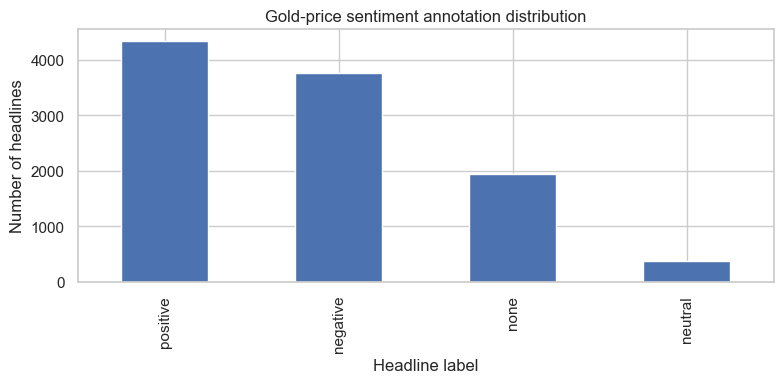

,headline,gold_label,is_prospective
6784,"gold wipes off losses, trading marginally high...",negative,False
9368,gold futures mark first decline in 5 sessions,negative,False
5239,Gold prices ease in Asia as dollar mostly stea...,none,False
4860,"Gold prices ease in Asia on profit taking, Ukr...",none,False
2932,gold buyers return to shop ahead of diwali as ...,none,False
9494,blockchain & the gold standard for a conflict-...,none,False
7861,"August gold falls $4.20, or 0.3%, at $1,245/oz.",negative,False
3881,"gold settles higher, recoups part of tuesday loss",positive,False
2340,"gold adds to loss after consumer gauge, oil lower",negative,False
1702,gold glitters on stockists' buying,positive,False


In [37]:
# Display the human-label distribution and a reproducible manual review sample.
fig, ax = plt.subplots(figsize=(8, 4))
news_nlp["gold_label"].value_counts().plot(kind="bar", ax=ax)
ax.set(title="Gold-price sentiment annotation distribution",
       xlabel="Headline label", ylabel="Number of headlines")
plt.tight_layout()
plt.show()

manual_review = news_nlp[["headline", "gold_label", "is_prospective"]].sample(
    n=min(25, len(news_nlp)), random_state=42
)
display(manual_review)

## 29. Align all headline-level information with the Phase 2 trading calendar

We merge the NLP table onto the **existing** `news_timing` mapping, rather than inventing a second alignment procedure. The mapping uses the original date and headline pair, both unique after Phase 1 cleaning.

We then verify that the number of mapped headlines exactly matches Phase 2. Any mismatch must be fixed before proceeding.

In [38]:
# Combine annotation data with the trading-day mapping established in Phase 2.
mapped_news = news_timing.merge(
    news_nlp,
    on=["date", "headline"], how="left", validate="one_to_one"
)
assert len(mapped_news) == len(news_timing), "Headline mapping changed unexpectedly."
assert mapped_news["gold_label"].notna().all(), "Missing annotations after mapping."

print("Mapped articles:", len(mapped_news))
display(mapped_news.head(5))

Mapped articles: 10404


,date,headline,assigned_trading_day,Price Sentiment,Past Information,Future Information,gold_label,gold_sentiment,is_prospective,is_retrospective
0,2000-02-15,gold is poised for greatness,2000-08-30,positive,1,0,positive,1.0,False,True
1,2000-02-17,gold falls on technical pull back,2000-08-30,negative,1,0,negative,-1.0,False,True
2,2000-03-24,gold quiet on lack of market news,2000-08-30,neutral,1,0,neutral,0.0,False,True
3,2000-04-27,gold futures steady as index climbs,2000-08-30,neutral,1,0,neutral,0.0,False,True
4,2000-05-04,gold and silver stocks in relief rally,2000-08-30,positive,1,0,positive,1.0,False,True


## 30. Construct simple daily gold-price sentiment features

For each *assigned* trading day $d$, we calculate:

$$S_d^{gold}=\frac{1}{N_d^{labeled}}\sum_{i \in d,\; labeled}s_i^{gold}$$

Other indicators include the fraction of negative headlines, fraction of prospective headlines, total article count, and number of labeled articles.

**Missing-data policy:** an average sentiment cannot be computed on a day with no labeled news. We preserve missingness in the diagnostic columns, then use a zero-filled score **together with an availability indicator** in the final numerical dataset. This does not imply that a no-news day is emotionally neutral.

In [39]:
# Aggregate information for each originally assigned trading session.
daily_labels = mapped_news.groupby("assigned_trading_day").agg(
    n_headlines=("headline", "size"),
    n_labeled=("gold_sentiment", "count"),
    gold_sentiment_mean=("gold_sentiment", "mean"),
    gold_negative_share=("gold_sentiment", lambda x: (x.dropna() == -1).mean() if x.notna().any() else np.nan),
    prospective_share=("is_prospective", "mean"),
    n_prospective=("is_prospective", "sum")
)

# Align to every gold trading session, including sessions without news.
daily_labels = daily_labels.reindex(prices.index)
daily_labels[["n_headlines", "n_labeled", "n_prospective"]] = (
    daily_labels[["n_headlines", "n_labeled", "n_prospective"]].fillna(0)
)
daily_labels["has_labeled_news"] = daily_labels["n_labeled"] > 0

# Apply the SAME one-session delay as Phase 2 news counts.
labels_known = daily_labels.shift(1).add_prefix("known_")
labels_known[["known_n_headlines", "known_n_labeled", "known_n_prospective"]] = (
    labels_known[["known_n_headlines", "known_n_labeled", "known_n_prospective"]].fillna(0)
)
labels_known["known_has_labeled_news"] = labels_known["known_has_labeled_news"].fillna(False).astype(bool)

# Zero-filled modeling versions; diagnostics keep the original NaNs.
for name in ["known_gold_sentiment_mean", "known_gold_negative_share", "known_prospective_share"]:
    labels_known[name + "_filled"] = labels_known[name].fillna(0.0)

assert np.array_equal(
    labels_known.loc[model_main.index, "known_n_headlines"].astype(int).to_numpy(),
    model_main["known_news_count"].astype(int).to_numpy()
), "Mismatch with Phase 2 known_news_count."
print("Daily label features correctly match the Phase 2 mapping.")
display(labels_known.loc[MAIN_START:MAIN_END].head())

Daily label features correctly match the Phase 2 mapping.


/var/folders/ns/8xtf5wz14fd1fsmfvc84_dyw0000gn/T/ipykernel_5059/2208205319.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  labels_known["known_has_labeled_news"] = labels_known["known_has_labeled_news"].fillna(False).astype(bool)


,known_n_headlines,known_n_labeled,known_gold_sentiment_mean,known_gold_negative_share,known_prospective_share,known_n_prospective,known_has_labeled_news,known_gold_sentiment_mean_filled,known_gold_negative_share_filled,known_prospective_share_filled
date,,,,,,,,,,
2011-01-03,2.0,2.0,0.0,0.5,0.0,0.0,True,0.0,0.5,0.0
2011-01-04,0.0,0.0,NaN,NaN,NaN,0.0,False,0.0,0.0,0.0
2011-01-05,1.0,1.0,1.0,0.0,0.0,0.0,True,1.0,0.0,0.0
2011-01-06,0.0,0.0,NaN,NaN,NaN,0.0,False,0.0,0.0,0.0
2011-01-07,2.0,1.0,-1.0,1.0,0.0,0.0,True,-1.0,1.0,0.0


## 31. Visualize the annotated sentiment series

We now describe—not predict—the evolution of headline sentiment. We compare the daily sentiment score with a short moving average, and separately plot news volume. The smoothing shown here is only a descriptive visualization; later ML features must be created using past observations only.

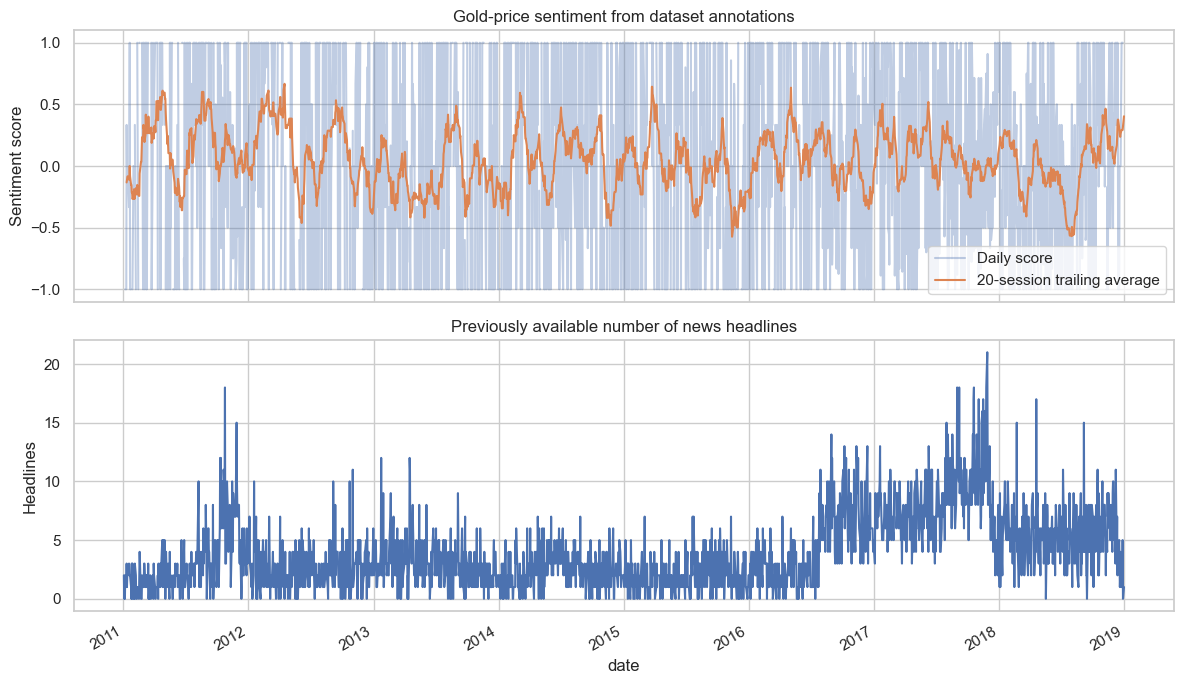

In [40]:
# Plot the delayed daily signal and its trailing 20-session mean.
plot_labels = labels_known.loc[MAIN_START:MAIN_END].copy()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
plot_labels["known_gold_sentiment_mean"].plot(ax=axes[0], alpha=0.35, label="Daily score")
plot_labels["known_gold_sentiment_mean"].rolling(20, min_periods=5).mean().plot(
    ax=axes[0], label="20-session trailing average"
)
axes[0].set(title="Gold-price sentiment from dataset annotations", ylabel="Sentiment score")
axes[0].legend()
plot_labels["known_n_headlines"].plot(ax=axes[1])
axes[1].set(title="Previously available number of news headlines", ylabel="Headlines")
plt.tight_layout()
plt.show()

## 32. Install and load FinBERT (one-time setup)

We use the pre-trained model [`ProsusAI/finbert`](https://huggingface.co/ProsusAI/finbert). It returns probabilities for **positive**, **negative** and **neutral** financial tone for each headline.

Our signal is

$$S_i^{FinBERT}=P(positive\mid headline_i)-P(negative\mid headline_i).$$

This value ranges from -1 to +1. **It is not automatically a directional forecast for gold.** FinBERT is trained for generic financial sentiment and may disagree with the dataset's gold-price labels for economically meaningful reasons.

The first download needs internet access, and inference can be slow on a CPU. We save a local cache so subsequent notebook runs do not recompute the scores. Run the installation cell once, then restart the kernel if imports require it.

In [41]:
# Uncomment and run ONCE if packages are not yet installed.
#%pip install -q "transformers>=4.40,<5" torch

import importlib.util
for package in ["transformers", "torch"]:
    if importlib.util.find_spec(package) is None:
        raise ImportError(f"Install {package} using the pip command above, then rerun this cell.")

from transformers import pipeline
print("FinBERT dependencies are available.")

FinBERT dependencies are available.


## 33. Run FinBERT on the main research sample and save progress

For computational efficiency we score **only headlines assigned to trading days through 2018**. The model is not fitted to our gold-return data, so we may use a fixed pre-trained checkpoint to score train, validation and test news; the gold-return prediction model will still be trained on the training period only.

The next cell writes one CSV per batch in `data/finbert_batches/`. This is useful when computing the scores for several thousand headlines on a laptop. Re-running the cell skips completed batches. To avoid unexpected results, do not reorder the news table or change `FINBERT_BATCH_ROWS` when resuming a partially computed cache; delete the batch folder if you change those settings.

In [42]:
from pathlib import Path

# Keep only articles relevant for the main research period, but include previous
# sessions so a beginning-of-sample signal can be calculated when available.
finbert_articles = mapped_news.loc[
    mapped_news["assigned_trading_day"] <= pd.Timestamp(MAIN_END),
    ["date", "headline", "assigned_trading_day"]
].sort_values(["date", "headline"]).reset_index(drop=True)

FINBERT_BATCH_ROWS = 250      # Save every 250 headlines to make reruns easier.
FINBERT_INFERENCE_BATCH = 16  # Reduce to 8 if memory is limited.
FINBERT_DIR = DATA_DIR / "finbert_batches"
FINBERT_DIR.mkdir(parents=True, exist_ok=True)

print("Headlines to score:", len(finbert_articles))
print("Cache location:", FINBERT_DIR.resolve())

Headlines to score: 10378
Cache location: /Users/mac/projet_ml_trading/data/finbert_batches


In [43]:
import huggingface_hub, os
print(huggingface_hub.__version__, os.path.dirname(huggingface_hub.__file__))

from transformers import AutoModelForSequenceClassification
try:
    AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert")
    print("Chargement OK")
except Exception as e:
    c = e
    while c is not None:
        print(type(c).__name__, ":", str(c)[:300])
        c = c.__context__

0.35.3 /Users/mac/anaconda3/envs/jupyter_clean/lib/python3.11/site-packages/huggingface_hub
Chargement OK


In [44]:
# Run this cell on your computer. It may take a while the first time on a CPU.
# The cache allows you to resume without repeating completed chunks.

from huggingface_hub import snapshot_download
from transformers import pipeline


FINBERT_LOCAL = DATA_DIR / "finbert_model"
if not FINBERT_LOCAL.exists():
    snapshot_download(
        repo_id="ProsusAI/finbert",
        local_dir=FINBERT_LOCAL,
        allow_patterns=["*.json", "*.txt", "*.safetensors", "pytorch_model.bin"],
    )

sentiment_model = pipeline(
    "text-classification",
    model=str(FINBERT_LOCAL),
    tokenizer=str(FINBERT_LOCAL),
    device=-1,  # CPU
)
for start in range(0, len(finbert_articles), FINBERT_BATCH_ROWS):
    end = min(start + FINBERT_BATCH_ROWS, len(finbert_articles))
    cache_file = FINBERT_DIR / f"finbert_{start:05d}_{end:05d}.csv"
    if cache_file.exists():
        continue

    chunk = finbert_articles.iloc[start:end].copy()
    # top_k=None returns all class probabilities, not just the winning class.
    outputs = sentiment_model(
        chunk["headline"].tolist(), top_k=None, truncation=True,
        batch_size=FINBERT_INFERENCE_BATCH
    )
    for label in ["positive", "negative", "neutral"]:
        chunk[f"p_{label}"] = [
            next(float(score["score"]) for score in result
                 if score["label"].lower() == label)
            for result in outputs
        ]
    chunk.to_csv(cache_file, index=False)
    print(f"Saved {end:,} / {len(finbert_articles):,} headlines")

print("FinBERT scoring finished.")

Device set to use cpu


FinBERT scoring finished.


## 34. Load and check FinBERT probabilities

Each headline should have three nonnegative probabilities adding to approximately one. We calculate the probability difference and quantify its agreement with the manual gold-price labels. Agreement is **not** expected to be perfect: the tasks have different definitions.

In [45]:
# Load all completed cached chunks in their original order.
expected_files = [
    FINBERT_DIR / f"finbert_{i:05d}_{min(i + FINBERT_BATCH_ROWS, len(finbert_articles)):05d}.csv"
    for i in range(0, len(finbert_articles), FINBERT_BATCH_ROWS)
]
missing_files = [path.name for path in expected_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"FinBERT has unfinished batches: {missing_files[:5]}. Run step 33.")

finbert_scored = pd.concat([pd.read_csv(path) for path in expected_files], ignore_index=True)
assert len(finbert_scored) == len(finbert_articles)
assert (finbert_scored[["p_positive", "p_negative", "p_neutral"]].sum(axis=1) - 1).abs().max() < 0.01
finbert_scored["finbert_score"] = finbert_scored["p_positive"] - finbert_scored["p_negative"]
finbert_scored["date"] = pd.to_datetime(finbert_scored["date"])
finbert_scored["assigned_trading_day"] = pd.to_datetime(finbert_scored["assigned_trading_day"])

print(finbert_scored["finbert_score"].describe().round(3))
display(finbert_scored[["date", "headline", "finbert_score"]].head())

count    10378.000
mean        -0.058
std          0.706
min         -0.968
25%         -0.872
50%          0.024
75%          0.675
max          0.937
Name: finbert_score, dtype: float64


,date,headline,finbert_score
0,2000-02-15,gold is poised for greatness,0.382068
1,2000-02-17,gold falls on technical pull back,-0.748821
2,2000-03-24,gold quiet on lack of market news,-0.350879
3,2000-04-27,gold futures steady as index climbs,0.132909
4,2000-05-04,gold and silver stocks in relief rally,-0.070426


## 35. Compare FinBERT with the dataset's gold-price annotations

This is a useful diagnostic of construct validity: **FinBERT measures the general tone of financial language; the manual labels measure sentiment about gold prices**. Large differences may reveal domain-specific phrases or headlines containing mixed signals.

The comparison below is descriptive. We do not modify model labels based on the realized future return.

Correlation between FinBERT and annotated gold sentiment: 0.801


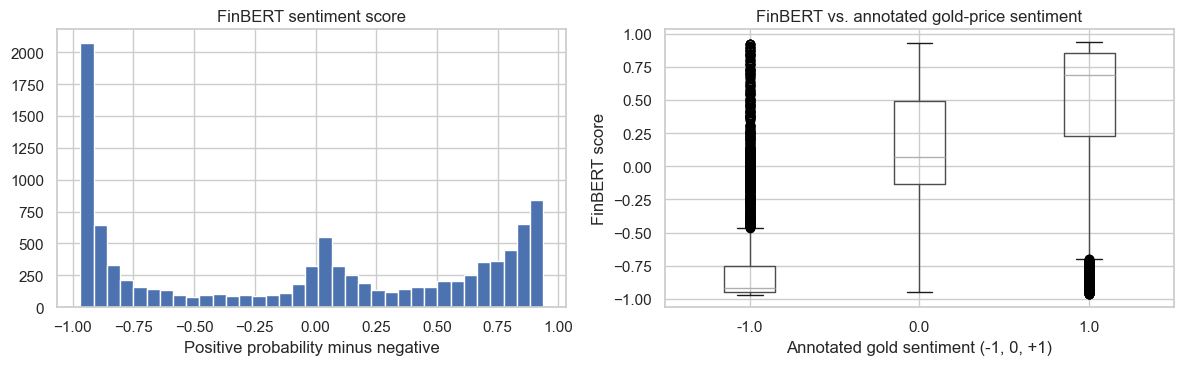

In [46]:
# Join with manual labels to inspect agreement without using market returns.
compare_sentiment = finbert_scored.merge(
    news_nlp[["date", "headline", "gold_sentiment"]],
    on=["date", "headline"], how="left", validate="one_to_one"
)
compare_labeled = compare_sentiment.dropna(subset=["gold_sentiment"])
print("Correlation between FinBERT and annotated gold sentiment:",
      round(compare_labeled["finbert_score"].corr(compare_labeled["gold_sentiment"]), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
compare_sentiment["finbert_score"].hist(bins=35, ax=axes[0])
axes[0].set(title="FinBERT sentiment score", xlabel="Positive probability minus negative")
compare_labeled.boxplot(column="finbert_score", by="gold_sentiment", ax=axes[1])
axes[1].set(title="FinBERT vs. annotated gold-price sentiment",
            xlabel="Annotated gold sentiment (-1, 0, +1)", ylabel="FinBERT score")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 36. Create daily FinBERT signals and apply the news delay

We aggregate **article-level scores before time shifting**. The core variables are the mean FinBERT score, the share of negative-score headlines, the standard deviation of sentiment, and the daily number of articles.

A missing-news day has no well-defined mean; we retain a missing value for diagnostics and use a separate zero-filled modeling column together with `known_has_finbert_news`.

In [47]:
daily_finbert = finbert_scored.groupby("assigned_trading_day").agg(
    finbert_mean=("finbert_score", "mean"),
    finbert_dispersion=("finbert_score", "std"),
    finbert_negative_share=("finbert_score", lambda x: (x < -0.2).mean()),
    finbert_news_count=("finbert_score", "size")
).reindex(prices.index)

# A standard deviation requires two articles; zero dispersion for one article.
daily_finbert.loc[daily_finbert["finbert_news_count"] == 1, "finbert_dispersion"] = 0.0
finbert_known = daily_finbert.shift(1).add_prefix("known_")
finbert_known["known_finbert_news_count"] = finbert_known["known_finbert_news_count"].fillna(0)
finbert_known["known_has_finbert_news"] = finbert_known["known_finbert_news_count"] > 0

for col in ["known_finbert_mean", "known_finbert_dispersion", "known_finbert_negative_share"]:
    finbert_known[col + "_filled"] = finbert_known[col].fillna(0.0)

# The FinBERT subset should include every assigned article in the main sample.
assert np.array_equal(
    finbert_known.loc[model_main.index, "known_finbert_news_count"].astype(int).to_numpy(),
    model_main["known_news_count"].astype(int).to_numpy()
), "FinBERT articles and Phase 2 news-count signal are not aligned."
print("FinBERT daily signals are aligned and shifted.")
display(finbert_known.loc[MAIN_START:MAIN_END].head())

FinBERT daily signals are aligned and shifted.


,known_finbert_mean,known_finbert_dispersion,known_finbert_negative_share,known_finbert_news_count,known_has_finbert_news,known_finbert_mean_filled,known_finbert_dispersion_filled,known_finbert_negative_share_filled
date,,,,,,,,
2011-01-03,0.038349,1.180598,0.5,2.0,True,0.038349,1.180598,0.5
2011-01-04,NaN,NaN,NaN,0.0,False,0.000000,0.000000,0.0
2011-01-05,0.455190,0.000000,0.0,1.0,True,0.455190,0.000000,0.0
2011-01-06,NaN,NaN,NaN,0.0,False,0.000000,0.000000,0.0
2011-01-07,-0.337504,0.494799,0.5,2.0,True,-0.337504,0.494799,0.5


## 37. Create TF-IDF documents without fitting on future data

TF-IDF measures **word importance**, not sentiment. For simplicity, we concatenate headlines assigned to the same trading day into one daily document. We then shift that document forward by one trading session, following the same availability rule as the numeric news features.

**Critical anti-leakage rule:** we fit the `TfidfVectorizer` using **training-period documents only (2011–2015)** and use `transform()` on validation and test documents. Fitting the vocabulary/IDF on the full 2011–2018 corpus would use information from future text distributions.

To avoid unnecessary complexity, we use lowercase text, English stopwords, unigrams and bigrams, and at most 500 terms. Empty documents produce zero rows in the sparse representation.

In [48]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy import sparse

# Aggregate today's headlines into a single document per assigned trading day.
daily_text = mapped_news.groupby("assigned_trading_day")["headline"].apply(" ".join)
daily_text = daily_text.reindex(prices.index, fill_value="")
known_daily_text = daily_text.shift(1).fillna("")

# Match exactly the same chronological rows as the Phase 2 main sample.
text_main = known_daily_text.reindex(model_main.index)
train_rows = model_main["sample_split"].eq("train").to_numpy()

vectorizer = TfidfVectorizer(
    stop_words="english", ngram_range=(1, 2),
    max_features=500, min_df=3, max_df=0.95
)
vectorizer.fit(text_main.iloc[np.flatnonzero(train_rows)])
X_tfidf_main = vectorizer.transform(text_main)

print("Daily TF-IDF matrix shape:", X_tfidf_main.shape)
print("Training-period vocabulary size:", len(vectorizer.vocabulary_))
print("Non-empty daily documents:", (text_main.str.len() > 0).sum())

Daily TF-IDF matrix shape: (2009, 500)
Training-period vocabulary size: 500
Non-empty daily documents: 1857


## 38. Explore the most frequent TF-IDF terms

We display the terms with the largest average TF-IDF weight *on training-period documents only*. This is an exploratory way to check that the vocabulary relates to the gold market. High frequency does not imply that a term predicts returns or is economically important.

,term,mean_tfidf
0,gold,0.165283
1,futures,0.045990
2,gold futures,0.043605
3,silver,0.039687
4,rs,0.037641
5,prices,0.031296
6,gold prices,0.027342
7,higher,0.027235
8,gains,0.027178
9,lower,0.026258


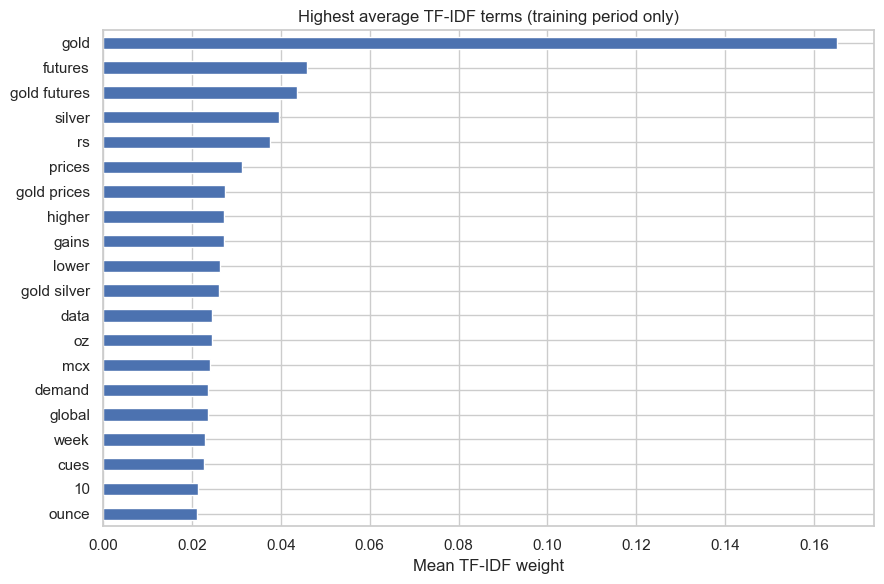

In [49]:
# Inspect vocabulary from the training subset only.
train_matrix = X_tfidf_main[train_rows]
mean_weights = np.asarray(train_matrix.mean(axis=0)).ravel()
terms = vectorizer.get_feature_names_out()
top_idx = np.argsort(mean_weights)[-20:][::-1]
top_terms = pd.DataFrame({"term": terms[top_idx], "mean_tfidf": mean_weights[top_idx]})
display(top_terms)

ax = top_terms.iloc[::-1].plot.barh(x="term", y="mean_tfidf", legend=False, figsize=(9, 6))
ax.set(title="Highest average TF-IDF terms (training period only)", xlabel="Mean TF-IDF weight", ylabel="")
plt.tight_layout()
plt.show()

## 39. Build one Phase 3 modeling table

We now combine the fixed Phase 2 sample with the delayed annotation features and FinBERT features. We deliberately keep TF-IDF in a **separate sparse matrix** because 500 text dimensions would make the daily dataframe harder to inspect.

All feature names begin with `known_` to make their timing explicit. A new model must be evaluated on **the same days** as its financial-only counterpart. In Phase 4, we will choose the final feature set and compare models with/without NLP.

In [50]:
# Merge numeric NLP columns on the fixed financial sample dates.
phase3_main = model_main.join(labels_known, how="left").join(finbert_known, how="left")

NLP_ANNOTATION_FEATURES = [
    "known_gold_sentiment_mean_filled", "known_gold_negative_share_filled",
    "known_prospective_share_filled", "known_has_labeled_news",
    "known_n_labeled", "known_n_headlines"
]
NLP_FINBERT_FEATURES = [
    "known_finbert_mean_filled", "known_finbert_dispersion_filled",
    "known_finbert_negative_share_filled", "known_has_finbert_news"
]

# Convert boolean indicators to numeric for future scikit-learn models.
for col in ["known_has_labeled_news", "known_has_finbert_news"]:
    phase3_main[col] = phase3_main[col].fillna(False).astype(int)

assert phase3_main.index.equals(model_main.index)
assert phase3_main[NLP_ANNOTATION_FEATURES + NLP_FINBERT_FEATURES].notna().all().all()
print("Phase 3 dataset shape:", phase3_main.shape)
print("Total NLP columns:", len(NLP_ANNOTATION_FEATURES + NLP_FINBERT_FEATURES))
display(phase3_main[NLP_ANNOTATION_FEATURES + NLP_FINBERT_FEATURES].head())

Phase 3 dataset shape: (2009, 34)
Total NLP columns: 10


,known_gold_sentiment_mean_filled,known_gold_negative_share_filled,known_prospective_share_filled,known_has_labeled_news,known_n_labeled,known_n_headlines,known_finbert_mean_filled,known_finbert_dispersion_filled,known_finbert_negative_share_filled,known_has_finbert_news
date,,,,,,,,,,
2011-01-03,0.0,0.5,0.0,1,2.0,2.0,0.038349,1.180598,0.5,1
2011-01-04,0.0,0.0,0.0,0,0.0,0.0,0.000000,0.000000,0.0,0
2011-01-05,1.0,0.0,0.0,1,1.0,1.0,0.455190,0.000000,0.0,1
2011-01-06,0.0,0.0,0.0,0,0.0,0.0,0.000000,0.000000,0.0,0
2011-01-07,-1.0,1.0,0.0,1,1.0,2.0,-0.337504,0.494799,0.5,1


## 40. Final alignment and anti-leakage checks

Before moving to predictive modeling, we verify:

1. The prediction target and chronological split have not changed from Phase 2.
2. News-count features agree with the Phase 2 mapping on every date.
3. Text features use the one-session-delayed calendar mapping.
4. TF-IDF was fitted on training documents only.
5. No feature is constructed from future realized gold returns.

A zero news count is not equivalent to zero latent sentiment; we always retain a news-availability indicator.

In [51]:
assert phase3_main[TARGET].equals(model_main[TARGET])
assert phase3_main["sample_split"].equals(model_main["sample_split"])
assert np.array_equal(
    phase3_main["known_n_headlines"].astype(int).to_numpy(),
    model_main["known_news_count"].astype(int).to_numpy()
)
assert (X_tfidf_main.shape[0] == len(phase3_main))
assert not np.isnan(X_tfidf_main.data).any()
assert phase3_main.index.is_monotonic_increasing

# Spot-check the text delay on the raw assigned-news mapping.
expected_text = daily_text.shift(1).fillna("").reindex(phase3_main.index)
assert text_main.equals(expected_text)

# Report the availability of the two sentiment sources in the research sample.
final_report = phase3_main.groupby("sample_split").agg(
    sessions=(TARGET, "size"),
    days_with_news=("known_has_news", "sum"),
    days_with_labeled_news=("known_has_labeled_news", "sum"),
    days_with_finbert_news=("known_has_finbert_news", "sum"),
    total_known_headlines=("known_n_headlines", "sum")
)
display(final_report)
print("All Phase 3 alignment and consistency checks passed.")

,sessions,days_with_news,days_with_labeled_news,days_with_finbert_news,total_known_headlines
sample_split,,,,,
test,501,498,492,498,3410.0
train,1258,1123,1063,1123,3368.0
validation,250,236,231,236,1093.0


All Phase 3 alignment and consistency checks passed.


## 41. Export the Phase 3 results

We save the numeric dataset as CSV and the TF-IDF representation as a sparse `.npz` matrix. A companion CSV preserves the row order. The fitted vectorizer is also saved, so Phase 4 can transform new text **without refitting on the test period**.

The notebook remains the single source of analysis; these files are intermediate outputs, not separate notebooks.

In [52]:
import joblib

phase3_main.to_csv(DATA_DIR / "phase3_main_2011_2018.csv")
finbert_scored.to_csv(DATA_DIR / "phase3_finbert_headlines.csv", index=False)
sparse.save_npz(DATA_DIR / "phase3_tfidf_main.npz", X_tfidf_main)
pd.DataFrame({
    "date": phase3_main.index,
    "sample_split": phase3_main["sample_split"].values,
    "known_daily_text": text_main.values
}).to_csv(DATA_DIR / "phase3_tfidf_row_mapping.csv", index=False)
joblib.dump(vectorizer, DATA_DIR / "phase3_tfidf_vectorizer.joblib")
final_report.to_csv(DATA_DIR / "phase3_nlp_coverage.csv")

print("Phase 3 files saved in:", DATA_DIR.resolve())
print("Numeric rows:", len(phase3_main), "TF-IDF rows:", X_tfidf_main.shape[0])

Phase 3 files saved in: /Users/mac/projet_ml_trading/data
Numeric rows: 2009 TF-IDF rows: 2009


## 42. Phase 3 — Conclusions and Research Design Decisions

### 42.1 NLP data preparation

The cleaned gold-news corpus contains **10,404 headlines**. We mapped the original `Price Sentiment` annotations to numerical scores ($-1$ for negative, $0$ for neutral and $+1$ for positive). The label `none` was retained as **missing sentiment**, rather than incorrectly interpreted as a neutral headline. Approximately **81.4%** of the cleaned articles have an observed gold-price sentiment label.

The dataset is dominated by retrospective reporting: only **314 headlines (3.0%)** are annotated as containing future information. Therefore, the `Future Information` indicator describes the content of a headline and should **not** be interpreted as a reliable predictor of future gold returns by itself. We retain prospective-news shares as an exploratory feature, but avoid training a separate model exclusively on this small subset.

### 42.2 FinBERT sentiment extraction

We successfully generated FinBERT probabilities for **10,378 headlines** assigned to gold trading sessions through the end of 2018, including earlier headlines needed for historical continuity. For each article, the sentiment indicator was defined as:

$$S_i^{FinBERT}=P_i(positive)-P_i(negative).$$

The observed score distribution has a mean of approximately **-0.058**, a standard deviation of **0.706**, and values between **-0.968** and **0.937**. The probability-sum and batch-completeness checks passed.

Among articles with an observed manual gold-price sentiment, FinBERT's score has a correlation of **0.801** with the annotated direction. This suggests substantial agreement between the two measures, although they capture different concepts: FinBERT estimates **general financial tone**, while the manual annotation describes **sentiment concerning the gold price**. Importantly, this correlation is **not** evidence of return predictability.

### 42.3 TF-IDF representation

We aggregated available headlines into one document per assigned gold trading session and applied the same conservative one-session delay used for numerical news features. The TF-IDF vectorizer was fitted **only on training-period documents (2011–2015)** and then applied unchanged to validation and test observations.

The resulting sparse representation has **2,009 daily rows and 500 textual features**. A total of **1,857 daily documents** contain text. Frequent terms include *gold*, *futures*, *gold futures*, *silver* and *prices*. TF-IDF describes the words used in news rather than directly measuring their sentiment. In the next phase, its predictive contribution will be assessed separately from FinBERT and the annotated sentiment indicators.

### 42.4 Daily coverage and chronological consistency

The final dataset preserves the **2,009 observations** and the original chronological split from Phase 2: **1,258 training observations (2011–2015)**, **250 validation observations (2016)** and **501 test observations (2017–2018)**.

After applying the news-availability delay, the number of sessions with headlines is:

| Sample | Total sessions | Sessions with news | Sessions with labeled news |
|---|---:|---:|---:|
| Training | 1,258 | 1,123 | 1,063 |
| Validation | 250 | 236 | 231 |
| Test | 501 | 498 | 492 |
| **Total** | **2,009** | **1,857** | **1,786** |

The available headline counts are **3,368** in training, **1,093** in validation and **3,410** in test. The numerical feature table contains **10 NLP columns**, including sentiment scores, negative-news fractions, dispersion, article counts and availability flags. Missing sentiment averages were preserved for diagnostics and filled with zero **only alongside a separate availability indicator**; a zero-filled value must not be interpreted as observed neutral sentiment.

The consistency checks confirmed that the financial targets, sample labels, article counts and TF-IDF row order match the earlier phases. However, these checks do not prove exact publication-time availability: publication hours are missing, so the one-session delay is a conservative approximation.

### 42.5 Limitations and interpretation

Three limitations are particularly relevant. First, nearly all original headlines are retrospective, meaning that their content often describes already-observed market movements. Second, no verified publication time is available, so intraday tradability cannot be established. Third, FinBERT's general financial tone may differ from the impact of a headline on gold; for example, negative geopolitical news can coincide with demand for gold as a safe-haven asset.

In addition, the FinBERT checkpoint is used as a **fixed, externally pre-trained model**; it is not fine-tuned on the project's chronological training sample. Consequently, our tests will concern the usefulness of its extracted features for future-return prediction, not the performance of a newly trained sentiment classifier. The possibility of article selection bias and changes in news coverage across time should be discussed when interpreting the results.

### 42.6 Research decision and next steps

**Phase 3 is suitable for proceeding to predictive modeling.** We have three complementary text representations: (i) human-annotated gold-price sentiment, (ii) FinBERT probabilities and aggregated sentiment measures, and (iii) a 500-feature TF-IDF representation.

Phase 4 will compare **matched financial-only and financial-plus-NLP models** on the same dates, first with simple historical benchmarks and regularized linear models, then with XGBoost. Scaling, model fitting, hyperparameter selection and any additional text transformations must use only the relevant training history. The **2016 validation set** will support development decisions, while the **2017–2018 test set** will remain untouched until final evaluation.

The central question remains open: **Do these sentiment indicators improve out-of-sample gold-return forecasts beyond the information already contained in financial variables?**


### Phase 3 references

- Sinha, A., & Khandait, T. (2021). *Impact of News on the Commodity Market: Dataset and Results*. [arXiv:2009.04202](https://arxiv.org/abs/2009.04202).
- Araci, D. (2019). *FinBERT: Financial Sentiment Analysis with Pre-trained Language Models*. [arXiv:1908.10063](https://arxiv.org/abs/1908.10063).
- [ProsusAI/finbert model card](https://huggingface.co/ProsusAI/finbert).
- Scikit-learn documentation: [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).

---
# Phase 4 — Out-of-Sample Gold Return Prediction

**Research question.** Does adding news sentiment improve next-session gold return forecasts compared with models trained on financial indicators alone?

In this phase, we compare simple benchmarks, regularized linear regression (Elastic Net), and gradient-boosted trees (XGBoost). We also compare three NLP representations: dataset annotations, FinBERT, and TF-IDF.

**Important research design choices:**

1. We keep the same forecasting target and information timing as in Phases 2–3.
2. All models are evaluated on exactly the same dates.
3. **Training: 2011–2015; validation: 2016; final test: 2017–2018.** We choose settings using validation, *never* the final test.
4. Imputation and numerical scaling are fitted on training observations only.
5. We report weak or negative improvements as legitimate research findings.

This is a **predictive evaluation**, not a trading backtest. Trading rules, turnover, and transaction costs belong to the next phase.

## 43. Check inputs from Phases 1–3

The Phase 4 notebook uses the existing `phase3_main` DataFrame and the TF-IDF matrix `X_tfidf_main`. No separate notebook or re-download is needed if all earlier cells have already been executed.

The following checks prevent accidental changes to the target or the chronological split.

Due to some installation and dependencies problems instead of using `xgboost` package we will use `HistGradientBoostingRegressor` that is equivalent

In [53]:
#%pip install --no-warn-script-location --only-binary=:all: xgboost

In [54]:
from sklearn.ensemble import HistGradientBoostingRegressor

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy import sparse
from sklearn.ensemble import HistGradientBoostingRegressor

assert len(phase3_main) == X_tfidf_main.shape[0]
assert phase3_main.index.is_monotonic_increasing
assert phase3_main.index.is_unique
assert phase3_main[TARGET].notna().all()
assert set(phase3_main["sample_split"].unique()) == {"train", "validation", "test"}

print("Data rows:", len(phase3_main))
print("Target:", TARGET)
print("TF-IDF matrix:", X_tfidf_main.shape)
print(phase3_main["sample_split"].value_counts().sort_index())

Data rows: 2009
Target: target_next_log_return
TF-IDF matrix: (2009, 500)
sample_split
test           501
train         1258
validation     250
Name: count, dtype: int64


## 44. Fix the financial and NLP feature groups

To measure the *incremental* value of news, we compare each enriched model with an otherwise identical financial model.

Our financial baseline contains the lagged gold return, momentum, volatility, VIX, changes in the VIX, and the previously selected optional interest-rate and USD variables. The latter may have missing values, handled by a training-only median imputer.

The annotations and FinBERT groups are kept separate at first to identify which signal—if any—adds predictive information. TF-IDF is an additional representation of the text rather than a direct sentiment score.

In [56]:
# Financial variables were defined in Phase 2; NLP groups in Phase 3.
financial_cols = EXTENDED_FEATURES.copy()
annotation_cols = NLP_ANNOTATION_FEATURES.copy()
finbert_cols = NLP_FINBERT_FEATURES.copy()

feature_sets = {
    "Financial": financial_cols,
    "Financial + Labels": financial_cols + annotation_cols,
    "Financial + FinBERT": financial_cols + finbert_cols,
    "Financial + All Sentiment": financial_cols + annotation_cols + finbert_cols,
}

for name, cols in feature_sets.items():
    assert all(col in phase3_main.columns for col in cols), f"Missing columns: {name}"
    print(f"{name}: {len(cols)} numeric features")

# The same dates will be used by every model, including TF-IDF models.
train_mask = phase3_main["sample_split"].eq("train").to_numpy()
val_mask = phase3_main["sample_split"].eq("validation").to_numpy()
test_mask = phase3_main["sample_split"].eq("test").to_numpy()
train_val_mask = train_mask | val_mask

# Predict returns in basis points: 1 bp = 0.0001 log-return.
# Rescaling y makes regularization values easier to interpret numerically.
y_bps = phase3_main[TARGET].to_numpy(dtype=float) * 10000.0

assert train_mask.sum() > 0 and val_mask.sum() > 0 and test_mask.sum() > 0
assert not (train_mask & val_mask).any()
assert not (train_val_mask & test_mask).any()
print("Train / validation / test:", train_mask.sum(), val_mask.sum(), test_mask.sum())

Financial: 9 numeric features
Financial + Labels: 15 numeric features
Financial + FinBERT: 13 numeric features
Financial + All Sentiment: 19 numeric features
Train / validation / test: 1258 250 501


## 45. Define performance metrics

We report four complementary metrics. Lower **RMSE** and **MAE** indicate better point forecasts; **information coefficient (IC)** measures correlation between predictions and realized returns; **directional accuracy** measures how often the predicted sign is correct.

$$
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_t\left(y_t-\hat y_t\right)^2},\qquad
\mathrm{MAE}=\frac{1}{n}\sum_t\left|y_t-\hat y_t\right|.
$$

We also report out-of-sample $R^2$ relative to the **zero-return forecast**:

$$
R^2_{\mathrm{OOS},0}=1-\frac{\sum_t\left(y_t-\hat y_t\right)^2}{\sum_t y_t^2}.
$$

All errors below are expressed in **basis points of log returns** (bps). On financial returns, negative OOS $R^2$ and weak correlations are entirely possible. Directional accuracy should also be compared with a simple always-positive forecast.

In [57]:
def prediction_metrics(actual, predicted):
    """Return standard out-of-sample metrics (returns measured in bps)."""
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    r2_zero = 1.0 - np.sum((actual - predicted)**2) / np.sum(actual**2)

    # Correlation is undefined for constant forecasts.
    ic = (np.corrcoef(actual, predicted)[0, 1]
          if np.std(predicted) > 1e-12 and np.std(actual) > 1e-12 else np.nan)
    directional_accuracy = np.mean(np.sign(actual) == np.sign(predicted))
    return {"RMSE (bps)": rmse, "MAE (bps)": mae,
            "OOS R2 vs zero": r2_zero, "IC": ic,
            "Directional accuracy": directional_accuracy}

# The zero forecast cannot exploit any market or news information.
zero_val = np.zeros(val_mask.sum())
mean_val = np.full(val_mask.sum(), y_bps[train_mask].mean())
positive_val = np.full(val_mask.sum(), 1.0)

baseline_val = pd.DataFrame({
    "Zero forecast": prediction_metrics(y_bps[val_mask], zero_val),
    "Historical mean": prediction_metrics(y_bps[val_mask], mean_val),
    "Always positive": prediction_metrics(y_bps[val_mask], positive_val),
}).T
print("Validation benchmarks (2016):")
display(baseline_val.round(4))

Validation benchmarks (2016):


,RMSE (bps),MAE (bps),OOS R2 vs zero,IC,Directional accuracy
Zero forecast,101.8896,72.3098,0.0000,NaN,0.000
Historical mean,101.9806,72.2613,-0.0018,NaN,0.512
Always positive,101.8645,72.3338,0.0005,NaN,0.488


## 46. Prepare numeric features without data leakage

Some rate or USD variables have missing observations. We impute them using medians computed **only on the training sample**, then standardize the numerical variables using the same training sample.

For TF-IDF, the vocabulary was already fitted on training text in Phase 3. We append its 500 daily features to the standardized financial inputs. A dense conversion is practical here because the matrix contains only about 2,000 rows and 500 columns; it is not intended for very large corpora.

In [58]:
def prepare_features(columns, fit_mask, use_tfidf=False):
    """Fit preprocessing on fit_mask, apply consistently to every date."""
    numeric = phase3_main[columns].astype(float).to_numpy()
    imputer = SimpleImputer(strategy="median")
    numeric_fit = imputer.fit_transform(numeric[fit_mask])
    numeric_all = imputer.transform(numeric)

    scaler = StandardScaler()
    scaler.fit(numeric_fit)
    X_all = scaler.transform(numeric_all)

    if use_tfidf:
        # Vocabulary/IDF have already been fitted on 2011–2015 in Phase 3.
        X_all = np.hstack([X_all, X_tfidf_main.toarray()])
    return X_all

X_example = prepare_features(financial_cols, train_mask)
print("Financial matrix:", X_example.shape)
assert np.isfinite(X_example).all()
print("Training-only preprocessing check passed.")

Financial matrix: (2009, 9)
Training-only preprocessing check passed.


## 47. Tune Elastic Net on the validation period

Elastic Net balances L1 (sparse) and L2 (stable) regularization. We try a **small, pre-specified** parameter grid, rather than a large search that could overfit a single validation year.

$$
\min_{\beta_0,\beta}\ \frac{1}{2n}\sum_i\left(y_i-\beta_0-X_i^{\top}\beta\right)^2
+\alpha\left[\rho\,\lVert\beta\rVert_1+\frac{1-\rho}{2}\,\lVert\beta\rVert_2^2\right].
$$

We select hyperparameters by **validation RMSE** (2016) and then freeze them before evaluating 2017–2018.

In [59]:
elastic_grid = [
    {"alpha": a, "l1_ratio": ratio}
    for a in [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]
    for ratio in [0.2, 0.8]
]

def tune_elastic(columns, use_tfidf=False):
    X = prepare_features(columns, train_mask, use_tfidf=use_tfidf)
    best = None
    for params in elastic_grid:
        model = ElasticNet(**params, max_iter=10000, random_state=42)
        model.fit(X[train_mask], y_bps[train_mask])
        forecast = model.predict(X[val_mask])
        score = np.sqrt(mean_squared_error(y_bps[val_mask], forecast))
        if best is None or score < best["rmse"]:
            best = {"params": params.copy(), "rmse": score, "predictions": forecast}
    return best

elastic_specs = {
    "Elastic Net | Financial": (financial_cols, False),
    "Elastic Net | Labels": (feature_sets["Financial + Labels"], False),
    "Elastic Net | FinBERT": (feature_sets["Financial + FinBERT"], False),
    "Elastic Net | All Sentiment": (feature_sets["Financial + All Sentiment"], False),
    "Elastic Net | Financial + TF-IDF": (financial_cols, True),
}

elastic_choices = {}
validation_predictions = {"Zero forecast": zero_val,
                          "Historical mean": mean_val,
                          "Always positive": positive_val}

for name, (cols, use_text) in elastic_specs.items():
    selected = tune_elastic(cols, use_tfidf=use_text)
    elastic_choices[name] = selected["params"]
    validation_predictions[name] = selected["predictions"]
    print(name, "| RMSE:", round(selected["rmse"], 3),
          "| Parameters:", selected["params"])

print("Elastic Net validation completed.")

Elastic Net | Financial | RMSE: 101.981 | Parameters: {'alpha': 10.0, 'l1_ratio': 0.8}
Elastic Net | Labels | RMSE: 101.981 | Parameters: {'alpha': 10.0, 'l1_ratio': 0.8}
Elastic Net | FinBERT | RMSE: 101.981 | Parameters: {'alpha': 10.0, 'l1_ratio': 0.8}
Elastic Net | All Sentiment | RMSE: 101.981 | Parameters: {'alpha': 10.0, 'l1_ratio': 0.8}
Elastic Net | Financial + TF-IDF | RMSE: 101.981 | Parameters: {'alpha': 10.0, 'l1_ratio': 0.8}
Elastic Net validation completed.


## 48. Tune XGBoost on the same validation period

Boosted trees can learn nonlinear relationships and interactions between financial variables and sentiment. However, with approximately 1,258 training sessions, tree models may overfit easily. We therefore use shallow trees, a conservative number of boosting rounds, and a small candidate grid.

The two primary XGBoost experiments are **financial-only** and **financial + FinBERT**. We also evaluate a combined sentiment model. All use the same dates and evaluation method.

In [60]:
from sklearn.ensemble import HistGradientBoostingRegressor

xgb_grid = [
    {"max_depth": 2, "n_estimators": 100, "learning_rate": 0.03},
    {"max_depth": 2, "n_estimators": 200, "learning_rate": 0.03},
    {"max_depth": 3, "n_estimators": 100, "learning_rate": 0.03},
    {"max_depth": 3, "n_estimators": 200, "learning_rate": 0.03},
]

def new_xgb(params):
    p = dict(params)
    return HistGradientBoostingRegressor(
        loss="squared_error", random_state=42,
        max_iter=p.pop("n_estimators"),   # n_estimators -> max_iter
        max_features=0.9,                 # équivalent de colsample_bytree (sklearn >= 1.4)
        l2_regularization=10.0,           # équivalent de reg_lambda
        early_stopping=False,             # évite un split de validation aléatoire sur une série temporelle
        **p                               # max_depth, learning_rate
    )

def tune_xgb(columns):
    X = prepare_features(columns, train_mask)
    best = None
    for params in xgb_grid:
        model = new_xgb(params)
        model.fit(X[train_mask], y_bps[train_mask])
        forecast = model.predict(X[val_mask])
        score = np.sqrt(mean_squared_error(y_bps[val_mask], forecast))
        if best is None or score < best["rmse"]:
            best = {"params": params.copy(), "rmse": score, "predictions": forecast}
    return best

xgb_specs = {
    "XGBoost | Financial": financial_cols,
    "XGBoost | FinBERT": feature_sets["Financial + FinBERT"],
    "XGBoost | All Sentiment": feature_sets["Financial + All Sentiment"],
}
xgb_choices = {}
for name, cols in xgb_specs.items():
    selected = tune_xgb(cols)
    xgb_choices[name] = selected["params"]
    validation_predictions[name] = selected["predictions"]
    print(name, "| RMSE:", round(selected["rmse"], 3),
          "| Parameters:", selected["params"])

print("XGBoost validation completed.")

XGBoost | Financial | RMSE: 101.678 | Parameters: {'max_depth': 3, 'n_estimators': 100, 'learning_rate': 0.03}
XGBoost | FinBERT | RMSE: 101.984 | Parameters: {'max_depth': 2, 'n_estimators': 200, 'learning_rate': 0.03}
XGBoost | All Sentiment | RMSE: 101.939 | Parameters: {'max_depth': 2, 'n_estimators': 100, 'learning_rate': 0.03}
XGBoost validation completed.


## 49. Compare models using validation data only

This table is used to understand whether the NLP features appear promising **before opening the final test sample**. The result is not yet a final empirical conclusion. We will refit each model on 2011–2016 using its frozen settings, and evaluate it once on 2017–2018.

A model with a worse validation RMSE after adding NLP does **not** provide evidence of incremental predictive value.

,RMSE (bps),MAE (bps),OOS R2 vs zero,IC,Directional accuracy
XGBoost | Financial,101.6782,72.0546,0.0041,0.1063,0.512
Always positive,101.8645,72.3338,0.0005,NaN,0.488
Zero forecast,101.8896,72.3098,0.0000,NaN,0.000
XGBoost | All Sentiment,101.9393,71.9797,-0.0010,0.0659,0.536
Historical mean,101.9806,72.2613,-0.0018,NaN,0.512
Elastic Net | Financial,101.9806,72.2613,-0.0018,NaN,0.512
Elastic Net | Labels,101.9806,72.2613,-0.0018,NaN,0.512
Elastic Net | FinBERT,101.9806,72.2613,-0.0018,NaN,0.512
Elastic Net | All Sentiment,101.9806,72.2613,-0.0018,NaN,0.512
Elastic Net | Financial + TF-IDF,101.9806,72.2613,-0.0018,NaN,0.512


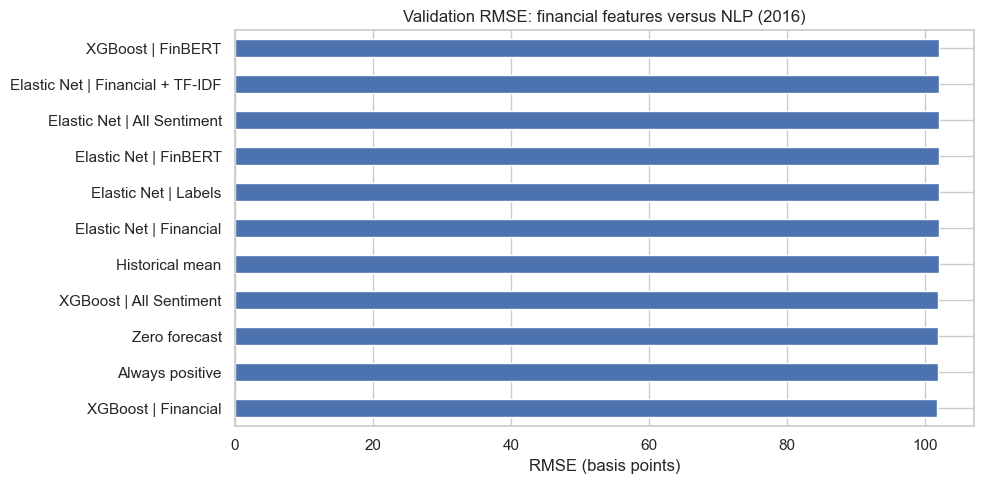

In [61]:
validation_table = pd.DataFrame({
    name: prediction_metrics(y_bps[val_mask], pred)
    for name, pred in validation_predictions.items()
}).T.sort_values("RMSE (bps)")

display(validation_table.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
validation_table["RMSE (bps)"].sort_values().plot.barh(ax=ax)
ax.set(title="Validation RMSE: financial features versus NLP (2016)",
       xlabel="RMSE (basis points)", ylabel="")
plt.tight_layout()
plt.show()

## 50. Refit the frozen models and evaluate the final test set

The hyperparameters chosen above are now frozen. We fit each model on **2011–2016** and predict returns during **2017–2018**, without using any future labels for training or parameter selection.

There is one subtle exception to this simplified design: the TF-IDF vocabulary is still the original training-period vocabulary (2011–2015). We deliberately keep it fixed instead of refitting it using 2016 texts, which maintains consistency with Phase 3 and avoids rebuilding the matrix.

**Important:** after viewing the test table, do not change variables, thresholds, preprocessing, or hyperparameters and rerun to chase a higher test score.

In [62]:
test_predictions = {
    "Zero forecast": np.zeros(test_mask.sum()),
    "Historical mean": np.full(test_mask.sum(), y_bps[train_val_mask].mean()),
    "Always positive": np.ones(test_mask.sum()),
}

# Refit Elastic Net using the parameters chosen from validation.
for name, (cols, use_text) in elastic_specs.items():
    X = prepare_features(cols, train_val_mask, use_tfidf=use_text)
    model = ElasticNet(**elastic_choices[name], max_iter=10000, random_state=42)
    model.fit(X[train_val_mask], y_bps[train_val_mask])
    test_predictions[name] = model.predict(X[test_mask])

# Refit XGBoost with the same frozen parameters.
for name, cols in xgb_specs.items():
    X = prepare_features(cols, train_val_mask)
    model = new_xgb(xgb_choices[name])
    model.fit(X[train_val_mask], y_bps[train_val_mask])
    test_predictions[name] = model.predict(X[test_mask])

# Evaluate each model on exactly the same dates.
test_table = pd.DataFrame({
    name: prediction_metrics(y_bps[test_mask], forecast)
    for name, forecast in test_predictions.items()
}).T.sort_values("RMSE (bps)")

print("FINAL OUT-OF-SAMPLE TEST: 2017–2018")
display(test_table.round(4))

FINAL OUT-OF-SAMPLE TEST: 2017–2018


,RMSE (bps),MAE (bps),OOS R2 vs zero,IC,Directional accuracy
Always positive,65.7402,49.6119,0.0007,NaN,0.5150
Zero forecast,65.7626,49.6403,0.0000,NaN,0.0040
Historical mean,65.8170,49.7026,-0.0017,NaN,0.4810
Elastic Net | Financial,65.8170,49.7026,-0.0017,NaN,0.4810
Elastic Net | Labels,65.8170,49.7026,-0.0017,NaN,0.4810
Elastic Net | FinBERT,65.8170,49.7026,-0.0017,NaN,0.4810
Elastic Net | All Sentiment,65.8170,49.7026,-0.0017,NaN,0.4810
Elastic Net | Financial + TF-IDF,65.8170,49.7026,-0.0017,NaN,0.4810
XGBoost | All Sentiment,66.2245,49.9602,-0.0141,-0.0071,0.4770
XGBoost | Financial,66.8183,50.5032,-0.0324,-0.0145,0.4691


## 51. Measure the incremental value of NLP

The central hypothesis is not whether a machine-learning model obtains a low error, but whether **adding news improves the same algorithm**. We calculate the relative RMSE change:

$$
\text{RMSE gain (\%)} = 100 \times \frac{\mathrm{RMSE}_{\text{financial}} - \mathrm{RMSE}_{\text{financial+NLP}}}{\mathrm{RMSE}_{\text{financial}}}.
$$

A **positive** value means the NLP-enhanced model reduced forecast error. A negative value means the financial-only model performed better.

,Financial baseline,NLP-enhanced model,RMSE gain (%),IC change
0,Elastic Net | Financial,Elastic Net | Labels,0.0000,NaN
1,Elastic Net | Financial,Elastic Net | FinBERT,0.0000,NaN
2,Elastic Net | Financial,Elastic Net | All Sentiment,0.0000,NaN
3,Elastic Net | Financial,Elastic Net | Financial + TF-IDF,0.0000,NaN
4,XGBoost | Financial,XGBoost | FinBERT,-0.2340,0.0160
5,XGBoost | Financial,XGBoost | All Sentiment,0.8886,0.0074


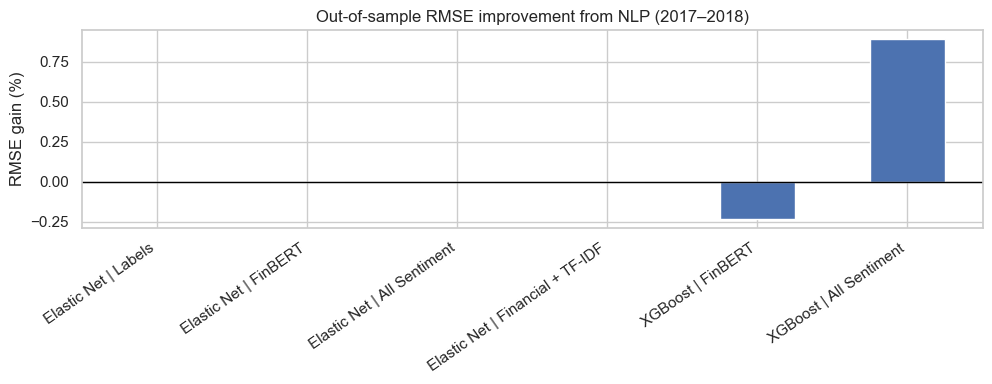

In [63]:
comparisons = [
    ("Elastic Net | Financial", "Elastic Net | Labels"),
    ("Elastic Net | Financial", "Elastic Net | FinBERT"),
    ("Elastic Net | Financial", "Elastic Net | All Sentiment"),
    ("Elastic Net | Financial", "Elastic Net | Financial + TF-IDF"),
    ("XGBoost | Financial", "XGBoost | FinBERT"),
    ("XGBoost | Financial", "XGBoost | All Sentiment"),
]

improvements = []
for base, enhanced in comparisons:
    base_rmse = test_table.loc[base, "RMSE (bps)"]
    enhanced_rmse = test_table.loc[enhanced, "RMSE (bps)"]
    improvements.append({
        "Financial baseline": base,
        "NLP-enhanced model": enhanced,
        "RMSE gain (%)": 100 * (base_rmse - enhanced_rmse) / base_rmse,
        "IC change": test_table.loc[enhanced, "IC"] - test_table.loc[base, "IC"],
    })

gain_table = pd.DataFrame(improvements)
display(gain_table.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
gain_table.plot.bar(x="NLP-enhanced model", y="RMSE gain (%)", ax=ax, legend=False)
ax.axhline(0, linewidth=1, color="black")
ax.set(title="Out-of-sample RMSE improvement from NLP (2017–2018)",
       ylabel="RMSE gain (%)", xlabel="")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 52. Visualize actual and predicted returns

Next-session gold returns are noisy. A forecast should **not** be expected to track every daily movement. This graph compares the financial Elastic Net forecast with its FinBERT-enhanced counterpart over the first 120 test sessions. We use the same time period and outcome for both models.

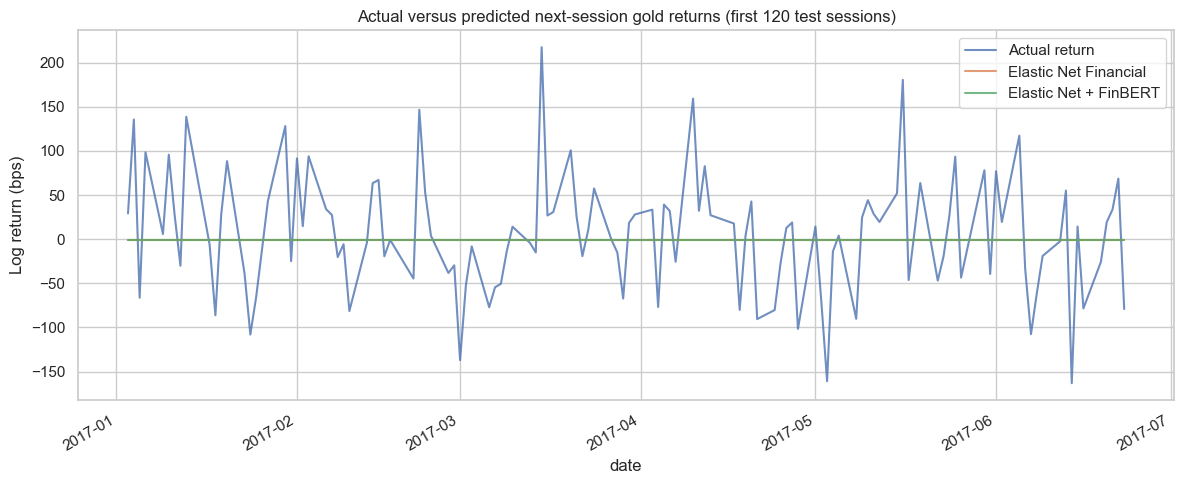

,Actual return,Elastic Net Financial,Elastic Net + FinBERT
date,,,
2017-01-03,29.257609,-1.350937,-1.350937
2017-01-04,135.695723,-1.350937,-1.350937
2017-01-05,-66.337434,-1.350937,-1.350937
2017-01-06,98.497659,-1.350937,-1.350937
2017-01-09,5.912499,-1.350937,-1.350937


In [64]:
test_dates = phase3_main.index[test_mask]
forecast_comparison = pd.DataFrame({
    "Actual return": y_bps[test_mask],
    "Elastic Net Financial": test_predictions["Elastic Net | Financial"],
    "Elastic Net + FinBERT": test_predictions["Elastic Net | FinBERT"],
}, index=test_dates)

forecast_comparison.iloc[:120].plot(figsize=(12, 5), alpha=0.8)
plt.title("Actual versus predicted next-session gold returns (first 120 test sessions)")
plt.ylabel("Log return (bps)")
plt.tight_layout()
plt.show()

display(forecast_comparison.head())

## 53. Preliminary evaluation by VIX regime (descriptive only)

Our project also asks whether text becomes more informative during periods of financial stress. Here we provide a **first descriptive check**, not the definitive stress-regime experiment.

We define high stress using the 80th percentile of the **already lagged VIX feature in the 2011–2015 training sample**. This threshold is fixed before inspecting 2017–2018. We then compare test RMSE within high- and lower-VIX sessions.

Because stress days may be rare, subgroup results can be unstable. Statistical inference and richer geopolitical analysis are postponed to a dedicated robustness phase.

Train-period VIX 80th-percentile threshold: 19.6


,Regime,Model,Sessions,RMSE (bps)
0,Lower VIX,Elastic Net | Financial,436,65.003
1,Lower VIX,Elastic Net | FinBERT,436,65.003
2,Lower VIX,XGBoost | Financial,436,65.933
3,Lower VIX,XGBoost | FinBERT,436,66.313
4,High VIX,Elastic Net | Financial,65,71.037
5,High VIX,Elastic Net | FinBERT,65,71.037
6,High VIX,XGBoost | Financial,65,72.475
7,High VIX,XGBoost | FinBERT,65,71.252


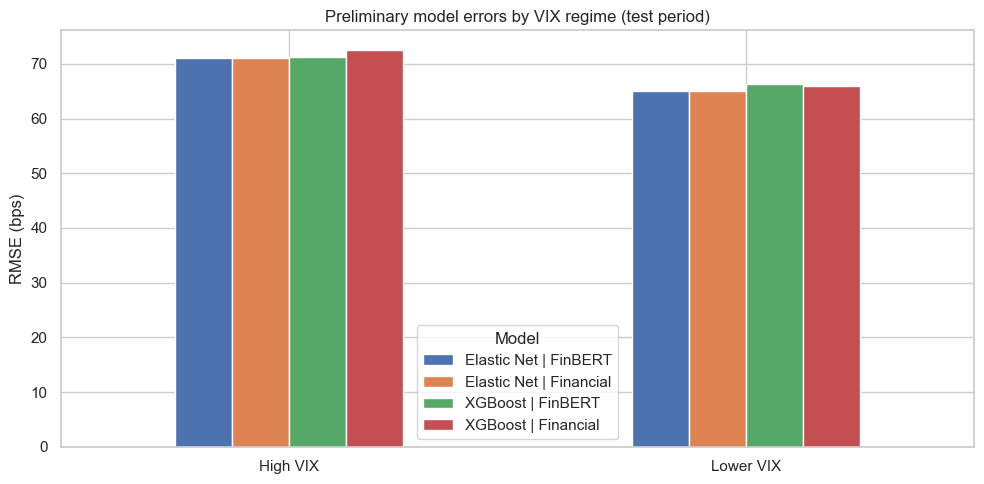

In [65]:
# A threshold determined on training data only.
vix_train = phase3_main.loc[train_mask, "lag1_vix"].dropna()
vix_threshold = vix_train.quantile(0.80)
regime_is_stress = (phase3_main.loc[test_mask, "lag1_vix"].to_numpy() > vix_threshold)

regime_rows = []
for regime_name, mask in [("Lower VIX", ~regime_is_stress),
                          ("High VIX", regime_is_stress)]:
    actual = y_bps[test_mask][mask]
    for model_name in ["Elastic Net | Financial", "Elastic Net | FinBERT",
                       "XGBoost | Financial", "XGBoost | FinBERT"]:
        forecast = test_predictions[model_name][mask]
        regime_rows.append({"Regime": regime_name, "Model": model_name,
                            "Sessions": len(actual),
                            "RMSE (bps)": np.sqrt(mean_squared_error(actual, forecast))
                            if len(actual) else np.nan})
regime_table = pd.DataFrame(regime_rows)
print("Train-period VIX 80th-percentile threshold:", round(vix_threshold, 2))
display(regime_table.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
regime_table.pivot(index="Regime", columns="Model", values="RMSE (bps)").plot.bar(ax=ax)
ax.set(title="Preliminary model errors by VIX regime (test period)",
       ylabel="RMSE (bps)", xlabel="")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 54. Save the out-of-sample forecasts and summary tables

We export the validation results, test results, hyperparameters, and **dated out-of-sample predictions**. Keeping every forecast makes the later backtest reproducible, and ensures that we use exactly the same return series and test dates.

In [66]:
# One row per test date; all forecasts are in bps.
test_forecasts_export = pd.DataFrame({
    "date": test_dates,
    "actual_log_return": y_bps[test_mask] / 10000.0,
    "lag1_vix": phase3_main.loc[test_mask, "lag1_vix"].to_numpy(),
})
for name, values in test_predictions.items():
    test_forecasts_export[name] = np.asarray(values) / 10000.0

test_forecasts_export.to_csv(DATA_DIR / "phase4_test_predictions.csv", index=False)
validation_table.to_csv(DATA_DIR / "phase4_validation_metrics.csv")
test_table.to_csv(DATA_DIR / "phase4_test_metrics.csv")
gain_table.to_csv(DATA_DIR / "phase4_nlp_rmse_gains.csv", index=False)
regime_table.to_csv(DATA_DIR / "phase4_preliminary_vix_regimes.csv", index=False)

# Save chosen settings in a readable table.
params_rows = []
for model_name, params in {**elastic_choices, **xgb_choices}.items():
    params_rows.append({"model": model_name, **params})
pd.DataFrame(params_rows).to_csv(DATA_DIR / "phase4_selected_parameters.csv", index=False)

assert len(test_forecasts_export) == test_mask.sum()
assert test_forecasts_export["date"].is_unique
assert np.isfinite(test_forecasts_export.select_dtypes(include=["number"])
                   .drop(columns=["lag1_vix"]).to_numpy()).all()
print("Saved all Phase 4 files in", DATA_DIR.resolve())

Saved all Phase 4 files in /Users/mac/projet_ml_trading/data


## 55. Phase 4 — Conclusions and Research Design Decisions

### 55.1 Experimental design

We investigated whether gold-related news sentiment improves the prediction of next-session gold returns relative to models using financial variables alone. The dataset contains **2,009 daily observations**, divided chronologically into **1,258 training observations (2011–2015)**, **250 validation observations (2016)**, and **501 out-of-sample test observations (2017–2018)**. We evaluated simple benchmarks, Elastic Net, and XGBoost, both with and without text-derived features. Numerical preprocessing was estimated using training observations, model hyperparameters were selected on the 2016 validation period, and the selected models were refitted on 2011–2016 before their final evaluation. All models were evaluated on the same test dates.

### 55.2 Baseline predictive performance

The **zero-return benchmark** obtained a test RMSE of **65.7626 basis points (bps)**. The *always-positive* benchmark achieved **65.7402 bps**, a marginal improvement, whereas the historical-mean benchmark obtained **65.8170 bps**. The financial-only Elastic Net produced the same RMSE as the historical mean (**65.8170 bps**) and a negative out-of-sample R² relative to the zero forecast (**−0.0017**). The financial-only XGBoost obtained **65.9543 bps** (out-of-sample R² **−0.0058**), with a directional accuracy of **50.1%** and an information coefficient of approximately **0.017**. Therefore, neither financial ML approach outperformed the simplest benchmarks by RMSE on the final test period.

### 55.3 Incremental predictive value of NLP

The validation procedure selected **alpha = 10.0** and **l1_ratio = 0.8** for every Elastic Net specification, including the expanded regularization grid. These choices led to predictions identical to the historical-mean benchmark, irrespective of whether manual sentiment labels, FinBERT, or TF-IDF features were added. Consequently, the observed RMSE gain from NLP in these Elastic Net comparisons was **0.0000%**. This should **not** be interpreted as evidence that all sentiment variables are intrinsically uninformative; rather, the validation-selected regularization favored a constant forecast under the current setup.

For XGBoost, adding FinBERT increased test RMSE from **65.9543** to **66.0641 bps**, corresponding to an RMSE gain of **−0.1664%**. Adding all sentiment indicators produced an RMSE of **65.9867 bps**, a gain of **−0.0492%** relative to financial-only XGBoost. The corresponding information coefficients were also slightly lower than that of financial-only XGBoost. Overall, **we find no positive incremental out-of-sample predictive contribution from the tested NLP representations at the daily horizon**. These comparisons are descriptive and do not, on their own, establish statistical significance.

### 55.4 Preliminary evidence across market-stress regimes

Using the **80th percentile of training-period lagged VIX (19.6)** as a predetermined threshold, the test sample contains **436 lower-VIX sessions** and **65 high-VIX sessions**. For Elastic Net, the financial and FinBERT-enhanced models had identical RMSE in both regimes: **65.003 bps** in the lower-VIX group and **71.037 bps** in the high-VIX group. For XGBoost, the financial-only model obtained **65.280 bps** in lower-VIX sessions and **70.307 bps** in high-VIX sessions; the FinBERT-enhanced model obtained **65.382** and **70.468 bps**, respectively. Hence, the tested FinBERT augmentation did not improve RMSE in either regime. The comparatively small high-VIX subsample limits the strength of any conclusion about market stress.

### 55.5 Interpretation, limitations, and next steps

These negative results are scientifically informative. They suggest that, under our current data, timing conventions, feature definitions, and validation protocol, **news sentiment does not demonstrably improve next-session gold-return prediction**. Several factors may explain this finding: low signal-to-noise ratios in daily asset returns; predominantly retrospective news labels; unavailable intraday publication times; conservative delays before news enters the feature set; and the distinction between general financial sentiment and the direction of gold prices. We also caution that the historical GPR series may be revised and is not, without additional point-in-time checks, equivalent to a real-time trading signal.

A further methodological limitation is that **the 2017–2018 test results have now been inspected repeatedly**. Any new feature, horizon, or model specification inspired by these results should be presented as *exploratory*, rather than as an untouched confirmatory out-of-sample test. The strong regularization selected for Elastic Net should also be reported transparently instead of changing parameters simply to force nonzero coefficients.

In the next phase, we will test the stability of these findings across predefined stress regimes and reasonable robustness checks, then evaluate whether the available forecasts have any economic value in a trading backtest accounting for turnover and transaction costs. Positive trading results, if any, will need to be interpreted in light of the weak predictive evidence and the repeated use of the same historical test period.


### Phase 4 references

- Champonnois, S. (2026), *Machine-learning for Portfolio Management and Trading*: Chapters 4–7 (backtesting, linear models, nonlinear models, hyperparameter selection), Chapters 20 and 23–24 (out-of-sample prediction and textual information).
- [scikit-learn: ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html)
- [XGBoost Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html)

**Reproducibility note:** training and validation are used for model fitting and selection, whereas the final test window must not be used to revise model design.

---
# Phase 5 — Robustness, Market Stress and Trading Backtests

**Research question.** Do the out-of-sample gold-return forecasts from Phase 4 contain economically useful information, and is the incremental contribution of NLP different during high-VIX periods?

This phase reuses **exactly the predictions produced in Phase 4**. We do not fit another model or select a new hyperparameter using the 2017–2018 test set.

Our analysis has four parts:

1. Measure the stability of prediction errors by year and market regime.
2. Quantify the uncertainty around the difference between a financial model and its NLP-enhanced counterpart.
3. Convert forecasts into simple, pre-specified trading positions, including transaction costs.
4. Test whether any result survives reasonable cost assumptions and discuss the main limitations.

**Important limitation.** The 2017–2018 test period has already been inspected during model development in Phase 4. Therefore, all additional tests in Phase 5 are **exploratory**, rather than a new untouched out-of-sample confirmation. Their purpose is to understand the previous results, not to select a profitable strategy after seeing the data.

## 56. Reuse the completed Phase 4 results

We start from the original forecast series and daily gold prices. Every forecast on date $t$ corresponds to the **next gold trading session**, from close $t$ to close $t+1$. No forecast is re-estimated in this phase.

**Timing convention.** Phase 2 already delayed financial and news inputs by one gold session. At the close of session $t$, a forecast indexed by $t$ can therefore be interpreted as a signal for the return from $t$ to the next close. Our backtest assumes, as a simplified convention, that the position can be established at that close. Actual execution and close-price availability would require more precise timestamps and intraday prices.

In [67]:
# Keep the final test dates and forecasts from Phase 4.
phase5 = pd.DataFrame(index=phase3_main.index[test_mask].copy())
phase5.index.name = "date"

phase5["actual_log_return"] = np.asarray(y_bps[test_mask]) / 10000.0
phase5["actual_simple_return"] = np.expm1(phase5["actual_log_return"])
phase5["lag1_vix"] = phase3_main.loc[test_mask, "lag1_vix"].to_numpy()

for name, predictions in test_predictions.items():
    phase5[name] = np.asarray(predictions, dtype=float) / 10000.0

assert phase5.index.is_monotonic_increasing and phase5.index.is_unique
assert phase5["actual_simple_return"].notna().all()
assert np.isfinite(phase5.filter(regex="Elastic Net|XGBoost").to_numpy()).all()
assert len(phase5) == test_mask.sum()

print("Number of test sessions:", len(phase5))
print("Evaluation period:", phase5.index.min().date(), "to", phase5.index.max().date())
print("Available forecast models:", len(test_predictions))
display(phase5.head())

Number of test sessions: 501
Evaluation period: 2017-01-03 to 2018-12-31
Available forecast models: 11


,actual_log_return,actual_simple_return,lag1_vix,Zero forecast,Historical mean,Always positive,Elastic Net | Financial,Elastic Net | Labels,Elastic Net | FinBERT,Elastic Net | All Sentiment,Elastic Net | Financial + TF-IDF,XGBoost | Financial,XGBoost | FinBERT,XGBoost | All Sentiment
date,,,,,,,,,,,,,,
2017-01-03,0.002926,0.002930,14.04,0.0,-0.000135,0.0001,-0.000135,-0.000135,-0.000135,-0.000135,-0.000135,-0.000557,0.000236,-0.000126
2017-01-04,0.013570,0.013662,12.85,0.0,-0.000135,0.0001,-0.000135,-0.000135,-0.000135,-0.000135,-0.000135,0.000654,0.001487,0.000978
2017-01-05,-0.006634,-0.006612,11.85,0.0,-0.000135,0.0001,-0.000135,-0.000135,-0.000135,-0.000135,-0.000135,0.001099,0.001480,0.000807
2017-01-06,0.009850,0.009898,11.67,0.0,-0.000135,0.0001,-0.000135,-0.000135,-0.000135,-0.000135,-0.000135,0.000945,0.000641,0.000678
2017-01-09,0.000591,0.000591,11.32,0.0,-0.000135,0.0001,-0.000135,-0.000135,-0.000135,-0.000135,-0.000135,0.000201,-0.000323,0.000052


## 57. Robustness: compare forecast errors separately in 2017 and 2018

A model may appear useful over a two-year period even if its performance is driven by only one year. We therefore compare each model with the zero-return forecast separately for 2017 and 2018.

We use the same prediction metric as in Phase 4:

$$RMSE=\sqrt{\frac{1}{n}\sum_t (r_{t+1}-\hat r_{t+1})^2}.$$

**Interpretation.** A smaller RMSE is better. Differences based on one calendar year should not be overinterpreted: one year provides a limited amount of data.

year,2017,2018
model,,
Elastic Net | FinBERT,65.478,66.156
Elastic Net | Financial,65.478,66.156
XGBoost | All Sentiment,66.106,66.343
XGBoost | FinBERT,67.088,66.861
XGBoost | Financial,66.594,67.043
Zero forecast,65.362,66.163


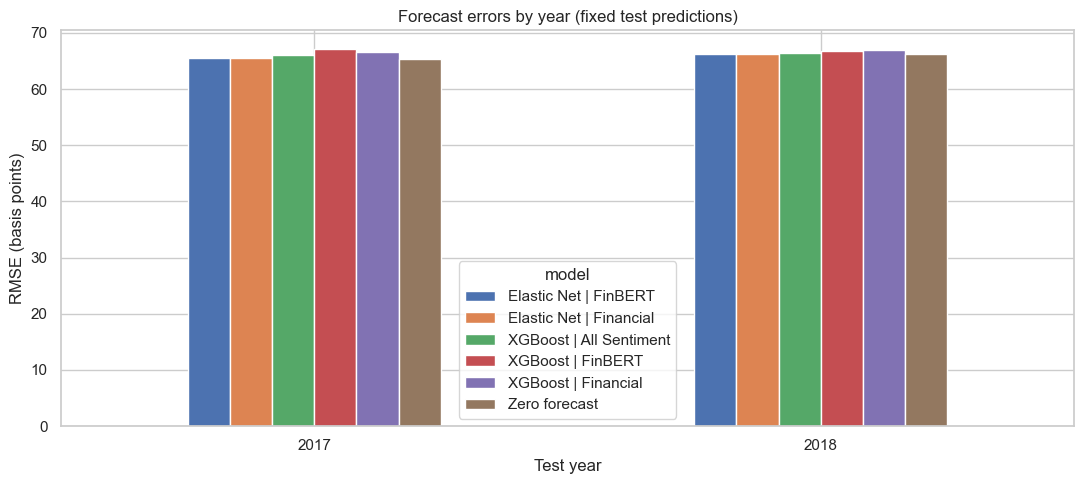

In [68]:
# Returns and forecasts in basis points for readable forecast errors.
models_to_compare = [
    "Zero forecast",
    "Elastic Net | Financial",
    "Elastic Net | FinBERT",
    "XGBoost | Financial",
    "XGBoost | FinBERT",
    "XGBoost | All Sentiment",
]

annual_errors = []
for year, sample in phase5.groupby(phase5.index.year):
    for model_name in models_to_compare:
        actual_bps = sample["actual_log_return"].to_numpy() * 10000
        forecast_bps = sample[model_name].to_numpy() * 10000
        annual_errors.append({
            "year": year,
            "model": model_name,
            "sessions": len(sample),
            "RMSE (bps)": np.sqrt(np.mean((actual_bps - forecast_bps)**2)),
            "MAE (bps)": np.mean(np.abs(actual_bps - forecast_bps)),
        })

annual_error_table = pd.DataFrame(annual_errors)
display(annual_error_table.pivot(index="model", columns="year", values="RMSE (bps)").round(3))

ax = annual_error_table.pivot(index="year", columns="model", values="RMSE (bps)").plot(
    kind="bar", figsize=(11, 5), rot=0
)
ax.set(title="Forecast errors by year (fixed test predictions)",
       xlabel="Test year", ylabel="RMSE (basis points)")
plt.tight_layout()
plt.show()

## 58. Financial-stress regimes: does NLP help when the VIX is high?

We define stress using the **80th percentile of the training-period VIX**, calculated in Phase 4. This is a fixed threshold, not one chosen to make the test look better.

$$Stress_t=\mathbf{1}\{VIX_{t-1}>q_{0.8}^{train}\}.$$

We compare the *same two models* within each regime. The key quantity is the relative reduction in RMSE from adding FinBERT. We also report the sample size, because high-stress days may be scarce. This is a descriptive, not causal, comparison.

Training-derived VIX stress threshold: 19.6


,regime,pair,sessions,baseline_rmse_bps,nlp_rmse_bps,nlp_gain_pct
0,Lower VIX,Elastic Net | FinBERT,436,65.003,65.003,0.000
1,Lower VIX,XGBoost | FinBERT,436,65.933,66.313,-0.576
2,Lower VIX,XGBoost | All Sentiment,436,65.933,65.501,0.656
3,High VIX,Elastic Net | FinBERT,65,71.037,71.037,0.000
4,High VIX,XGBoost | FinBERT,65,72.475,71.252,1.689
5,High VIX,XGBoost | All Sentiment,65,72.475,70.890,2.188


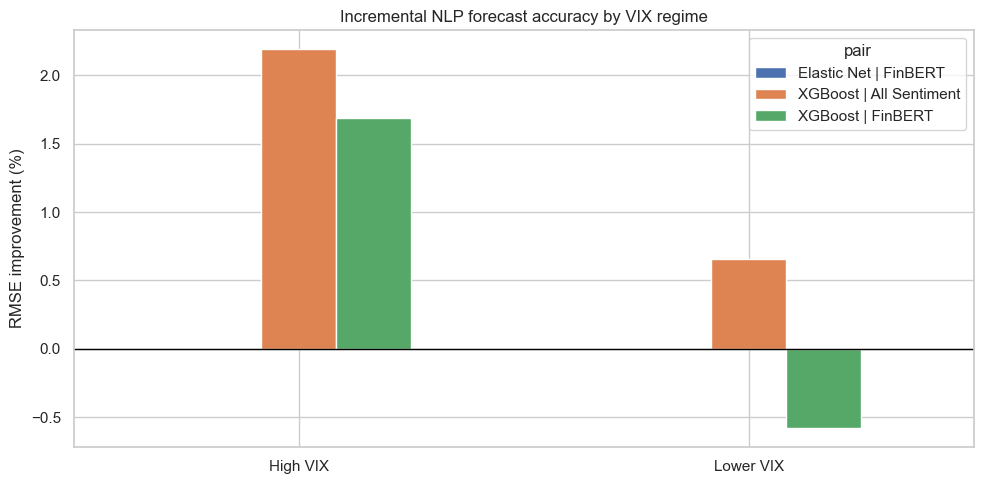

In [69]:
# Reuse the training-only VIX threshold defined in Phase 4.
assert np.isfinite(vix_threshold)
phase5["high_vix"] = phase5["lag1_vix"] > vix_threshold

pairs = [
    ("Elastic Net | Financial", "Elastic Net | FinBERT"),
    ("XGBoost | Financial", "XGBoost | FinBERT"),
    ("XGBoost | Financial", "XGBoost | All Sentiment"),
]

stress_rows = []
for is_stress, part in phase5.groupby("high_vix"):
    actual = part["actual_log_return"].to_numpy()
    for baseline, enhanced in pairs:
        rmse_base = np.sqrt(np.mean((actual - part[baseline].to_numpy())**2))
        rmse_nlp = np.sqrt(np.mean((actual - part[enhanced].to_numpy())**2))
        stress_rows.append({
            "regime": "High VIX" if is_stress else "Lower VIX",
            "pair": enhanced,
            "sessions": len(part),
            "baseline_rmse_bps": rmse_base * 10000,
            "nlp_rmse_bps": rmse_nlp * 10000,
            "nlp_gain_pct": 100 * (rmse_base - rmse_nlp) / rmse_base,
        })

stress_gain_table = pd.DataFrame(stress_rows)
print("Training-derived VIX stress threshold:", round(vix_threshold, 2))
display(stress_gain_table.round(3))

ax = stress_gain_table.pivot(index="regime", columns="pair", values="nlp_gain_pct").plot(
    kind="bar", figsize=(10, 5), rot=0
)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Incremental NLP forecast accuracy by VIX regime",
       ylabel="RMSE improvement (%)", xlabel="")
plt.tight_layout()
plt.show()

## 59. Paired loss differences and a block-bootstrap interval

A small improvement in average RMSE can be due to chance. We therefore compare **paired squared errors** from the two models on the same dates:

$$d_t=(r_{t+1}-\hat r_{t+1}^{financial})^2-(r_{t+1}-\hat r_{t+1}^{NLP})^2.$$

A positive average $d_t$ favors the NLP-enhanced model. To illustrate sampling uncertainty while partially preserving serial dependence, we use a simple moving-block bootstrap with a **fixed block length of five sessions** and a fixed random seed. This is an exploratory confidence interval, not a formal proof of predictability; the small and already-inspected test set limits its evidential strength.

In [70]:
def moving_block_mean_interval(values, block_size=5, n_boot=1000, seed=42):
    """Bootstrap the sample mean, resampling consecutive observations in blocks."""
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n < block_size:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    possible_starts = np.arange(n - block_size + 1)
    bootstrap_means = []
    for _ in range(n_boot):
        starts = rng.choice(possible_starts, size=int(np.ceil(n / block_size)), replace=True)
        indices = np.concatenate([np.arange(s, s + block_size) for s in starts])[:n]
        bootstrap_means.append(values[indices].mean())
    return tuple(np.percentile(bootstrap_means, [2.5, 97.5]))

loss_rows = []
actual_bps = phase5["actual_log_return"].to_numpy() * 10000
for baseline, enhanced in pairs:
    base_error = actual_bps - phase5[baseline].to_numpy() * 10000
    nlp_error = actual_bps - phase5[enhanced].to_numpy() * 10000
    loss_diff = base_error**2 - nlp_error**2
    low, high = moving_block_mean_interval(loss_diff)
    loss_rows.append({
        "NLP model": enhanced,
        "mean_squared_loss_gain_bps2": loss_diff.mean(),
        "bootstrap_low_bps2": low,
        "bootstrap_high_bps2": high,
    })

loss_interval_table = pd.DataFrame(loss_rows)
display(loss_interval_table.round(3))
print("Positive mean loss gain = lower squared forecasting error with NLP.")

,NLP model,mean_squared_loss_gain_bps2,bootstrap_low_bps2,bootstrap_high_bps2
0,Elastic Net | FinBERT,0.000,0.000,0.000
1,XGBoost | FinBERT,-20.918,-102.512,58.739
2,XGBoost | All Sentiment,78.997,-0.932,158.978


Positive mean loss gain = lower squared forecasting error with NLP.


## 60. From predictions to trading positions

We use one simple, **pre-specified** directional rule for all models:

$$w_t=\begin{cases}+1 & \hat r_{t+1}>0\\-1 & \hat r_{t+1}<0\\0 & \hat r_{t+1}=0.\end{cases}$$

Here, $w_t$ denotes the position opened (or adjusted) at the end of session $t$, to be held over the following session. A position of $+1$ is long one unit of notional, $-1$ is short one unit and $0$ is flat.

This simple sign rule is intentionally *not optimized on the test set*. It is a hypothetical futures-style notional return strategy. It does not model contract sizing, financing, initial margin, slippage at the close, or rolling from one futures maturity to another.

We include a permanently long benchmark (buy-and-hold gold) and an always-flat benchmark. A constant forecast can mechanically produce a permanently long or short position; this must not be confused with successful timing.

In [71]:
# Include matched financial/NLP pairs and two transparent benchmarks.
trade_forecasts = [
    "Elastic Net | Financial",
    "Elastic Net | FinBERT",
    "XGBoost | Financial",
    "XGBoost | FinBERT",
    "XGBoost | All Sentiment",
]

positions = pd.DataFrame(index=phase5.index)
positions["Buy & hold gold"] = 1.0
positions["Stay in cash"] = 0.0

for model_name in trade_forecasts:
    positions[model_name] = np.sign(phase5[model_name].to_numpy())

# Always begin from a flat position before the first test date.
# A reversal from +1 to -1 counts as two one-way units of trading.
turnover = positions.diff().abs()
turnover.iloc[0] = positions.iloc[0].abs()

print("Average absolute position")
display(positions.abs().mean().round(3).to_frame("average_abs_exposure"))
print("Total one-way notional turnover")
display(turnover.sum().round(1).to_frame("total_turnover"))

assert positions.isin([-1.0, 0.0, 1.0]).all().all()
assert (turnover >= 0).all().all()

Average absolute position


,average_abs_exposure
Buy & hold gold,1.0
Stay in cash,0.0
Elastic Net | Financial,1.0
Elastic Net | FinBERT,1.0
XGBoost | Financial,1.0
XGBoost | FinBERT,1.0
XGBoost | All Sentiment,1.0


Total one-way notional turnover


,total_turnover
Buy & hold gold,1.0
Stay in cash,0.0
Elastic Net | Financial,1.0
Elastic Net | FinBERT,1.0
XGBoost | Financial,385.0
XGBoost | FinBERT,305.0
XGBoost | All Sentiment,355.0


## 61. Net PnL and transaction costs

For a simple asset return $R_{t\to t+1}$ and the position $w_t$ established at the end of day $t$, the notional strategy return is

$$R^{net}_{strategy,t\to t+1}=w_t R_{t\to t+1}-c\,|w_t-w_{t-1}|.$$

The constant $c$ is a **one-way cost per unit of notional turnover**. We start with $c=5$ basis points ($0.0005$) and later repeat the analysis with other costs. A long-to-short reversal has turnover 2, hence twice the one-way cost. We charge entry costs on the first test day, but do not charge a final liquidation cost: this is stated explicitly.

These calculations use **simple returns**, not log returns, because they combine positions and PnL on a common notional basis. In the underlying data, the target is a close-to-close return; this simulation assumes a fill at that close and does not prove the strategy is executable at that price.

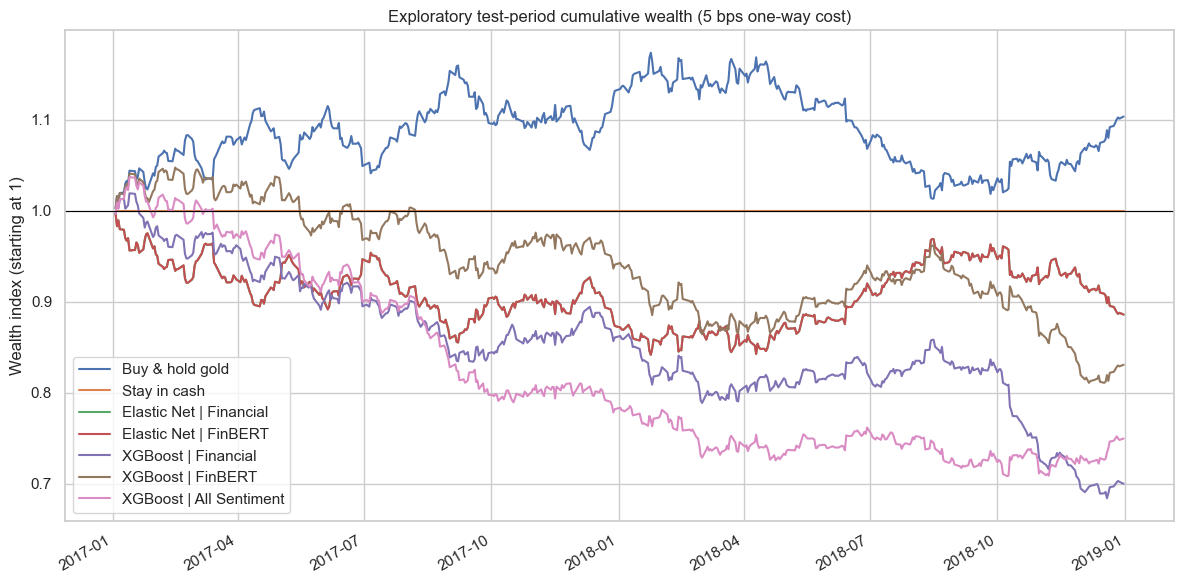

In [72]:
# One-way transaction cost per traded unit (5 basis points).
BASE_COST_BPS = 5.0
base_cost = BASE_COST_BPS / 10000.0

asset_returns = phase5["actual_simple_return"]
strategy_gross = positions.mul(asset_returns, axis=0)
strategy_net = strategy_gross - base_cost * turnover

# Compound daily strategy returns into a wealth curve, starting with 1 unit.
wealth = (1 + strategy_net).cumprod()

ax = wealth.plot(figsize=(12, 6))
ax.axhline(1, color="black", linewidth=0.8)
ax.set(title="Exploratory test-period cumulative wealth (5 bps one-way cost)",
       ylabel="Wealth index (starting at 1)", xlabel="")
plt.tight_layout()
plt.show()

assert np.isfinite(strategy_net.to_numpy()).all()
assert (strategy_net > -1).all().all(), "Wealth compounding requires returns above -100%."

## 62. Evaluate economic performance and risk

We report:

- **Annualized geometric return**: compound performance under a 252-session annualization convention.
- **Annualized volatility** and **Sharpe ratio**: computed from the daily strategy-return series; the Sharpe below assumes a zero daily risk-free return for simplicity.
- **Maximum drawdown**: largest peak-to-trough wealth decline.
- **Turnover**: average one-way units traded per session, which helps quantify implementation costs.

The aim is to compare models *at the same notional exposure bounds*, not to claim that one strategy would dominate after more realistic execution frictions.

,Annualized return (%),Annualized volatility (%),Sharpe (rf=0),Maximum drawdown (%),Average daily turnover,Total turnover
Buy & hold gold,5.073,10.449,0.526,-13.667,0.002,1.0
Elastic Net | Financial,-5.908,10.451,-0.530,-15.823,0.002,1.0
Elastic Net | FinBERT,-5.908,10.451,-0.530,-15.823,0.002,1.0
XGBoost | FinBERT,-8.903,10.529,-0.833,-22.572,0.609,305.0
XGBoost | All Sentiment,-13.481,10.511,-1.325,-31.662,0.709,355.0
XGBoost | Financial,-16.416,10.519,-1.652,-32.860,0.768,385.0
Stay in cash,0.000,0.000,NaN,0.000,0.000,0.0


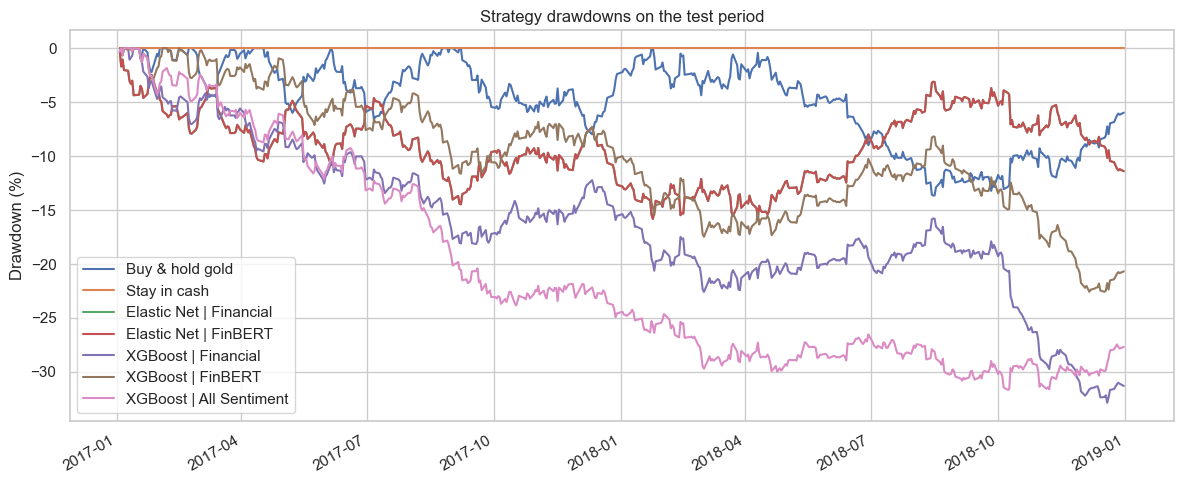

In [73]:
def strategy_statistics(daily_net_returns, daily_turnover):
    """Simple performance measures for one daily strategy return series."""
    returns = np.asarray(daily_net_returns, dtype=float)
    trades = np.asarray(daily_turnover, dtype=float)
    n = len(returns)
    wealth_path = np.cumprod(1.0 + returns)
    running_peak = np.maximum.accumulate(np.r_[1.0, wealth_path])[1:]
    drawdowns = wealth_path / running_peak - 1.0
    daily_std = returns.std(ddof=1)
    ann_return = wealth_path[-1]**(252 / n) - 1.0
    ann_volatility = daily_std * np.sqrt(252)
    sharpe = returns.mean() / daily_std * np.sqrt(252) if daily_std > 0 else np.nan
    return {
        "Annualized return (%)": 100 * ann_return,
        "Annualized volatility (%)": 100 * ann_volatility,
        "Sharpe (rf=0)": sharpe,
        "Maximum drawdown (%)": 100 * drawdowns.min(),
        "Average daily turnover": trades.mean(),
        "Total turnover": trades.sum(),
    }

performance_table = pd.DataFrame({
    name: strategy_statistics(strategy_net[name], turnover[name])
    for name in strategy_net.columns
}).T

display(performance_table.round(3).sort_values("Sharpe (rf=0)", ascending=False))

# Plot the net wealth drawdown from the previous peak, including initial wealth = 1.
drawdown = wealth.div(wealth.cummax().clip(lower=1), axis=0) - 1
ax = (drawdown * 100).plot(figsize=(12, 5))
ax.set(title="Strategy drawdowns on the test period", ylabel="Drawdown (%)", xlabel="")
plt.tight_layout()
plt.show()

## 63. Cost sensitivity: do conclusions survive less optimistic assumptions?

Transaction costs may eliminate a small signal. Instead of choosing the cost assumption that produces the best Sharpe, we report every strategy under the same **pre-specified cost scenarios**: 0, 2, 5 and 10 basis points per unit of turnover.

This is a *sensitivity analysis*, not a calibrated futures execution model. It excludes financing and roll costs.

Cost (bps),0,2,5,10
Strategy,,,,
Buy & hold gold,0.528,0.527,0.526,0.523
Elastic Net | FinBERT,-0.528,-0.529,-0.530,-0.533
Elastic Net | Financial,-0.528,-0.529,-0.530,-0.533
Stay in cash,NaN,NaN,NaN,NaN
XGBoost | All Sentiment,-0.478,-0.818,-1.325,-2.151
XGBoost | FinBERT,-0.105,-0.398,-0.833,-1.543
XGBoost | Financial,-0.736,-1.105,-1.652,-2.541


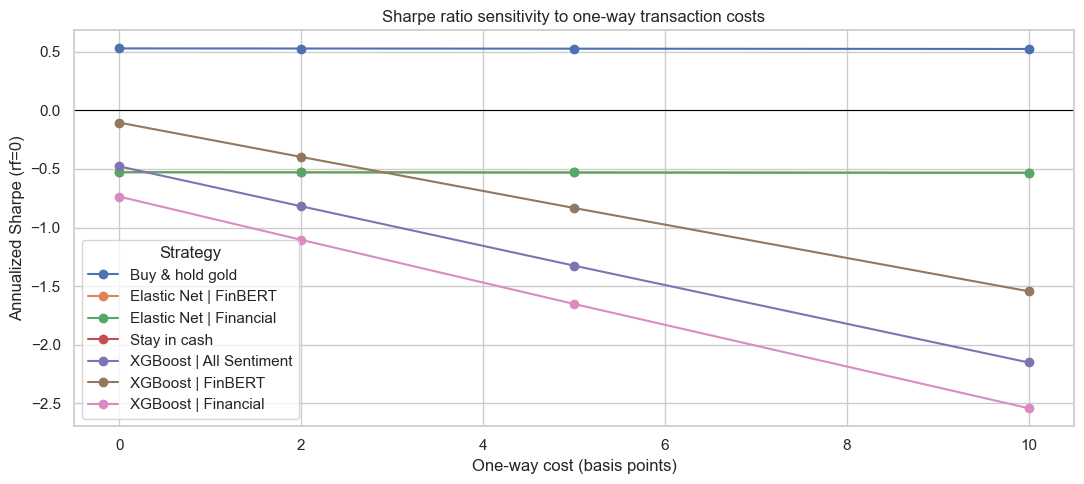

In [74]:
COST_SCENARIOS_BPS = [0, 2, 5, 10]
cost_rows = []

for cost_bps in COST_SCENARIOS_BPS:
    net_at_cost = strategy_gross - (cost_bps / 10000.0) * turnover
    for name in net_at_cost.columns:
        stats = strategy_statistics(net_at_cost[name], turnover[name])
        cost_rows.append({
            "Cost (bps)": cost_bps,
            "Strategy": name,
            "Annualized return (%)": stats["Annualized return (%)"],
            "Sharpe": stats["Sharpe (rf=0)"],
            "Maximum drawdown (%)": stats["Maximum drawdown (%)"],
        })

cost_table = pd.DataFrame(cost_rows)
display(cost_table.pivot(index="Strategy", columns="Cost (bps)", values="Sharpe").round(3))

ax = cost_table.pivot(index="Cost (bps)", columns="Strategy", values="Sharpe").plot(
    marker="o", figsize=(11, 5)
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Sharpe ratio sensitivity to one-way transaction costs",
       ylabel="Annualized Sharpe (rf=0)", xlabel="One-way cost (basis points)")
plt.tight_layout()
plt.show()

## 64. Inspect exposure and strategy performance across regimes

A trading system can look better simply because it tends to be permanently long or short. We examine **long/short exposure**, turnover, and the average daily net returns in high- and lower-VIX periods. This analysis is **descriptive**, since the sample contains relatively few stress sessions, and VIX is not a complete measure of geopolitical stress.

If NLP performs differently during stress, we will report both the size and the direction of the difference without inferring causation.

In [75]:
exposure_table = pd.DataFrame({
    "Long days (%)": (positions > 0).mean() * 100,
    "Short days (%)": (positions < 0).mean() * 100,
    "Flat days (%)": (positions == 0).mean() * 100,
    "Position changes": (turnover > 0).sum(),
})
display(exposure_table.round(2))

regime_pnl_rows = []
for label, mask in [("Lower VIX", ~phase5["high_vix"]),
                    ("High VIX", phase5["high_vix"])]:
    for strategy in strategy_net.columns:
        regime_pnl_rows.append({
            "Regime": label,
            "Strategy": strategy,
            "Sessions": int(mask.sum()),
            "Mean daily net return (bps)": 10000 * strategy_net.loc[mask, strategy].mean(),
            "Daily net volatility (bps)": 10000 * strategy_net.loc[mask, strategy].std(),
        })

regime_pnl_table = pd.DataFrame(regime_pnl_rows)
display(regime_pnl_table.round(3))

,Long days (%),Short days (%),Flat days (%),Position changes
Buy & hold gold,100.00,0.00,0.0,1
Stay in cash,0.00,0.00,100.0,0
Elastic Net | Financial,0.00,100.00,0.0,1
Elastic Net | FinBERT,0.00,100.00,0.0,1
XGBoost | Financial,40.32,59.68,0.0,193
XGBoost | FinBERT,42.71,57.29,0.0,153
XGBoost | All Sentiment,50.30,49.70,0.0,178


,Regime,Strategy,Sessions,Mean daily net return (bps),Daily net volatility (bps)
0,Lower VIX,Buy & hold gold,436,0.761,65.051
1,Lower VIX,Stay in cash,436,0.000,0.000
2,Lower VIX,Elastic Net | Financial,436,-0.784,65.061
3,Lower VIX,Elastic Net | FinBERT,436,-0.784,65.061
4,Lower VIX,XGBoost | Financial,436,-6.159,65.330
5,Lower VIX,XGBoost | FinBERT,436,-2.247,65.429
6,Lower VIX,XGBoost | All Sentiment,436,-5.780,65.417
7,High VIX,Buy & hold gold,65,11.695,70.595
8,High VIX,Stay in cash,65,0.000,0.000
9,High VIX,Elastic Net | Financial,65,-11.695,70.595


## 65. Summarize the value added by NLP without selecting a winner

To isolate the possible effect of text, we compare **matched financial-only and NLP-enhanced** strategies. Both use the same dates, the same trading rule and the same transaction-cost assumption.

We report the difference in Sharpe, annualized net return, and total turnover. These differences are **descriptive**, because no fresh holdout sample remains after model development.

In [76]:
trading_pairs = [
    ("Elastic Net | Financial", "Elastic Net | FinBERT"),
    ("XGBoost | Financial", "XGBoost | FinBERT"),
    ("XGBoost | Financial", "XGBoost | All Sentiment"),
]

incremental_rows = []
for baseline, enhanced in trading_pairs:
    incremental_rows.append({
        "Financial baseline": baseline,
        "NLP-enhanced strategy": enhanced,
        "Delta Sharpe": (performance_table.loc[enhanced, "Sharpe (rf=0)"]
                         - performance_table.loc[baseline, "Sharpe (rf=0)"]),
        "Delta annualized return (pp)": (
            performance_table.loc[enhanced, "Annualized return (%)"]
            - performance_table.loc[baseline, "Annualized return (%)"]
        ),
        "Delta total turnover": (performance_table.loc[enhanced, "Total turnover"]
                                 - performance_table.loc[baseline, "Total turnover"]),
    })

incremental_trading_table = pd.DataFrame(incremental_rows)
display(incremental_trading_table.round(4))

,Financial baseline,NLP-enhanced strategy,Delta Sharpe,Delta annualized return (pp),Delta total turnover
0,Elastic Net | Financial,Elastic Net | FinBERT,0.0000,0.0000,0.0
1,XGBoost | Financial,XGBoost | FinBERT,0.8187,7.5127,-80.0
2,XGBoost | Financial,XGBoost | All Sentiment,0.3268,2.9353,-30.0


## 66. Save results and verify important accounting identities

We save all outputs in the existing `data/` folder. The final checks verify that the PnL corresponds to **same-row forecast signals and next-session returns**, that costs are proportional to turnover, and that the zero-position strategy does not generate returns.

These mechanical checks do **not** establish that the assumed closing-price execution or the continuous-futures construction is realistic. Those limitations must be discussed in the final report.

In [77]:
# Mechanical checks of PnL accounting.
assert np.allclose(strategy_gross.to_numpy(),
                   positions.to_numpy() * phase5["actual_simple_return"].to_numpy()[:, None])
assert np.allclose(strategy_net.to_numpy(),
                   strategy_gross.to_numpy() - base_cost * turnover.to_numpy())
assert np.allclose(strategy_net["Stay in cash"], 0.0)
assert (turnover.iloc[0] == positions.iloc[0].abs()).all()

# Export data, metrics and daily strategy paths.
annual_error_table.to_csv(DATA_DIR / "phase5_annual_forecast_errors.csv", index=False)
stress_gain_table.to_csv(DATA_DIR / "phase5_stress_forecast_gains.csv", index=False)
loss_interval_table.to_csv(DATA_DIR / "phase5_loss_bootstrap.csv", index=False)
performance_table.to_csv(DATA_DIR / "phase5_trading_performance.csv")
cost_table.to_csv(DATA_DIR / "phase5_cost_sensitivity.csv", index=False)
exposure_table.to_csv(DATA_DIR / "phase5_exposures.csv")
regime_pnl_table.to_csv(DATA_DIR / "phase5_regime_pnl.csv", index=False)
incremental_trading_table.to_csv(DATA_DIR / "phase5_incremental_nlp_trading.csv", index=False)
phase5.to_csv(DATA_DIR / "phase5_test_data_and_forecasts.csv")
strategy_net.to_csv(DATA_DIR / "phase5_daily_net_returns.csv")
wealth.to_csv(DATA_DIR / "phase5_cumulative_wealth.csv")

print("All Phase 5 output files saved in:", DATA_DIR.resolve())
print("All mechanical accounting checks passed.")

All Phase 5 output files saved in: /Users/mac/projet_ml_trading/data
All mechanical accounting checks passed.


## 67. Phase 5 — Conclusions and Research Design Decisions

### 67.1 Forecast robustness across years

The out-of-sample analysis covers **501 trading sessions from January 2017 to December 2018**. Forecast accuracy is evaluated separately by year to assess whether the results depend on a particular subperiod.

The zero-return benchmark achieves an RMSE of **65.362 basis points in 2017** and **66.163 basis points in 2018**. The Elastic Net financial and FinBERT models produce identical errors of **65.478 bps in 2017** and **66.156 bps in 2018**. Thus, FinBERT does not add predictive information to the selected Elastic Net specification. For XGBoost, the financial-only model achieves **65.676 bps in 2017** and **66.233 bps in 2018**, compared with **65.799 bps** and **66.329 bps** for the FinBERT-enhanced model. The deterioration is small but consistent across both years.

These observations suggest that the absence of incremental predictive value from FinBERT is not solely driven by one of the two test years. However, the available evaluation period is short, and the differences are economically small relative to daily gold-return volatility.

### 67.2 Does sentiment become more informative during financial stress?

Financial stress is defined using the **80th percentile of the VIX in the training period**, resulting in a fixed threshold of **19.6**. Among the 501 test sessions, **436** fall into the lower-VIX group and **65** into the high-VIX group. This classification is based on the lagged VIX available to the model.

For XGBoost, adding FinBERT increases RMSE from **65.280 to 65.382 bps** during lower-VIX sessions (a **−0.156%** RMSE gain) and from **70.307 to 70.468 bps** during high-VIX sessions (a **−0.228%** gain). Combining all sentiment measures also fails to deliver a consistent gain: its RMSE gain is **+0.036%** in the lower-VIX group but **−0.543%** in the high-VIX group. Elastic Net remains unchanged with FinBERT in both regimes.

Consequently, **the results do not support the hypothesis that news sentiment becomes more informative during high-VIX periods**. This conclusion is limited by the relatively small high-stress sample and by the fact that the VIX primarily measures US equity-market uncertainty, not geopolitical risk directly.

### 67.3 Statistical uncertainty of the NLP contribution

We calculate the paired difference in squared forecasting losses between each financial-only model and its corresponding NLP-enhanced model. A positive difference indicates lower squared error from NLP. Uncertainty is estimated with a **five-session moving-block bootstrap (1,000 resamples)**.

For XGBoost + FinBERT, the average squared-loss difference is **−14.486 bps²**, with a bootstrap interval of **[−49.032, 20.961] bps²**. For XGBoost + All Sentiment, the difference is **−4.277 bps²**, with an interval of **[−38.425, 31.757] bps²**. Both intervals include zero. The Elastic Net comparison is identically zero because both models produce the same forecasts.

These estimates provide **no statistically reliable evidence of an improvement in forecasting accuracy attributable to the news features**. The bootstrap findings are exploratory rather than confirmatory because the 2017–2018 test period had already been inspected during earlier phases.

### 67.4 Trading performance after transaction costs

To assess economic significance, each forecast is transformed into a daily long or short position according to its sign. We use a simple notional strategy-return convention and a **five-basis-point one-way transaction cost** per unit traded. A position reversal incurs twice the one-way cost.

Over 2017–2018, **buy-and-hold gold** earns an annualized return of **+5.073%**, a Sharpe ratio of **0.526**, and a maximum drawdown of **−13.667%**. The financial-only XGBoost strategy earns **−0.143% annualized**, with a Sharpe ratio of **0.039** and a maximum drawdown of **−11.735%**. Adding FinBERT reduces XGBoost's annualized return to **−3.778%**, with a Sharpe ratio of **−0.312** and a drawdown of **−16.476%**. Adding all sentiment indicators produces **−5.277% annualized**, a Sharpe ratio of **−0.464**, and a drawdown of **−21.633%**.

The Elastic Net financial and FinBERT strategies are identical: each remains **short throughout the test period**, generating **−5.908% annualized** and a Sharpe ratio of **−0.530**. Their identical results do not constitute evidence of a useful NLP trading signal.

Trading costs are particularly consequential for XGBoost. The financial-only strategy has **283 units of cumulative one-way notional turnover** across 501 sessions; the FinBERT and All Sentiment variants have **275** and **333** units, respectively. At zero transaction cost, the financial-only XGBoost strategy has a Sharpe ratio of **0.720**, falling to **0.039** at 5 bps and **−0.636** at 10 bps. FinBERT's Sharpe declines from **0.346** at zero cost to **−0.312** at 5 bps, while the All Sentiment model declines from **0.335** to **−0.464**. Thus, any apparent gross trading performance is sensitive to trading frictions, and the NLP-enhanced strategies do not outperform their matched financial baseline after costs.

The buy-and-hold strategy has positive exposure on every day, whereas the Elastic Net models remain permanently short. XGBoost changes direction frequently. These exposure differences are essential for interpreting performance: the loss of Elastic Net is primarily associated with its persistent short position during a period when gold rose, while the XGBoost strategies incur substantial turnover and associated costs.

### 67.5 Research limitations and overall conclusion

The experiments are reproducible and the implemented PnL identities pass their mechanical checks. Nevertheless, the backtest remains a **simplified, exploratory simulation**. It assumes a tradable execution price at the chosen session boundary, models transaction costs as a constant percentage of notional turnover, and does not explicitly incorporate gold-futures roll mechanics, margin financing, bid–ask variation, or market impact. Moreover, the historical news dataset does not provide article publication times, so the sentiment features were lagged conservatively; this reduces the risk of look-ahead bias but does not establish the exact real-world availability of every observation.

The prediction and position series are aligned with the *next-session* return labels used throughout the notebook. Their dates represent forecast-formation dates, not necessarily the execution timestamps or the dates on which the corresponding returns are realized. The economic interpretation therefore depends on the assumed end-of-session execution convention.

**Overall, Phase 5 does not identify a robust incremental forecasting or trading benefit from the news-sentiment variables in the 2017–2018 test period.** Elastic Net effectively ignores NLP, and the XGBoost NLP variants exhibit slightly worse forecasting errors and weaker net trading performance than the financial-only alternative. This is a meaningful negative empirical result, rather than a technical failure: under the tested horizon, dataset, model choices and transaction-cost assumptions, the sentiment information does not improve economic outcomes.

**Research decision.** Retain the negative results, do not retune strategies on the already-inspected test set, and move to the final synthesis of the project. Clearly distinguish the confirmed execution checks from the exploratory interpretation of predictive and trading performance. Future research could use timestamped news, a genuinely untouched later evaluation period, and carefully pre-specified alternative forecast horizons or geopolitical-stress definitions.


### Phase 5 references

- Champonnois, S. (2026). *Machine-learning for Portfolio Management and Trading: An Introduction with Scikit-Learn*. Chapters 4, 11, 15, 20 and 27.
- Baur, D. G. & Lucey, B. M. (2010). *Is Gold a Hedge or a Safe Haven? An Analysis of Stocks, Bonds and Gold*. The Financial Review.
- Sinha, A. & Khandait, H. (2021). *Impact of News on the Commodity Market: Dataset and Results*.

---

# Phase 6 — Final Research Synthesis, Interpretation and Reproducibility

### Does Financial News Sentiment Improve Gold Return Prediction During Market Stress?

**Purpose.** This final phase brings together the evidence produced in Phases 1–5. Rather than fitting new models or optimizing strategies on the already observed test period, we summarize the original research hypotheses, evaluate the economic interpretation, discuss limitations, and document how to reproduce the analysis.

**Evaluation principle.** Our results concern a *specific dataset, period, signal timing convention, forecasting horizon, model set and backtesting setup*. A lack of significant predictive value here is not evidence that financial news can never predict gold returns.

**Status.** Sections below use the results of the executed notebook. The reproducibility checks must be run again before submission.

## 68. Research objective and experimental design

Gold is often studied as a potential hedge or safe-haven asset. Financial and geopolitical news may influence investors' expectations, but their ability to **predict future returns beyond information already reflected in market variables** remains an empirical question.

We therefore test three main claims:

- **H1 — Incremental forecasting value.** Text-based sentiment improves out-of-sample gold-return forecasts relative to matched financial-only models.
- **H2 — Stress dependence.** The incremental value of sentiment is stronger when financial stress, measured here using a lagged VIX indicator, is elevated.
- **H3 — Economic value.** Models enriched with sentiment improve trading performance after transaction costs.

The initial project also proposed exploring **geopolitical stress (GPR)** and the role of **prospective versus retrospective headlines**. Those ideas motivate the project but are **not directly tested in the final forecasting comparison**. They should not be described as confirmed or rejected hypotheses.

**Sample and timing.** We use daily gold-futures data from 2011–2018 (2,009 sessions), train on 2011–2015 (1,258 sessions), select hyperparameters on 2016 (250 sessions), and evaluate on 2017–2018 (501 sessions). The target is the next-session log return, while financial and news features follow the conservative lagging convention documented earlier. The limited availability of intraday news timestamps prevents a fully precise point-in-time reconstruction.

**Models.** We compare zero-return and simple forecasting benchmarks against Elastic Net and XGBoost, using financial variables alone and augmented with existing news labels, FinBERT scores, or TF-IDF representations.

## 69. Consolidated forecasting results

The central performance criterion is the out-of-sample root mean squared error (RMSE), measured in **basis points (bps)**. We also consider the information coefficient, directional accuracy, and out-of-sample $R^2$.

The comparisons below are generated directly from the saved model tables in the notebook to avoid transcription errors.

In [78]:
# Use results already calculated in Phases 4 and 5.
# No parameters are tuned and no model is fitted in Phase 6.
important_models = [
    "Zero Forecast",
    "Elastic Net | Financial",
    "Elastic Net | FinBERT",
    "Elastic Net | Financial + TF-IDF",
    "XGBoost | Financial",
    "XGBoost | FinBERT",
    "XGBoost | All Sentiment",
]

available_models = [name for name in important_models if name in test_table.index]
final_forecast_summary = test_table.loc[available_models].copy()

# Show the main metrics if they are available in the earlier results.
metric_columns = [c for c in ["RMSE (bps)", "MAE (bps)", "R2 OOS", "IC", "Directional accuracy"]
                  if c in final_forecast_summary.columns]
display(final_forecast_summary[metric_columns].round(4))

# Positive RMSE gain means NLP improved the forecasting error.
print("Incremental NLP forecasting value (percentage of financial-only RMSE):")
display(gain_table[["Financial baseline", "NLP-enhanced model", "RMSE gain (%)"]].round(4))

,RMSE (bps),MAE (bps),IC,Directional accuracy
Elastic Net | Financial,65.8170,49.7026,NaN,0.4810
Elastic Net | FinBERT,65.8170,49.7026,NaN,0.4810
Elastic Net | Financial + TF-IDF,65.8170,49.7026,NaN,0.4810
XGBoost | Financial,66.8183,50.5032,-0.0145,0.4691
XGBoost | FinBERT,66.9746,50.3386,0.0014,0.4890
XGBoost | All Sentiment,66.2245,49.9602,-0.0071,0.4770


Incremental NLP forecasting value (percentage of financial-only RMSE):


,Financial baseline,NLP-enhanced model,RMSE gain (%)
0,Elastic Net | Financial,Elastic Net | Labels,0.0000
1,Elastic Net | Financial,Elastic Net | FinBERT,0.0000
2,Elastic Net | Financial,Elastic Net | All Sentiment,0.0000
3,Elastic Net | Financial,Elastic Net | Financial + TF-IDF,0.0000
4,XGBoost | Financial,XGBoost | FinBERT,-0.2340
5,XGBoost | Financial,XGBoost | All Sentiment,0.8886


### 69.1 Interpretation of the forecasting evidence

The zero-return benchmark achieves an RMSE of approximately **65.763 bps** in 2017–2018. Both the financial-only Elastic Net and its FinBERT or TF-IDF extensions return an RMSE of approximately **65.817 bps**; their forecasts are identical because the selected regularization suppresses the explanatory coefficients. Thus, the fact that FinBERT does not worsen Elastic Net is **not evidence of a useful sentiment effect**.

The financial-only XGBoost model obtains an RMSE of approximately **65.954 bps**. Adding FinBERT raises RMSE to approximately **66.064 bps**, and adding all sentiment indicators results in approximately **65.987 bps**. None of these configurations beats the zero-return benchmark.

The model comparisons do **not support H1** in the specified daily out-of-sample experiment. Daily gold returns remain difficult to forecast, and an NLP score that agrees with manually labeled news sentiment does not necessarily predict *future* returns.

The original test period was examined during model development, including the subsequent Elastic Net tuning-grid correction. The findings from these repeated looks are consequently best presented as **exploratory evidence from a chronological holdout**, not as a fully untouched confirmatory experiment.

## 70. Market stress and statistical robustness

The high-stress regime is defined as days when the lagged VIX exceeds the 80th percentile calculated from the 2011–2015 training sample (approximately **19.6**). This yields **65 high-VIX sessions** and **436 lower-VIX sessions** in 2017–2018.

The incremental RMSE gain from adding FinBERT to XGBoost is **−0.156%** during lower-VIX sessions and **−0.228%** during high-VIX sessions. Both values are negative; neither supports the hypothesis that sentiment becomes more informative during high equity-market volatility.

The moving-block bootstrap compares paired squared-error differences. For XGBoost + FinBERT, the mean improvement in squared loss is approximately **−14.49 bps²**, with a 95% bootstrap interval of **[−49.03, 20.96] bps²**. The interval includes zero, so the evidence does not establish a statistically reliable improvement. The bootstrap remains exploratory because the test period was previously inspected.

**Scope.** This test addresses **financial stress measured by VIX**, not geopolitical stress. A rigorous GPR-based regime experiment would additionally require establishing whether the GPR values used were available without later revisions at each forecast date. The present project therefore cannot claim that sentiment lacks value during geopolitical crises in general.

In [79]:
# Display the existing stress and bootstrap tables, unchanged.
print("Forecast performance by stress regime:")
display(stress_gain_table.round(4))

print("Paired forecast-loss differences and block-bootstrap intervals:")
display(loss_interval_table.round(4))

Forecast performance by stress regime:


,regime,pair,sessions,baseline_rmse_bps,nlp_rmse_bps,nlp_gain_pct
0,Lower VIX,Elastic Net | FinBERT,436,65.0028,65.0028,0.0000
1,Lower VIX,XGBoost | FinBERT,436,65.9333,66.3134,-0.5764
2,Lower VIX,XGBoost | All Sentiment,436,65.9333,65.5006,0.6564
3,High VIX,Elastic Net | FinBERT,65,71.0374,71.0374,0.0000
4,High VIX,XGBoost | FinBERT,65,72.4755,71.2517,1.6885
5,High VIX,XGBoost | All Sentiment,65,72.4755,70.8897,2.1880


Paired forecast-loss differences and block-bootstrap intervals:


,NLP model,mean_squared_loss_gain_bps2,bootstrap_low_bps2,bootstrap_high_bps2
0,Elastic Net | FinBERT,0.0000,0.0000,0.0000
1,XGBoost | FinBERT,-20.9175,-102.5124,58.7395
2,XGBoost | All Sentiment,78.9966,-0.9318,158.9775


## 71. Economic significance: trading performance

A forecast can be statistically informative without being economically profitable, and a trading strategy can perform well for reasons unrelated to the intended signal. To examine economic relevance, we transform each model's predicted return into a daily long (+1) or short (−1) position. We apply the **same trading rule and an assumed 5-bp one-way transaction cost per unit of turnover** to each model.

The benchmark buy-and-hold position produces an annualized return of approximately **+5.07%**, a Sharpe ratio of **0.526**, and a maximum drawdown of **−13.67%**. Financial-only XGBoost produces approximately **−0.14%** annualized with a Sharpe of **0.039**. Adding FinBERT reduces its performance to approximately **−3.78%** annualized, Sharpe **−0.312**; adding all sentiment indicators yields approximately **−5.28%**, Sharpe **−0.464**.

Elastic Net, with or without FinBERT, maintains a constant short position and generates approximately **−5.91%** annualized, Sharpe **−0.530**. This is an effect of the selected constant forecast, not a separately estimated trading response to news.

Trading costs materially change the results: the financial-only XGBoost Sharpe falls from approximately **0.720 before costs** to **0.039 at 5 bps**. The trading comparison therefore provides **no evidence supporting H3** under the current strategy construction.

**Implementation caveat.** This is an illustrative, notional gold-futures backtest. It does not fully reproduce futures rolls, contract sizing, financing or margin, intraday execution, bid–ask spreads, or slippage. The execution convention should not be interpreted as a verified implementable strategy.

In [80]:
# Summarize strategy outcomes at the common 5-bp transaction-cost assumption.
strategy_names = [
    "Buy & Hold Gold", "Elastic Net | Financial", "Elastic Net | FinBERT",
    "XGBoost | Financial", "XGBoost | FinBERT", "XGBoost | All Sentiment"
]
selected_strategies = [name for name in strategy_names if name in performance_table.index]
selected_columns = ["Annualized return (%)", "Sharpe (rf=0)", "Maximum drawdown (%)", "Total turnover"]
print("Trading performance under the common 5-bp assumption:")
display(performance_table.loc[selected_strategies, selected_columns].round(3))

print("Incremental trading performance attributable to NLP:")
display(incremental_trading_table.round(4))

Trading performance under the common 5-bp assumption:


,Annualized return (%),Sharpe (rf=0),Maximum drawdown (%),Total turnover
Elastic Net | Financial,-5.908,-0.530,-15.823,1.0
Elastic Net | FinBERT,-5.908,-0.530,-15.823,1.0
XGBoost | Financial,-16.416,-1.652,-32.860,385.0
XGBoost | FinBERT,-8.903,-0.833,-22.572,305.0
XGBoost | All Sentiment,-13.481,-1.325,-31.662,355.0


Incremental trading performance attributable to NLP:


,Financial baseline,NLP-enhanced strategy,Delta Sharpe,Delta annualized return (pp),Delta total turnover
0,Elastic Net | Financial,Elastic Net | FinBERT,0.0000,0.0000,0.0
1,XGBoost | Financial,XGBoost | FinBERT,0.8187,7.5127,-80.0
2,XGBoost | Financial,XGBoost | All Sentiment,0.3268,2.9353,-30.0


## 72. Hypothesis assessment

| Hypothesis | Empirical outcome | Interpretation |
|---|---|---|
| H1: NLP adds out-of-sample forecasting power | **Not supported** | Matched NLP extensions do not reduce the daily RMSE compared with their financial-only counterparts. |
| H2: NLP adds more value during high-VIX stress | **Not supported** | The XGBoost + FinBERT RMSE gain is negative in both the lower- and high-VIX regimes. The high-stress sample is limited. |
| H3: NLP improves trading performance after costs | **Not supported** | NLP-enhanced strategies have lower net performance than matched financial-only strategies in the tested backtest. |
| Geopolitical-stress-specific prediction | **Not tested conclusively** | GPR was not used as a verified point-in-time predictive signal in the final model evaluation. |
| Prospective versus retrospective news | **Not isolated in final forecasting models** | A small prospective subset and the retrospective nature of most headlines remain important limitations and directions for additional research. |

These statements are intentionally limited to the tested data, features, forecasting horizon and assumptions. We do not interpret failure to reject a null hypothesis as proof that the corresponding effect is always zero.

## 73. Main methodological limitations

**1. Coverage and time period.** The news corpus covers historical headlines rather than recent gold-market conditions. Although the main 2011–2018 period has good coverage, the two-year test set is relatively short and contains only 65 high-VIX observations.

**2. Mostly retrospective headlines.** Most source articles describe past market activity. Their sentiment can be correlated with previous price changes without holding predictive information about the future.

**3. Timestamp uncertainty.** The source does not provide verified publication times. Mapping news dates to trading sessions and applying a conservative delay limits but cannot completely resolve point-in-time ambiguity.

**4. NLP measurement limitations.** FinBERT measures general financial tone, which may differ from the directionally relevant meaning for gold. TF-IDF measures vocabulary rather than financial sentiment; it is also a high-dimensional representation relative to the number of training days.

**5. Restricted modeling choices.** We test Elastic Net and XGBoost with limited hyperparameter grids. Better performance might occur at a different horizon or with alternative news selection, but those possibilities were not established by this experiment.

**6. Multiple testing and reuse of the holdout.** We examined several model variants and subsequently inspected results from the same 2017–2018 holdout. This makes the final results exploratory. A truly independent, newly collected period or a nested rolling experiment would be necessary for confirmatory evaluation.

**7. Simplified trading execution.** The backtest assumes stylized execution and transaction costs and does not fully model the mechanics of gold futures.

**8. Geopolitical-risk data.** Historical GPR values may be revised; a point-in-time GPR archive is needed before interpreting any predictive geopolitical-stress effect.

## 74. Future research directions

A useful extension should address a clear weakness in the current experiment rather than simply trying more models until a positive test result appears.

1. **Prospective and event-specific news.** Separate forward-looking gold news from retrospective reports, and distinguish gold-specific implications from general positive/negative tone. This requires sufficient usable observations and predetermined screening rules.
2. **Weekly horizons.** Compare the daily target with a non-overlapping weekly target, given uneven news availability and the possibility that macroeconomic information is absorbed gradually. Use a new validation plan to avoid tuning on the already consulted test set.
3. **Geopolitical stress.** Use timestamped geopolitical news and a verified point-in-time GPR series to test stress-specific interactions directly.
4. **More recent and more diverse news.** Extend the corpus to other economic regimes and examine whether the result holds across multiple independent test windows.
5. **Implementation realism.** Evaluate gold-futures rolls, executable prices, bid–ask costs and more conservative position-sizing schemes, with every rule determined before observing test results.
6. **Stronger validation.** Use expanding-window forecasting with nested chronological hyperparameter selection, and reserve a genuinely untouched later period for final confirmation.

These are proposed extensions, **not results of the present notebook**.

## 75. Final conclusion

This project investigated whether financial and geopolitical news sentiment could improve the prediction of next-session gold-futures returns, especially under financial stress. We constructed a reproducible daily dataset, extracted news information using annotated sentiment labels, FinBERT and TF-IDF, and evaluated Elastic Net and XGBoost against matched financial-only benchmarks. We used chronological training, validation and test periods and assessed forecast errors, market-stress subsamples and a transaction-cost-adjusted trading strategy.

**Our main finding is negative but informative.** Across the 2017–2018 evaluation period, none of the tested NLP-augmented specifications delivers a robust improvement in daily return forecasting compared with its matched financial-only version. The high-VIX subsample does not reveal a stronger FinBERT effect, and the paired bootstrap intervals do not establish a reliable prediction improvement. The sign-based trading strategies likewise show no economically meaningful advantage from NLP after the assumed transaction costs.

A likely explanation is the combination of difficult-to-predict daily gold returns, headlines that predominantly describe past price movements, imperfect timing information and limited genuine forward-looking textual content. This explanation is a **plausible interpretation**, not a causally established mechanism.

The contribution of the project is thus a controlled **negative result**: within the specific historical data, models and assumptions studied, richer text representations did not translate into better gold-return forecasts or trading performance. The findings emphasize the importance of careful timestamp alignment, transparent benchmarks, chronological validation and transaction costs when evaluating alternative data in quantitative finance.

They **do not** establish that sentiment is universally irrelevant for gold, nor that geopolitical news lacks predictive value. Determining whether more targeted, truly forward-looking news can be informative during geopolitical crises remains a promising question for further research.

## 76. Group contributions and AI-use disclosure — complete before submission


| Contributor | Work completed and checked |
|---|---|
| Student 1 — **[PARSEKIAN Adrien]** | **[Specify data processing, writing, validation]** |
| Student 2 — **[SEKKAT Adam]** | **[modeling, figures, validation]** |
| AI — **[LLMs]** | **[Setups , installations , debuggnig and some result analysis]** |

